# <u>Proyecto</u>: Análisis estadístico de series temporales ambientales de reservas de museos para la conservación preventiva sostenible de obras de arte

## 02. Objetivo 1 — Caracterización temporal del microclima y contextualización de eventos

**Objetivo específico**

> Caracterizar las series temporales ambientales de los distintos puntos de
> medición de la reserva, identificando patrones temporales, fluctuaciones,
> anomalías y eventos relevantes.


<u>Notas importantes</u>: Este notebook presenta la caracterización temporal de las series, la identificación de anomalías y su contextualización ambiental. La construcción de las innovaciones mediante STL + ARMA, los diagnósticos y la comparación de alternativas de detección se documentan en el notebook `02b`. Aquí se aplica el detector operativo seleccionado y se interpretan sus resultados.

## Índice

1. ¿Qué datos pueden compararse y en qué contexto?
2. ¿Cómo varía el ambiente: niveles y fluctuaciones?
3. Estructura temporal de las series
4. Condiciones relevantes para conservación
5. Rareza temporal
6. Integración y contextualización de los eventos
7. Síntesis del Objetivo 1 y puente al Objetivo 2
8. Referencias

## 1. ¿Qué datos pueden compararse y en qué contexto?

Antes de caracterizar la dinámica temporal es necesario establecer **qué representa cada parte del registro y qué comparaciones son válidas**.

Una diferencia observada puede deberse al ambiente, pero también a la granularidad instrumental, a una interrupción o a un cambio de ubicación. Esta sección revisa granularidad, cobertura, contexto documentado y el cambio de ubicación de H2, y termina definiendo las unidades de análisis y los bloques continuos (sección 1.6) que se usan en el resto del notebook.

In [1]:
from contextlib import contextmanager

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.signal import find_peaks
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.options.display.max_columns = 35

In [2]:
df = pd.read_csv('../data/processed/sivori_horario_procesado.csv', sep=',', index_col='fecha', parse_dates=['fecha'])

In [3]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 8905 entries, 2022-12-29 14:00:00 to 2024-01-04 14:00:00
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   H1 T (°C)              8872 non-null   float64
 1   H1 HRCal (%)           8872 non-null   float64
 2   H2 T (°C)              8903 non-null   float64
 3   H2 HRCal (%)           8903 non-null   float64
 4   H3 T (°C)              7823 non-null   float64
 5   H3 HRCal (%)           7823 non-null   float64
 6   H4 T (°C)              7603 non-null   float64
 7   H4 HRCal (%)           7603 non-null   float64
 8   SMN T (°C)             8905 non-null   float64
 9   SMN HR (%)             8905 non-null   float64
 10  SMN Prec. c/6 hs (mm)  8905 non-null   float64
 11  H1_disponible          8905 non-null   bool   
 12  H2_disponible          8905 non-null   bool   
 13  H3_disponible          8905 non-null   bool   
 14  H4_disponible          8905 non

In [4]:
df.head()

,H1 T (°C),H1 HRCal (%),H2 T (°C),H2 HRCal (%),H3 T (°C),H3 HRCal (%),H4 T (°C),H4 HRCal (%),SMN T (°C),SMN HR (%),SMN Prec. c/6 hs (mm),H1_disponible,H2_disponible,H3_disponible,H4_disponible,todos_hobo_faltantes
fecha,,,,,,,,,,,,,,,,
2022-12-29 14:00:00,25.61,60.0,26.12,58.0,26.39,57.0,26.00,60.0,26.6,49.0,0.0,True,True,True,True,False
2022-12-29 15:00:00,26.02,61.0,26.12,57.0,26.80,57.0,25.90,59.0,26.7,48.0,0.0,True,True,True,True,False
2022-12-29 16:00:00,26.02,60.0,26.12,57.0,26.80,56.0,25.92,60.0,27.3,51.0,0.0,True,True,True,True,False
2022-12-29 17:00:00,26.02,60.0,26.54,57.0,26.80,56.0,25.97,60.0,26.8,51.0,0.0,True,True,True,True,False
2022-12-29 18:00:00,26.02,60.0,26.12,58.0,26.80,57.0,25.92,60.0,26.4,53.0,0.0,True,True,True,True,False


In [5]:
HOBOS = ['H1', 'H2', 'H3', 'H4']

TEMP_INTERIOR = [f'{hobo} T (°C)' for hobo in HOBOS]
HR_INTERIOR = [f'{hobo} HRCal (%)' for hobo in HOBOS]

DISPONIBILIDAD_COLS = [f'{hobo}_disponible' for hobo in HOBOS]

COBERTURA_MINIMA_MENSUAL = 80

COLORES = {
    'H1': '#0072B2',
    'H2': '#D55E00',
    'H3': '#009E73',
    'H4': '#CC79A7',
}


def color_de(col):
    return COLORES[col[:2]]


**Funciones auxiliares reutilizables.** Se concentran aquí las operaciones de formato, gráficos y manejo temporal que sí se reutilizan en distintas partes del notebook.

In [6]:
ETIQUETA_VARIABLE = {'T': 'temperatura', 'HR': 'humedad relativa'}
OBS_POR_DIA = 24


def redondear_numericas(tabla, decimales=3):
    """Redondea solo valores/columnas numéricas."""
    resultado = tabla.copy()
    if isinstance(resultado, pd.DataFrame):
        cols = resultado.select_dtypes(include='number').columns
        resultado[cols] = resultado[cols].round(decimales)
        return resultado
    if isinstance(resultado, pd.Series):
        return resultado.map(
            lambda x: round(x, decimales)
            if isinstance(x, (int, float, np.integer, np.floating)) and not isinstance(x, bool)
            else x
        )
    raise TypeError('redondear_numericas espera un DataFrame o Series.')


def mostrar(titulo, tabla, decimales=3, head=False):
    print(titulo)
    salida = tabla.head() if head else tabla
    display(salida if decimales is None else redondear_numericas(salida, decimales))


def mostrar_por_variable(plantilla, tablas, decimales=3):
    for variable, tabla in tablas.items():
        mostrar(plantilla.format(variable=ETIQUETA_VARIABLE[variable]), tabla, decimales)


@contextmanager
def figura(titulo, xlabel=None, ylabel=None, figsize=(14, 5), leyenda=None, cero=False, grid=0.2):
    fig, ax = plt.subplots(figsize=figsize)
    yield ax
    if cero:
        ax.axhline(0, linewidth=1, color='#999999')
    ax.set_title(titulo)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if leyenda is not None:
        ax.legend(**leyenda)
    if grid is not None:
        ax.grid(alpha=grid)
    plt.tight_layout()
    plt.show()


@contextmanager
def panel(claves, ncols=2, alto_fila=3.5, ancho=14, titulo=None, sharex=True, sharey=False, suptitle_y=None):
    claves = list(claves)
    nrows = int(np.ceil(len(claves) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ancho, alto_fila * nrows), sharex=sharex, sharey=sharey)
    ejes = np.atleast_1d(axes).ravel()
    yield fig, list(zip(ejes, claves))
    for ax in ejes[len(claves):]:
        ax.remove()
    if titulo is not None:
        fig.suptitle(titulo) if suptitle_y is None else fig.suptitle(titulo, y=suptitle_y)
    plt.tight_layout()
    plt.show()


def color_tramo(unidad):
    return COLORES[tramos_analizables.loc[unidad, 'sensor']]


def estilo_tramo(unidad):
    return '--' if unidad == 'H2-2' else '-'


def graficar_por_tramo(datos, columna, titulo, xlabel, ylabel, marcas=(), xlim=None, xticks=None, figsize=(14, 5), **estilo):
    with figura(titulo, xlabel, ylabel, figsize=figsize, leyenda=dict(ncol=4, fontsize=9), cero=True) as ax:
        for unidad, tabla in datos.items():
            if tabla.empty:
                continue
            ax.plot(
                tabla.index,
                tabla[columna],
                label=unidad,
                color=color_tramo(unidad),
                linestyle=estilo_tramo(unidad),
                **estilo,
            )
        for marca in marcas:
            ax.axvline(marca, linewidth=0.7, alpha=0.25, color='#999999')
            if isinstance(marcas, dict):
                ax.text(marca, ax.get_ylim()[1] * 0.95, marcas[marca], rotation=90, va='top', ha='right', fontsize=8)
        if xlim is not None:
            ax.set_xlim(*xlim)
        if xticks is not None:
            ax.set_xticks(xticks)


def grupos_consecutivos(indice, paso=pd.Timedelta(hours=1)):
    return pd.DatetimeIndex(indice).to_series().diff().ne(paso).cumsum().to_numpy()


def fin_de_dia(fecha, paso=pd.Timedelta(hours=1)):
    return pd.Timestamp(fecha).normalize() + pd.Timedelta(days=1) - paso


def resumen_diario(tabla):
    grupos = tabla.resample('D')
    return pd.concat({'amplitud': grupos.max() - grupos.min(), 'n': grupos.count()}, axis=1)


def diferencia_exacta(serie, horizonte_h):
    """Calcula X_t - X_(t-h) usando tiempo calendario exacto."""
    s = serie.dropna().sort_index().astype(float)
    previa = s.copy()
    previa.index = previa.index + pd.Timedelta(hours=horizonte_h)
    pares = pd.concat([s.rename('actual'), previa.rename('previa')], axis=1, sort=False).dropna()
    return pares['actual'] - pares['previa']


def bloques_continuos(serie, min_obs=1):
    """Separa una serie en bloques horarios continuos sin imputar."""
    s = serie.dropna().sort_index().astype(float)
    if s.empty:
        return []
    return [b.copy() for _, b in s.groupby(grupos_consecutivos(s.index)) if len(b) >= min_obs]


def bloque_continuo_mas_largo(serie, min_obs=1):
    bloques = bloques_continuos(serie, min_obs=min_obs)
    if not bloques:
        return pd.Series(dtype=float, name=getattr(serie, 'name', None))
    return max(bloques, key=len)


def acf_pairwise(serie, max_lag, paso=pd.Timedelta(hours=1)):
    """ACF por pares con rezagos definidos en tiempo calendario real."""
    s = serie.dropna().sort_index().astype(float)
    filas = []
    for lag in range(max_lag + 1):
        if lag == 0:
            n = len(s)
            correlacion = 1.0 if n > 0 else np.nan
        else:
            rezagada = s.copy()
            rezagada.index = rezagada.index + lag * paso
            pares = pd.concat([s.rename('actual'), rezagada.rename('rezagada')], axis=1, sort=False).dropna()
            n = len(pares)
            correlacion = pares['actual'].corr(pares['rezagada']) if n >= 2 else np.nan
        filas.append({'lag': lag, 'correlacion': correlacion, 'n_pares': n})
    return pd.DataFrame(filas).set_index('lag')


### 1.1 Comparabilidad instrumental

> **Pregunta rectora:** dado que los datos están calibrados, ¿los cuatro sensores representan cambios pequeños con la misma granularidad?

La calibración corrige sesgos respecto de un instrumento de referencia, pero no cambia la granularidad con la que cada datalogger registra las variaciones: un cambio registrado como cero puede significar que el ambiente no cambió o que cambió menos que el escalón del instrumento. Como H1, H2 y H3 son HOBO H08-003-02 y H4 es un UX100-003, antes de comparar cambios horarios, ciclos de baja amplitud o dependencia se caracteriza la granularidad observada de cada serie.

In [7]:
granularidad = {}
for variable, columnas in {
    'T': dict(zip(HOBOS, TEMP_INTERIOR)),
    'HR': dict(zip(HOBOS, HR_INTERIOR)),
}.items():
    filas = []
    for hobo, columna in columnas.items():
        serie = df[columna]
        valores = np.sort(serie.dropna().unique())
        distancias = np.diff(valores)
        distancias = distancias[distancias > 0]
        anterior = serie.shift(1)
        validos = serie.notna() & anterior.notna()
        cambios = serie[validos] - anterior[validos]
        filas.append({
            'sensor': hobo,
            'n_valores_distintos': len(valores),
            'dist_min_observada': distancias.min() if len(distancias) else np.nan,
            'dist_mediana_observada': np.median(distancias) if len(distancias) else np.nan,
            'pct_cambios_nulos': 100 * np.isclose(cambios, 0).mean() if len(cambios) else np.nan,
        })
    granularidad[variable] = pd.DataFrame(filas).set_index('sensor')

granularidad_temp = granularidad['T']
granularidad_hr = granularidad['HR']
mostrar_por_variable('Granularidad observada - {variable}:', granularidad, 4)


Granularidad observada - temperatura:


,n_valores_distintos,dist_min_observada,dist_mediana_observada,pct_cambios_nulos
sensor,,,,
H1,45,0.39,0.40,88.1935
H2,42,0.40,0.41,79.2472
H3,37,0.39,0.40,89.5370
H4,589,0.02,0.02,27.2667


Granularidad observada - humedad relativa:


,n_valores_distintos,dist_min_observada,dist_mediana_observada,pct_cambios_nulos
sensor,,,,
H1,357,0.1,0.1,46.6734
H2,368,0.1,0.1,33.6517
H3,360,0.1,0.1,43.9243
H4,354,0.1,0.1,38.5445


Se observa que la temperatura registrada por H1, H2 y H3 tiene un escalón de ≈0,4 °C, mientras que H4 tiene un escalón de ≈0,02 °C. Esto significa que los sensores H1–H3 no muestran cambios entre horas consecutivas en el 79–90 % de los casos, mientras que H4 solo en el 27 % de los casos. En cuanto a la humedad relativa (HR), los cuatro sensores tienen una granularidad de 0,1 punto y no presentan esta limitación.

En conclusión, los niveles y las fluctuaciones grandes pueden compararse entre sensores; pero las variaciones térmicas pequeñas y de muy corto plazo no pueden compararse debido a la diferencia en la granularidad de los sensores.

### 1.2 Panorama de las series horarias

> **Pregunta rectora:** antes de resumir, ¿qué estructura general, interrupciones o cambios visibles aparecen en el registro anual?

A continuación se inspeccionan visualmente las series completas de temperatura y humedad relativa de los sensores interiores.

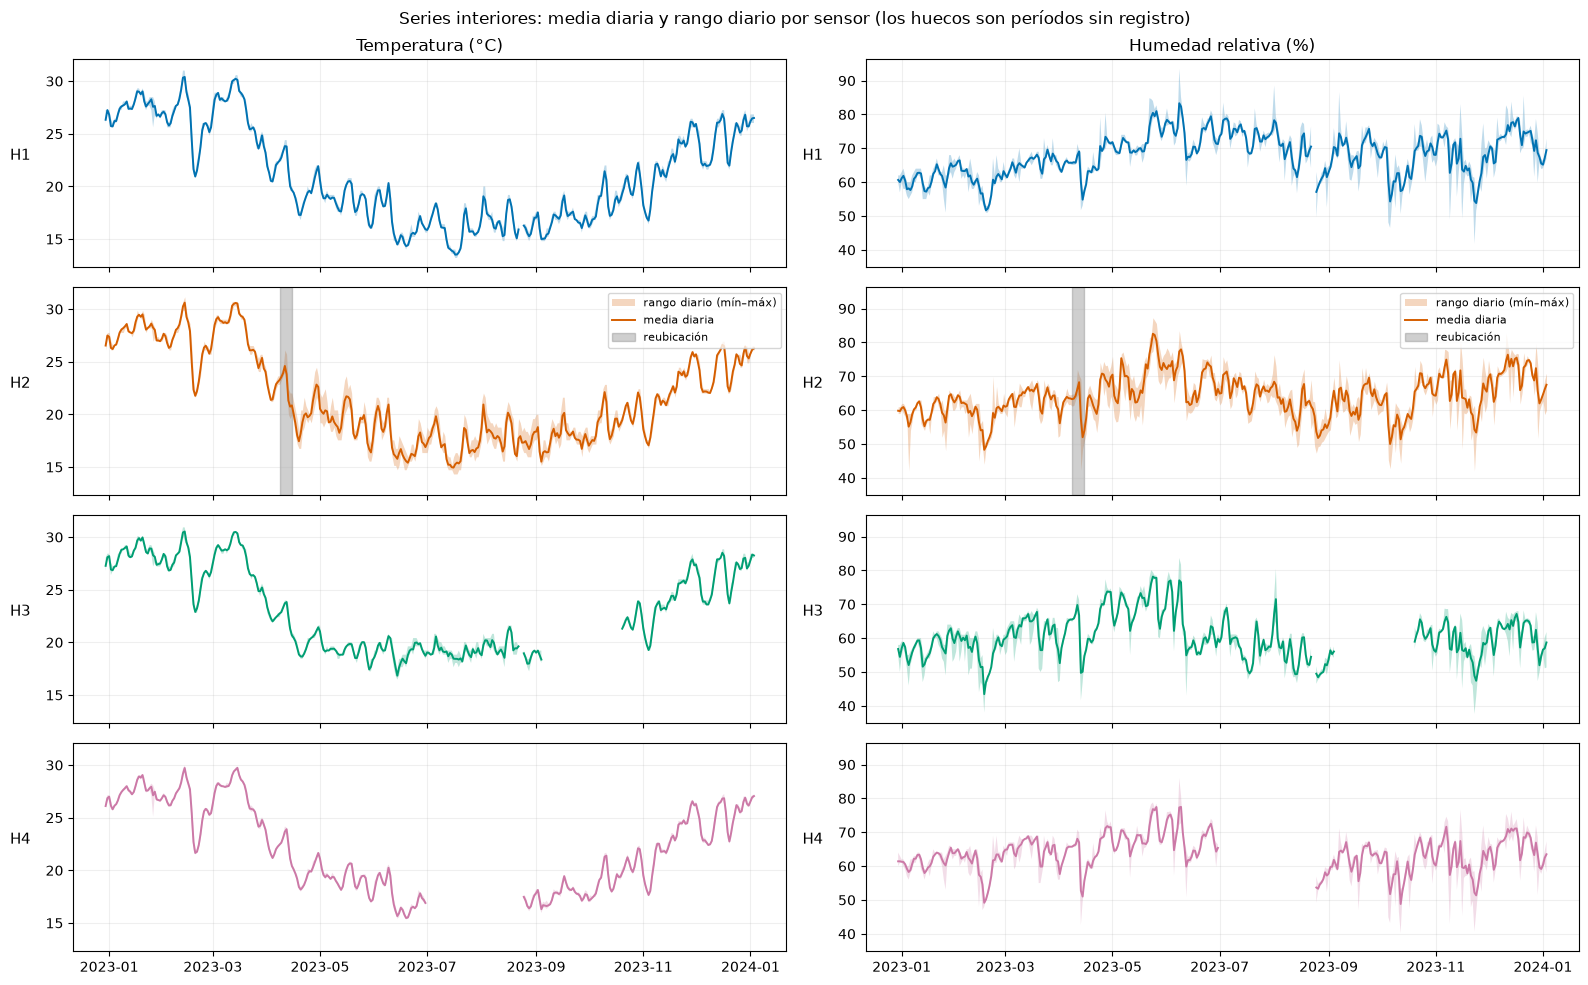

In [8]:
reubicacion_panorama = pd.read_csv('../data/metadata/eventos_conocidos.csv').query("tipo == 'cambio_ubicacion'").iloc[0]
ventana_h2_panorama = (
    pd.Timestamp(reubicacion_panorama['inicio']),
    pd.Timestamp(reubicacion_panorama['fin']) + pd.Timedelta(hours=23),
)

variables_panorama = {
    'Temperatura (°C)': TEMP_INTERIOR,
    'Humedad relativa (%)': HR_INTERIOR,
}
fig, ejes = plt.subplots(len(HOBOS), 2, figsize=(16, 10), sharex=True, sharey='col')

for j, (etiqueta, columnas) in enumerate(variables_panorama.items()):
    for fila, (hobo, columna) in enumerate(zip(HOBOS, columnas)):
        ax = ejes[fila, j]
        diario = df[columna].resample('D')
        completo = diario.count() >= 20
        media = diario.mean().where(completo)
        ax.fill_between(
            media.index,
            diario.min().where(completo),
            diario.max().where(completo),
            color=COLORES[hobo], alpha=0.25, linewidth=0,
            label='rango diario (mín–máx)',
        )
        ax.plot(media.index, media, color=COLORES[hobo], linewidth=1.4, label='media diaria')
        if hobo == 'H2':
            ax.axvspan(*ventana_h2_panorama, color='#777777', alpha=0.35, label='reubicación')
            ax.legend(loc='upper right', fontsize=8)
        ax.set_ylabel(hobo, rotation=0, labelpad=18, fontsize=11)
        ax.grid(alpha=0.2)
        if fila == 0:
            ax.set_title(etiqueta)

fig.suptitle('Series interiores: media diaria y rango diario por sensor (los huecos son períodos sin registro)')
plt.tight_layout()
plt.show()


La inspección anual deja cuatro rasgos que condicionan el análisis:

- **H3 y H4 tienen interrupciones largas:** H4 en julio–agosto y H3 en septiembre–octubre (sección 1.3).
- **H2 cambia en abril.** Después de la reubicación documentada, su rango diario de temperatura se ensancha (sección 1.5).
- **La época del año domina.** La temperatura pasa de 28–30 °C entre enero y marzo a 15–18 °C entre junio y agosto en todos los puntos, y la HR sube hacia mayo–junio; comparar medias de períodos distintos confundiría diferencia espacial con diferencia estacional (secciones 2.1 y 3.2).

### 1.3 Cobertura y completitud

> **Pregunta rectora:** ¿qué partes del año tienen información suficiente para respaldar comparaciones temporales y espaciales?

La disponibilidad se basa en las banderas `*_disponible` construidas previamente en el notebook 01, donde se definió que un HOBO se considera disponible cuando temperatura y humedad relativa están presentes simultáneamente.

Se revisan dos escalas:

- **disponibilidad mensual**, para localizar pérdidas prolongadas de información
- **completitud diaria**, para distinguir días completos, incompletos y sin observaciones

In [9]:
disponibilidad_mensual = df[DISPONIBILIDAD_COLS].resample('MS').mean().mul(100)
disponibilidad_mensual.index = disponibilidad_mensual.index.to_period('M')
disponibilidad_mensual.columns = HOBOS
mostrar('Disponibilidad mensual (%):', disponibilidad_mensual, 2)


Disponibilidad mensual (%):


,H1,H2,H3,H4
fecha,,,,
2022-12,100.00,100.00,100.00,100.00
2023-01,100.00,100.00,100.00,100.00
2023-02,100.00,100.00,100.00,100.00
2023-03,99.87,99.87,99.87,99.87
2023-04,100.00,100.00,100.00,100.00
2023-05,100.00,100.00,100.00,100.00
2023-06,99.86,99.86,99.86,99.86
2023-07,100.00,100.00,100.00,1.75
2023-08,95.83,100.00,95.83,23.52


In [10]:
n_diario = df[DISPONIBILIDAD_COLS].resample('D').sum()
n_diario.columns = HOBOS
completitud = pd.DataFrame({
    'dias_completos': (n_diario == OBS_POR_DIA).sum(),
    'dias_incompletos': ((n_diario > 0) & (n_diario < OBS_POR_DIA)).sum(),
    'dias_sin_dato': (n_diario == 0).sum(),
})
mostrar(f'Días del período: {len(n_diario)}', completitud, None)


Días del período: 372


,dias_completos,dias_incompletos,dias_sin_dato
H1,366,6,0
H2,368,4,0
H3,321,8,43
H4,313,6,53


Se observa que H1 y H2 tienen cobertura prácticamente completa. H4 pierde casi todo julio y agosto, y H3 septiembre y buena parte de octubre (53 y 43 días sin dato, respectivamente). Los huecos se conservan como faltantes y no se imputan. Esto deja en evidencia dos problemas distintos: ausencia de datos y cambio del fenónomeno medido. La ausencia de datos se trata con banderas de disponibilidad y completitud, mientras que el cambio del fenómeno medido se trata con la definición de bloques continuos (sección 1.6).

### 1.4 Contexto documentado del monitoreo

Los eventos documentados en el TFI se incorporan como metadatos del análisis: interrupciones del registro, reubicación de H2, cambios de ocupación y ventilación programada. No se etiquetan a priori como anomalías: se usan para definir unidades y bloques (sección1.6) y, después de la detección, como contexto (sección 6).

In [11]:
eventos = pd.read_csv('../data/metadata/eventos_conocidos.csv')

print('Eventos conocidos del monitoreo y la operación:')
display(
    eventos[[
        'evento',
        'sensor',
        'inicio',
        'fin',
        'tipo',
        'precision_fecha',
        'criterio_fecha',
    ]]
)

Eventos conocidos del monitoreo y la operación:


,evento,sensor,inicio,fin,tipo,precision_fecha,criterio_fecha
0,Interrupción H1 y H3,H1; H3,2023-08-23 10:00,2023-08-24 16:00,interrupcion,horaria,Coincide con el bloque faltante observado en a...
1,Interrupción H3,H3,2023-09-05 18:00,2023-10-19 10:00,interrupcion,horaria,La fecha de inicio consignada en el TFI presen...
2,Interrupción H4,H4,2023-07-01 13:00,2023-08-24 16:00,interrupcion,horaria,Coincide con el bloque faltante observado (130...
3,Reubicación H2,H2,2023-04-08,2023-04-14,cambio_ubicacion,ventana_semanal,Operacionalización de 'segunda semana de abril...
4,Muestra 'Reserva visitable',todos,2023-05-24,2023-12-05,cambio_ocupacion,diaria,Fechas consignadas explícitamente en el TFI.
5,Ventilación programada,todos,2023-03-01,2024-01-04,rutina_operativa,mensual_aproximada,El TFI indica que la rutina comenzó 'a partir ...


### 1.5 Cambio documentado de ubicación: H2

> **Pregunta rectora:** ¿el cambio de ubicación documentado para H2 coincide con un cambio observable en su comportamiento?

El TFI documenta la reubicación de H2 durante la segunda semana de abril de 2023. Dado que no se dispone de una fecha y hora exactas, se utiliza la ventana registrada en `eventos_conocidos.csv`, manteniendo explícita esta incertidumbre temporal.

Para evaluar si la reubicación coincide con un cambio en la serie, se comparan los 30 días anteriores y posteriores a la ventana de transición. Como referencia, se realiza la misma comparación para H1, H3 y H4 durante el mismo período. Esto permite distinguir un cambio particular de H2 de variaciones contemporáneas que pudieran afectar al conjunto de la reserva.

El análisis es descriptivo y no permite atribuir causalidad a la reubicación. Sin embargo, al tratarse del mismo instrumento antes y después del cambio, una modificación de H2 que no se observe de manera comparable en los restantes sensores constituye evidencia para considerar ambos períodos como unidades de análisis diferentes.

In [12]:
VENTANA_DIAS = 30
reubicacion = eventos.loc[eventos['evento'] == 'Reubicación H2'].iloc[0]
trans_inicio = pd.Timestamp(reubicacion['inicio'])
trans_fin = fin_de_dia(reubicacion['fin'], pd.Timedelta(seconds=1))
pre_inicio = trans_inicio - pd.Timedelta(days=VENTANA_DIAS)
pre_fin = trans_inicio - pd.Timedelta(seconds=1)
post_inicio = trans_fin.normalize() + pd.Timedelta(days=1)
post_fin = post_inicio + pd.Timedelta(days=VENTANA_DIAS) - pd.Timedelta(seconds=1)
print(
    f'Pre        : {pre_inicio.date()} a {pre_fin.date()}\n'
    f'Transición : {trans_inicio.date()} a {trans_fin.date()}   '
    f'(ventana operacionalizada)\n'
    f'Post       : {post_inicio.date()} a {post_fin.date()}'
)


Pre        : 2023-03-09 a 2023-04-07
Transición : 2023-04-08 a 2023-04-14   (ventana operacionalizada)
Post       : 2023-04-15 a 2023-05-14


In [13]:
VARIABLES_PRE_POST = {
    'Temperatura': {
        'columnas': TEMP_INTERIOR,
        'titulo_grafico': 'Amplitud térmica diaria: 30 días antes y después de la reubicación',
        'ylabel': 'Máximo - mínimo diario (°C)',
    },
    'HR': {
        'columnas': HR_INTERIOR,
        'titulo_grafico': 'Amplitud diaria de HR: 30 días antes y después de la reubicación',
        'ylabel': 'Máximo - mínimo diario (puntos de HR)',
    },
}


def comparar_amplitud_pre_post(columnas):
    resumen_pre = resumen_diario(df.loc[pre_inicio:pre_fin, columnas])
    resumen_post = resumen_diario(df.loc[post_inicio:post_fin, columnas])

    amplitud_pre = resumen_pre['amplitud'].where(resumen_pre['n'] == OBS_POR_DIA)
    amplitud_post = resumen_post['amplitud'].where(resumen_post['n'] == OBS_POR_DIA)

    amplitudes = pd.concat(
        {'pre': amplitud_pre, 'post': amplitud_post},
        names=['periodo'],
    ).stack().rename('amplitud').reset_index()

    amplitudes.columns = ['periodo', 'fecha', 'sensor', 'amplitud']

    medianas = (
        amplitudes.groupby(['sensor', 'periodo'])['amplitud']
        .median()
        .unstack()[['pre', 'post']]
    )

    medianas.index = medianas.index.map(dict(zip(columnas, HOBOS)))
    medianas.index.name = 'sensor'
    medianas['cambio'] = medianas['post'] - medianas['pre']

    return {
        'pre': amplitud_pre,
        'post': amplitud_post,
        'amplitudes': amplitudes,
        'medianas': medianas,
    }


comparacion_reubicacion = {
    variable: comparar_amplitud_pre_post(config['columnas'])
    for variable, config in VARIABLES_PRE_POST.items()
}

In [14]:
resumen_reubicacion = pd.concat(
    {
        variable: resultado['medianas']
        for variable, resultado in comparacion_reubicacion.items()
    },
    names=['variable', 'sensor'],
)

mostrar(
    'Resumen conjunto de amplitud diaria antes y después de la reubicación:',
    resumen_reubicacion.round(2),
    3,
)

Resumen conjunto de amplitud diaria antes y después de la reubicación:


periodo              pre  post  cambio
variable    sensor                    
Temperatura H1      0.42  0.41   -0.01
            H2      0.81  2.44    1.62
            H3      0.40  0.40   -0.00
            H4      0.45  0.42   -0.03
HR          H1      1.90  1.65   -0.25
            H2      3.00  9.35    6.35
            H3      3.20  2.10   -1.10
            H4      2.20  1.65   -0.55

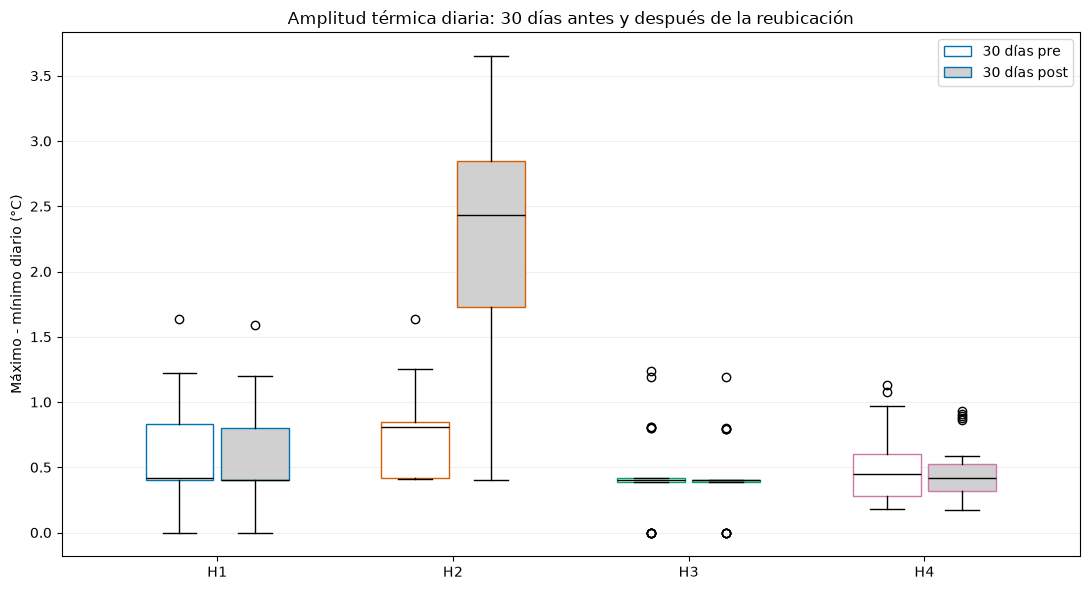

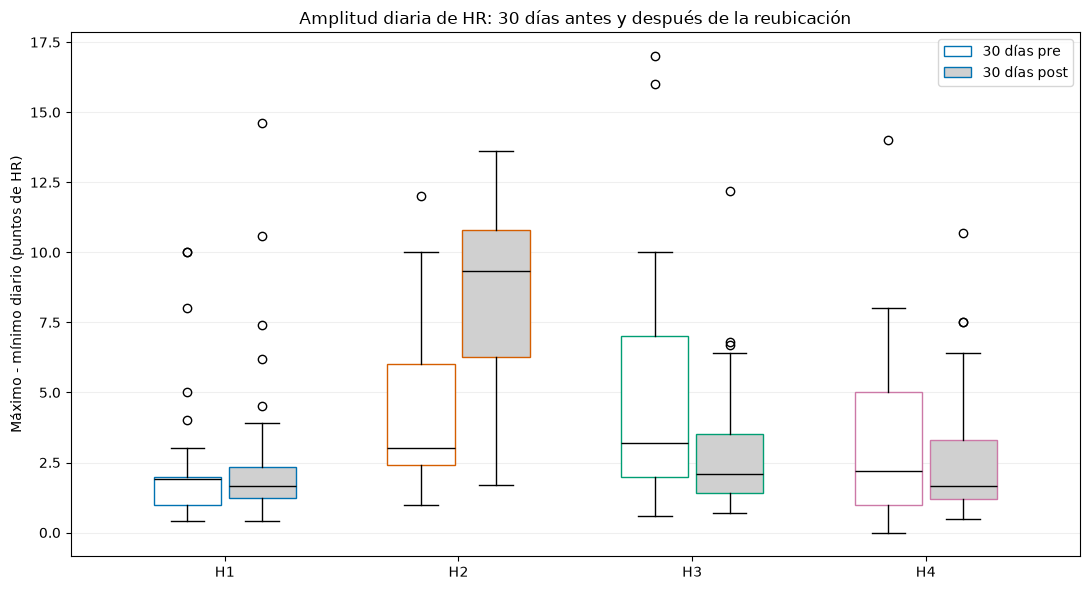

In [15]:
def graficar_amplitud_pre_post(amplitud_pre, amplitud_post, columnas, titulo, ylabel):
    posiciones = np.arange(len(columnas))
    ancho = 0.32

    with figura(
        titulo,
        ylabel=ylabel,
        figsize=(11, 6),
        leyenda={},
        grid=None,
    ) as ax:
        for desplazamiento, tabla, etiqueta, relleno in [
            (-ancho / 2, amplitud_pre, '30 días pre', 'white'),
            (ancho / 2, amplitud_post, '30 días post', '#D0D0D0'),
        ]:
            cajas = ax.boxplot(
                [tabla[col].dropna().values for col in columnas],
                positions=posiciones + desplazamiento,
                widths=ancho * 0.9,
                patch_artist=True,
                medianprops={'color': 'black'},
            )

            for caja, col in zip(cajas['boxes'], columnas):
                caja.set_facecolor(relleno)
                caja.set_edgecolor(color_de(col))

            cajas['boxes'][0].set_label(etiqueta)

        ax.set_xticks(posiciones)
        ax.set_xticklabels(HOBOS)
        ax.grid(axis='y', alpha=0.2)


graficar_amplitud_pre_post(
    comparacion_reubicacion['Temperatura']['pre'],
    comparacion_reubicacion['Temperatura']['post'],
    TEMP_INTERIOR,
    VARIABLES_PRE_POST['Temperatura']['titulo_grafico'],
    VARIABLES_PRE_POST['Temperatura']['ylabel'],
)

graficar_amplitud_pre_post(
    comparacion_reubicacion['HR']['pre'],
    comparacion_reubicacion['HR']['post'],
    HR_INTERIOR,
    VARIABLES_PRE_POST['HR']['titulo_grafico'],
    VARIABLES_PRE_POST['HR']['ylabel'],
)

La comparación local antes/después muestra un cambio marcado en H2 que no aparece con la misma magnitud en los demás sensores. En temperatura, la amplitud diaria mediana de H2 pasa de aproximadamente 0,81 °C antes de la reubicación a 2,44 °C después, mientras H1, H3 y H4 permanecen prácticamente estables.

En HR el contraste es aún más marcado: la amplitud diaria mediana de H2 aumenta de 3,0 a 9,35 puntos, mientras disminuye en los otros tres sensores durante la misma comparación temporal.
Este constraste respalda la decisión de tratar H2-1 y H2-2 como unidades de análisis separadas. La comparación es descriptiva, por lo que no permite atribuir el cambio observado exclusivamente a la reubicación, aunque sí muestra que ambos períodos no resultan directamente comparables como una única condición de medición.

### 1.6 Unidades de análisis y bloques continuos

Una interrupción del registro no implica por sí sola que el sensor pase a representar otro fenómeno. Por eso se distinguen dos niveles:

- **unidad de análisis:** condición física de medición que se interpreta y modela con parámetros comunes. H1, H3 y H4 constituyen una unidad cada uno; H2 se divide en H2-1 y H2-2 por la reubicación documentada (sección 1.5).
- **bloque continuo:** intervalo sin interrupciones largas.

Esta convención rige todo el notebook: los resúmenes y parámetros se calculan **por unidad**, con todas sus observaciones válidas, mientras que las operaciones que requieren adyacencia temporal (cambios a $h$ horas, STL, ACF/PACF, recursión GARCH) se calculan o reinician **por bloque**. Los huecos se conservan como faltantes y nunca se atraviesan.

In [16]:
UMBRAL_HUECO_HORAS = 48
DIAS_MINIMOS_BLOQUE = 30

ventanas_descartadas = {
    fila['sensor']: (pd.Timestamp(fila['inicio']), fin_de_dia(fila['fin']))
    for _, fila in eventos.iterrows()
    if fila['tipo'] == 'cambio_ubicacion'
}

bloques = []
limite_hueco = pd.Timedelta(hours=UMBRAL_HUECO_HORAS)

for hobo in HOBOS:
    usable = df[f'{hobo}_disponible'].copy()
    if hobo in ventanas_descartadas:
        inicio_v, fin_v = ventanas_descartadas[hobo]
        usable.loc[inicio_v:fin_v] = False

    horas = df.index[usable]
    if len(horas) == 0:
        continue

    cortes = [(a, b) for a, b in zip(horas[:-1], horas[1:]) if b - a > limite_hueco]
    inicios = [horas[0]] + [b for _, b in cortes]
    fines = [a for a, _ in cortes] + [horas[-1]]

    for nro, (inicio, fin) in enumerate(zip(inicios, fines), start=1):
        horas_posibles = int((fin - inicio) / pd.Timedelta(hours=1)) + 1
        horas_disponibles = int(usable.loc[inicio:fin].sum())
        bloques.append({
            'sensor': hobo,
            'bloque': f'{hobo}-B{nro}',
            'inicio': inicio,
            'fin': fin,
            'dias': int((fin - inicio) / pd.Timedelta(days=1)),
            'horas': horas_disponibles,
            'horas_posibles': horas_posibles,
            'cobertura_pct': round(100 * horas_disponibles / horas_posibles, 2),
        })

bloques_tecnicos = pd.DataFrame(bloques).set_index('bloque')
bloques_analizables = bloques_tecnicos.loc[bloques_tecnicos['dias'] >= DIAS_MINIMOS_BLOQUE].copy()

# La unidad depende de la condición física de medición, no de cada hueco técnico.
unidades = []
for _, fila in bloques_analizables.iterrows():
    sensor = fila['sensor']
    if sensor != 'H2':
        unidad = sensor
    else:
        inicio_v, fin_v = ventanas_descartadas['H2']
        unidad = 'H2-1' if fila['fin'] < inicio_v else ('H2-2' if fila['inicio'] > fin_v else pd.NA)
    unidades.append(unidad)

bloques_analizables['unidad'] = unidades
bloques_analizables = bloques_analizables.dropna(subset=['unidad'])

filas_unidad = []
for unidad, grupo in bloques_analizables.groupby('unidad', sort=False):
    horas = int(grupo['horas'].sum())
    horas_posibles = int(grupo['horas_posibles'].sum())
    filas_unidad.append({
        'unidad': unidad,
        'sensor': grupo['sensor'].iloc[0],
        'inicio': grupo['inicio'].min(),
        'fin': grupo['fin'].max(),
        'n_bloques': len(grupo),
        'horas': horas,
        'dias_observados': int(horas / 24),
        'cobertura_en_bloques_pct': round(100 * horas / horas_posibles, 2) if horas_posibles else np.nan,
    })

unidades_analisis = pd.DataFrame(filas_unidad).set_index('unidad')
tramos_analizables = unidades_analisis

mostrar('Bloques técnicos continuos:', bloques_analizables, None)
mostrar('Unidades de análisis:', unidades_analisis, None)


Bloques técnicos continuos:


,sensor,inicio,fin,dias,horas,horas_posibles,cobertura_pct,unidad
bloque,,,,,,,,
H1-B1,H1,2022-12-29 14:00:00,2024-01-04 14:00:00,371,8872,8905,99.63,H1
H2-B1,H2,2022-12-29 14:00:00,2023-04-07 23:00:00,99,2385,2386,99.96,H2-1
H2-B2,H2,2023-04-15 00:00:00,2024-01-04 14:00:00,264,6350,6351,99.98,H2-2
H3-B1,H3,2022-12-29 14:00:00,2023-09-05 17:00:00,250,5971,6004,99.45,H3
H3-B2,H3,2023-10-19 11:00:00,2024-01-04 14:00:00,77,1852,1852,100.00,H3
H4-B1,H4,2022-12-29 14:00:00,2023-07-01 12:00:00,183,4413,4415,99.95,H4
H4-B2,H4,2023-08-24 17:00:00,2024-01-04 14:00:00,132,3190,3190,100.00,H4


Unidades de análisis:


,sensor,inicio,fin,n_bloques,horas,dias_observados,cobertura_en_bloques_pct
unidad,,,,,,,
H1,H1,2022-12-29 14:00:00,2024-01-04 14:00:00,1,8872,369,99.63
H2-1,H2,2022-12-29 14:00:00,2023-04-07 23:00:00,1,2385,99,99.96
H2-2,H2,2023-04-15 00:00:00,2024-01-04 14:00:00,1,6350,264,99.98
H3,H3,2022-12-29 14:00:00,2024-01-04 14:00:00,2,7823,325,99.58
H4,H4,2022-12-29 14:00:00,2024-01-04 14:00:00,2,7603,316,99.97


In [17]:
COLUMNA_T = dict(zip(HOBOS, TEMP_INTERIOR))
COLUMNA_HR = dict(zip(HOBOS, HR_INTERIOR))

series_t = {
    unidad: df.loc[fila['inicio']:fila['fin'], COLUMNA_T[fila['sensor']]]
    for unidad, fila in unidades_analisis.iterrows()
}
series_hr = {
    unidad: df.loc[fila['inicio']:fila['fin'], COLUMNA_HR[fila['sensor']]]
    for unidad, fila in unidades_analisis.iterrows()
}


### 1.7 Síntesis

El análisis trabaja con cinco unidades (H1, H2-1, H2-2, H3 y H4), definidas en la sección 1.6. La granularidad de T limita la comparación de cambios pequeños entre H1–H3 y H4 (sección 1.1), y la reubicación de H2 deja una señal observable que justifica separarlo en dos unidades (sección 1.5).

## 2. ¿Cómo varía el ambiente: niveles y fluctuaciones?

Una vez definidos los períodos comparables, la variabilidad ambiental se estudia en dos dimensiones:

1. **nivel:** dónde se sitúa T o HR en cada punto de medición;
2. **fluctuación:** cuánto cambia T o HR dentro de un día o entre dos instantes separados por varias horas.

Dos sensores pueden mantener niveles distintos y, sin embargo, fluctuar de forma parecida. También puede ocurrir lo contrario: registrar niveles semejantes pero mostrar dinámicas muy diferentes.

La sección comienza comparando puntos en los mismos instantes para evitar confundir espacio con época del año y luego cuantifica cuánto se mueven las series a diferentes escalas temporales.

### 2.1 Diferencias contemporáneas entre puntos de medición

> **Pregunta rectora:** cuando dos sensores están observando al mismo tiempo, ¿uno tiende a registrar condiciones sistemáticamente más cálidas, frías, húmedas o secas que otro?

Para cada par de puntos se calcula, en las horas compartidas,

$$
D_t = X_{i,t} - X_{j,t}.
$$
Trabajar con observaciones simultáneas permite comparar los puntos bajo un mismo contexto temporal y evita confundir diferencias entre ubicaciones con cambios estacionales o de largo plazo.

H1 se utiliza únicamente como referencia descriptiva, debido a su ubicación estable y su alta cobertura temporal.

Las diferencias pareadas se resumen mensualmente mediante la mediana. Para H2 se excluye abril de 2023 del resumen mensual, ya que el mes está atravesado por la reubicación y combina mediciones correspondientes a dos ubicaciones distintas.

In [18]:
df_mensual = df.copy()
for hobo, (inicio_v, fin_v) in ventanas_descartadas.items():
    meses_transicion = pd.period_range(inicio_v.to_period('M'), fin_v.to_period('M'), freq='M')
    afectados = df.index.to_period('M').isin(meses_transicion)
    df_mensual.loc[afectados, [COLUMNA_T[hobo], COLUMNA_HR[hobo]]] = np.nan


In [19]:
def diferencias_mensuales_vs_referencia(columnas, referencia='H1', cobertura_minima=COBERTURA_MINIMA_MENSUAL):
    """
    Compara cada sensor con una referencia usando SOLO horas contemporáneas.

    Primero calcula la diferencia horaria pareada y recién después resume
    esas diferencias por mes. Así no se resta simplemente una mediana mensual
    de otra.

    Los meses parciales o con cobertura conjunta insuficiente quedan marcados
    como no válidos.
    """
    tabla = df_mensual[columnas].copy()
    tabla.columns = HOBOS
    filas = []
    meses = pd.period_range(tabla.index.min().to_period('M'), tabla.index.max().to_period('M'), freq='M')
    for mes in meses:
        mascara_mes = tabla.index.to_period('M') == mes
        esperado = mes.days_in_month * 24
        for sensor in HOBOS:
            if sensor == referencia:
                continue
            pares = tabla.loc[mascara_mes, [sensor, referencia]].dropna()
            n = len(pares)
            cobertura = 100 * n / esperado
            if n > 0:
                diferencia = pares[sensor] - pares[referencia]
                mediana = diferencia.median()
                media = diferencia.mean()
                q25 = diferencia.quantile(0.25)
                q75 = diferencia.quantile(0.75)
            else:
                mediana = media = q25 = q75 = np.nan
            filas.append({
                'mes': mes,
                'sensor': sensor,
                'referencia': referencia,
                'comparacion': f'{sensor} - {referencia}',
                'n_pares': n,
                'cobertura_conjunta_pct': cobertura,
                'mediana_diferencia': mediana,
                'media_diferencia': media,
                'q25': q25,
                'q75': q75,
                'valido': cobertura >= cobertura_minima,
            })
    return pd.DataFrame(filas)

diferencias_temp_h1 = diferencias_mensuales_vs_referencia(TEMP_INTERIOR, referencia='H1')
diferencias_hr_h1 = diferencias_mensuales_vs_referencia(HR_INTERIOR, referencia='H1')
mostrar(
    'Diferencia mensual pareada de temperatura respecto de H1 (°C):',
    diferencias_temp_h1.loc[diferencias_temp_h1['valido']].pivot(index='mes', columns='comparacion', values='mediana_diferencia').sort_index(),
    2,
)
mostrar(
    'Diferencia mensual pareada de HR respecto de H1 (puntos porcentuales):',
    diferencias_hr_h1.loc[diferencias_hr_h1['valido']].pivot(index='mes', columns='comparacion', values='mediana_diferencia').sort_index(),
    2,
)


Diferencia mensual pareada de temperatura respecto de H1 (°C):


comparacion,H2 - H1,H3 - H1,H4 - H1
mes,,,
2023-01,0.53,0.77,-0.10
2023-02,0.52,0.78,-0.09
2023-03,0.55,0.76,-0.13
2023-04,NaN,0.81,0.37
2023-05,0.41,0.80,0.48
2023-06,0.77,2.82,0.90
2023-07,1.16,3.21,NaN
2023-08,1.18,2.81,NaN
2023-09,0.79,NaN,0.90


Diferencia mensual pareada de HR respecto de H1 (puntos porcentuales):


comparacion,H2 - H1,H3 - H1,H4 - H1
mes,,,
2023-01,-1.00,-3.0,1.00
2023-02,-2.00,-4.0,0.00
2023-03,-2.00,-2.0,0.00
2023-04,NaN,-1.1,-1.40
2023-05,-1.90,-2.2,-3.50
2023-06,-4.50,-11.8,-6.10
2023-07,-7.80,-15.7,NaN
2023-08,-7.50,-12.5,NaN
2023-09,-6.40,NaN,-6.90


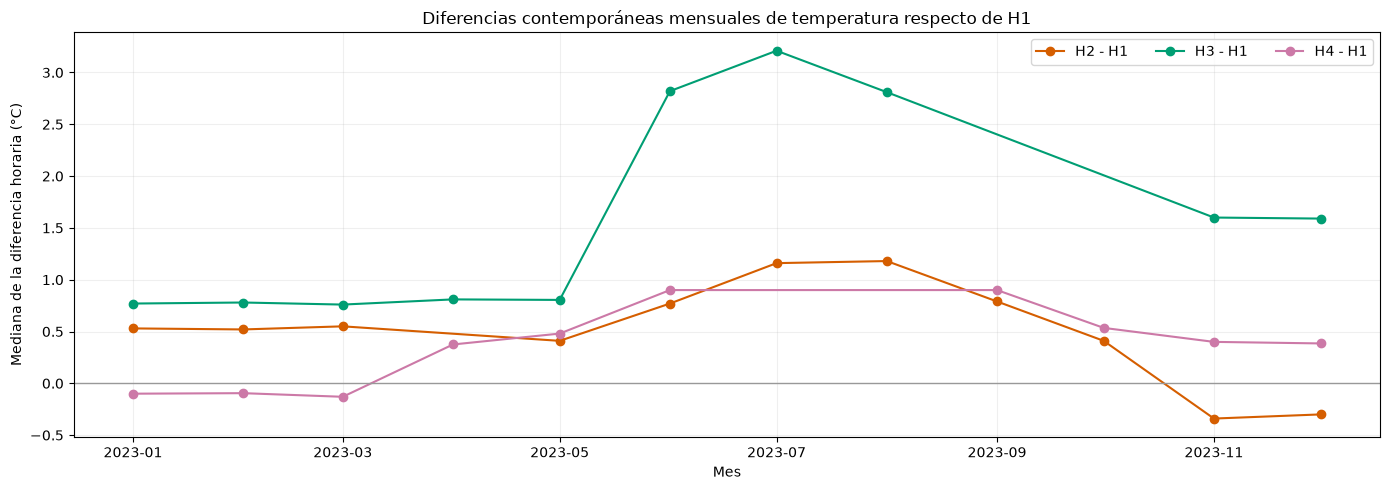

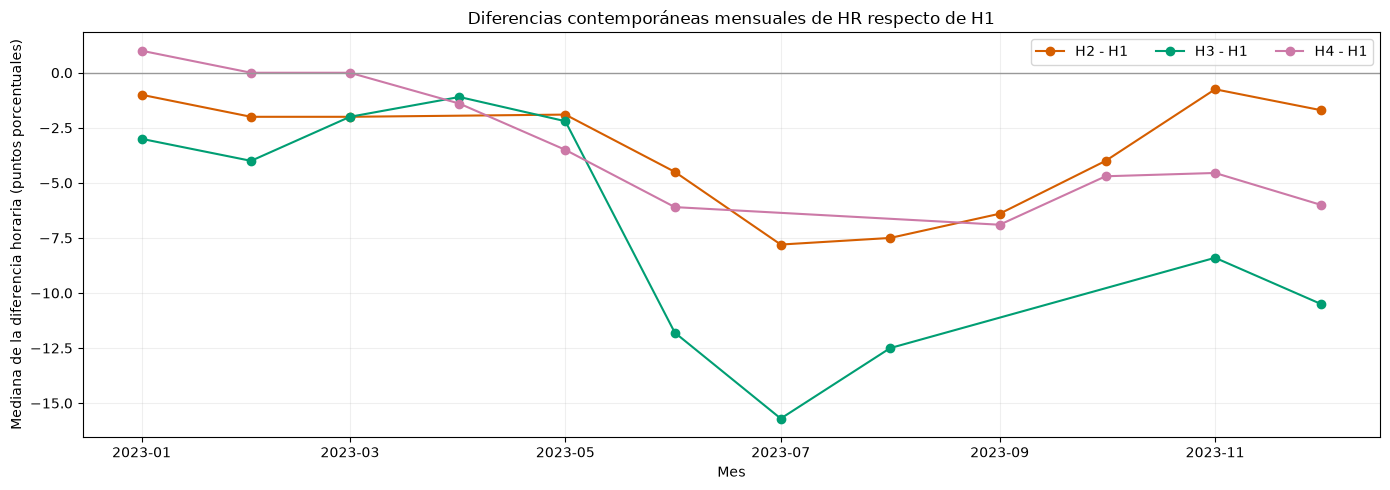

In [20]:
def graficar_diferencias_mensuales(resultado, titulo, ylabel):
    validos = resultado.loc[resultado['valido']].copy()
    referencia = validos['referencia'].iloc[0]
    with figura(titulo, 'Mes', ylabel, figsize=(14, 5), leyenda=dict(ncol=3), cero=True) as ax:
        for sensor in [h for h in HOBOS if h != referencia]:
            sub = validos.loc[validos['sensor'] == sensor].sort_values('mes')
            ax.plot(
                sub['mes'].dt.to_timestamp(),
                sub['mediana_diferencia'],
                marker='o',
                label=f'{sensor} - {referencia}',
                color=COLORES[sensor],
            )
graficar_diferencias_mensuales(
    diferencias_temp_h1,
    'Diferencias contemporáneas mensuales de temperatura respecto de H1',
    'Mediana de la diferencia horaria (°C)',
)
graficar_diferencias_mensuales(
    diferencias_hr_h1,
    'Diferencias contemporáneas mensuales de HR respecto de H1',
    'Mediana de la diferencia horaria (puntos porcentuales)',
)


Se puede observar que las diferencias entre sensores no son constantes a lo largo del año. En temperatura, H3 se mantiene por encima de H1 durante buena parte del período y la separación aumenta especialmente en invierno, llegando a alrededor de **3 °C** en julio. En HR ocurre el patrón opuesto: H1 registra valores sistemáticamente más altos que H3 y H4 durante varios meses, con diferencias particularmente marcadas entre junio y agosto.

En conjunto, las diferencias entre puntos no pueden representarse como un desplazamiento constante entre series: su magnitud cambia a lo largo del año. Esta heterogeneidad temporal entre ubicaciones se conserva en los análisis posteriores.

### 2.2 Fluctuaciones

> **Pregunta rectora:** además de estar en niveles distintos, ¿cuánto cambia el ambiente y en qué escala temporal ocurre ese cambio?

La fluctuación se estudia de dos maneras complementarias:

- **amplitud diaria:** recorrido entre el máximo y el mínimo de un día completo;
- **cambios a distintos horizontes:** cuánto se separa una observación del valor registrado 1, 3, 6, 12 o 24 horas antes.

Esta distinción permite separar un punto que es sistemáticamente más cálido o seco de un punto que, además, se mueve más dentro del tiempo.

#### 2.2.1 Amplitud diaria por unidad

> **Pregunta rectora:** dentro de un día completo, ¿qué recorrido típico presenta cada variable en cada unidad?

La amplitud diaria se define como máximo menos mínimo. Sólo se calcula para días con las 24 observaciones horarias, de este modo una amplitud pequeña no es consecuencia de haber observado únicamente una fracción del día.

In [21]:
def amplitud_diaria_unidad(unidad, columnas):
    fila = unidades_analisis.loc[unidad]
    col = columnas[fila['sensor']]
    resumen = resumen_diario(df.loc[fila['inicio']:fila['fin'], [col]])
    return resumen['amplitud'][col].where(resumen['n'][col] == OBS_POR_DIA)
amplitud_t_tramo = {unidad: amplitud_diaria_unidad(unidad, COLUMNA_T) for unidad in unidades_analisis.index}
amplitud_hr_tramo = {unidad: amplitud_diaria_unidad(unidad, COLUMNA_HR) for unidad in unidades_analisis.index}
resumen_amplitud = pd.DataFrame({
    'dias_completos': {
        tramo: int(serie.notna().sum())
        for tramo, serie in amplitud_t_tramo.items()
    },
    'T_mediana': {
        tramo: serie.median()
        for tramo, serie in amplitud_t_tramo.items()
    },
    'HR_mediana': {
        tramo: serie.median()
        for tramo, serie in amplitud_hr_tramo.items()
    },
})
resumen_amplitud.index.name = 'unidad'
mostrar('Amplitud diaria mediana por unidad (solo días completos):', resumen_amplitud, 2)


Amplitud diaria mediana por unidad (solo días completos):


,dias_completos,T_mediana,HR_mediana
unidad,,,
H1,366,0.80,3.0
H2-1,98,0.43,3.0
H2-2,263,1.61,6.1
H3,321,0.41,3.4
H4,313,0.45,3.0


H2-2 presentó las mayores amplitudes diarias medianas en ambas variables, de acuerdo con las diferencias observadas alrededor del traslado. Entre los demás equipos también aparecieron contrastes: H1 registró mayores amplitudes térmicas que H3 y H4, mientras que sus amplitudes de HR fueron semejantes.

#### 2.2.2 Cambios observados a diferentes horizontes

> **Pregunta rectora:** ¿con qué rapidez se separan las condiciones actuales de las registradas unas horas antes?

Se calcula

$$
\Delta_h X_t = X_t - X_{t-h},
$$

para $h = 1, 3, 6, 12, 24$ horas.

La lectura principal utiliza la mediana de $|\Delta_h X_t|$, que resume la magnitud típica del cambio en cada horizonte. El percentil 95 se conserva para la evaluación posterior de conservación, mientras que la proporción de cambios exactamente nulos se interpreta con cautela porque está muy condicionada por la granularidad instrumental.

In [22]:
HORIZONTES_CAMBIO = [1, 3, 6, 12, 24]


def cambios_por_horizonte(series):
    filas = []
    for unidad, serie in series.items():
        for horizonte in HORIZONTES_CAMBIO:
            cambios = diferencia_exacta(serie, horizonte)
            abs_cambios = cambios.abs()
            filas.append({
                'unidad': unidad,
                'horizonte_h': horizonte,
                'n': len(cambios),
                'pct_cero': 100 * np.isclose(cambios, 0).mean() if len(cambios) else np.nan,
                'mediana_abs': abs_cambios.median() if len(cambios) else np.nan,
                'p95_abs': abs_cambios.quantile(0.95) if len(cambios) else np.nan,
            })
    return pd.DataFrame(filas).set_index(['unidad', 'horizonte_h'])


cambios_temp = cambios_por_horizonte(series_t)
cambios_hr = cambios_por_horizonte(series_hr)

mostrar_por_variable(
    'Mediana de |Δh| - {variable}:',
    {
        'T': cambios_temp['mediana_abs'].unstack('horizonte_h').rename(columns=lambda h: f'{h} h'),
        'HR': cambios_hr['mediana_abs'].unstack('horizonte_h').rename(columns=lambda h: f'{h} h'),
    },
    2,
)


Mediana de |Δh| - temperatura:


horizonte_h,1 h,3 h,6 h,12 h,24 h
unidad,,,,,
H1,0.00,0.00,0.00,0.40,0.41
H2-1,0.00,0.00,0.00,0.41,0.42
H2-2,0.00,0.40,0.41,0.80,0.80
H3,0.00,0.00,0.00,0.40,0.40
H4,0.03,0.07,0.12,0.22,0.39


Mediana de |Δh| - humedad relativa:


horizonte_h,1 h,3 h,6 h,12 h,24 h
unidad,,,,,
H1,0.1,0.4,0.8,1.1,1.8
H2-1,0.0,0.6,1.0,1.0,1.0
H2-2,0.3,0.8,1.5,2.4,2.5
H3,0.1,0.4,0.8,1.2,2.0
H4,0.1,0.3,0.7,1.0,1.8


Las fluctuaciones aumentan con la escala temporal, especialmente en HR. El cambio típico pasa de 0,0–0,3 puntos a 1 h a 1,0–2,5 puntos a 24 h, y H2-2 es la unidad con mayor variación en todos los horizontes, alcanzando 2,5 puntos a 24 h.

En T, las medianas de H1, H2-1 y H3 permanecen en cero hasta 6 h porque el cambio típico queda por debajo del escalón de 0,4 °C. H4, con mayor granularidad, registra cambios de 0,03 °C ya a 1 h. H2-2 vuelve a ser la unidad más variable, con 0,40 °C a 3 h y 0,80 °C a 12–24 h.

### 2.3 Síntesis

Hasta este punto aparecen tres resultados distintos:

1. **Existen diferencias espaciales reales en los niveles interiores.** H3, H2 y H4 no mantienen una separación constante respecto de H1, y esas diferencias cambian a lo largo del año.
2. **Nivel y fluctuación no son lo mismo.** H2 después de la reubicación no sólo se ubica en otro contexto, sino que presenta una amplitud intradiaria y cambios a varios horizontes mayores que en la ubicación anterior.
3. **La escala temporal importa.** En especial para HR, una parte importante de la variación se acumula a 12–24 horas; mirar únicamente cambios hora a hora subestimaría la dinámica relevante.

Estas medidas describen cuánto cambia el ambiente, pero todavía mezclan varias fuentes de variación: evolución estacional, ciclo diario, movimientos de corto plazo y perturbaciones no sistemáticas. En la siguiente sección se separan esas fuentes para caracterizar la estructura temporal de las series.

## 3. Estructura temporal de las series

> **Pregunta rectora:** ¿cómo se organiza la variación en el tiempo y qué dependencia queda una vez retiradas las estructuras sistemáticas?

La estructura temporal de cada serie se caracteriza a partir de dimensiones complementarias: la variación intradiaria, la evolución lenta, las periodicidades y la persistencia.

El análisis se organiza en cinco pasos:

1. describir la **forma típica del día**, independientemente del nivel absoluto;
2. observar la **evolución lenta** a escala mensual;
3. separar evolución lenta, ciclo diario y variación remanente mediante **STL**;
4. identificar **periodicidades** recurrentes mediante análisis espectral;
5. estudiar la **persistencia temporal**, comparando la dependencia en niveles con la que permanece en el `remainder`.

En conjunto, estos análisis permiten distinguir la estructura habitual de cada punto de medición de la variación que permanece una vez retirados sus principales patrones temporales.

### 3.1 Forma típica del día

> **Pregunta rectora:** ¿los puntos de medición presentan una oscilación intradiaria reconocible y esa forma cambia entre unidades?

Para comparar la forma del día sin confundirla con diferencias de nivel, a cada observación se le resta la mediana de su propio día. Las desviaciones resultantes se resumen por hora.

Así, la comparación se centra en cómo varía cada serie dentro de un día típico, independientemente de que un sensor registre sistemáticamente valores más altos o más bajos que otro.

El análisis se realiza también por separado para H2-1 y H2-2, con el fin de evaluar si la forma intradiaria cambia después de la reubicación.

In [23]:
def ciclo_intradiario(serie):
    centrada = serie - serie.resample('D').transform('median')
    return pd.DataFrame({'valor': centrada, 'hora': centrada.index.hour}).groupby('hora')['valor'].agg(
        mediana='median',
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        media='mean',
        n='count',
    )

ciclo_temp = {unidad: ciclo_intradiario(serie) for unidad, serie in series_t.items()}
ciclo_hr = {unidad: ciclo_intradiario(serie) for unidad, serie in series_hr.items()}

amplitud_ciclo = pd.DataFrame({
    'temperatura': {u: c['mediana'].max() - c['mediana'].min() for u, c in ciclo_temp.items()},
    'HR': {u: c['mediana'].max() - c['mediana'].min() for u, c in ciclo_hr.items()},
})
mostrar('Amplitud del ciclo intradiario (máximo menos mínimo de la mediana horaria):', amplitud_ciclo)


Amplitud del ciclo intradiario (máximo menos mínimo de la mediana horaria):


,temperatura,HR
H1,0.00,0.15
H2-1,0.00,1.20
H2-2,0.81,1.80
H3,0.00,0.50
H4,0.10,0.45


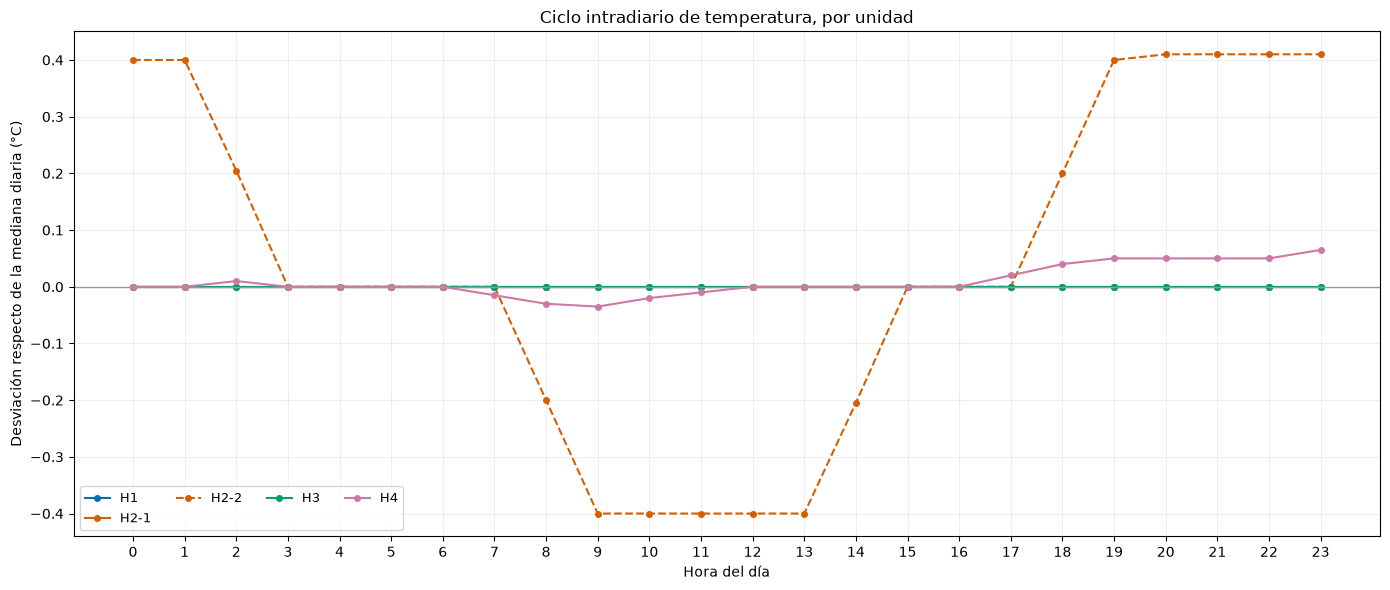

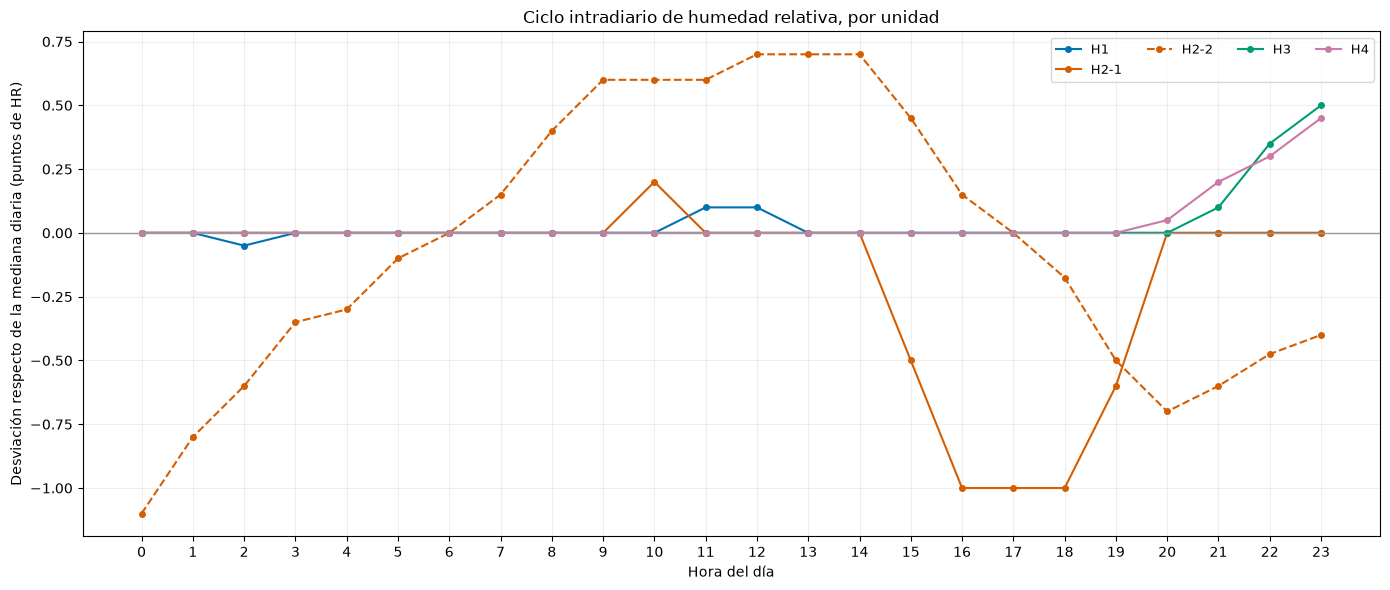

In [24]:
graficar_por_tramo(
    ciclo_temp,
    'mediana',
    'Ciclo intradiario de temperatura, por unidad',
    'Hora del día',
    'Desviación respecto de la mediana diaria (°C)',
    xticks=range(24),
    figsize=(14, 6),
    marker='o',
    markersize=4,
)
graficar_por_tramo(
    ciclo_hr,
    'mediana',
    'Ciclo intradiario de humedad relativa, por unidad',
    'Hora del día',
    'Desviación respecto de la mediana diaria (puntos de HR)',
    xticks=range(24),
    figsize=(14, 6),
    marker='o',
    markersize=4,
)


El ciclo diario típico es pequeño en casi todas las unidades. En T, la amplitud del perfil horario mediano es nula en H1, H2-1 y H3, y de 0,10 °C en H4. En las tres primeras la oscilación queda por debajo del escalón de registro (≈0,4 °C), por lo que una amplitud nula no implica ausencia de variación intradiaria. H2-2 constituye la principal excepción, con una amplitud de 0,81 °C.

En HR, H2-2 presenta la mayor amplitud (1,8 puntos), seguida por H2-1 (1,2), mientras H1, H3 y H4 se ubican entre 0,15 y 0,5 puntos.

En conjunto, H2 muestra una oscilación intradiaria más marcada después de la reubicación, especialmente en temperatura.

### 3.2 Evolución lenta a escala mensual

> **Pregunta rectora:** ¿el nivel típico del ambiente cambia a lo largo del año de manera similar en todos los puntos?

La mediana mensual se utiliza como resumen descriptivo de la evolución lenta, reduciendo la variabilidad de corto plazo para hacer visible la trayectoria general de cada unidad.

In [25]:
meses_validos = disponibilidad_mensual >= COBERTURA_MINIMA_MENSUAL
meses_excluidos = disponibilidad_mensual.where(~meses_validos).dropna(how='all')
mostrar(f'Meses excluidos por cobertura menor a {COBERTURA_MINIMA_MENSUAL}%:', meses_excluidos, 2)


Meses excluidos por cobertura menor a 80%:


,H1,H2,H3,H4
fecha,,,,
2023-07,NaN,NaN,NaN,1.75
2023-08,NaN,NaN,NaN,23.52
2023-09,NaN,NaN,15.83,NaN
2023-10,NaN,NaN,40.46,NaN


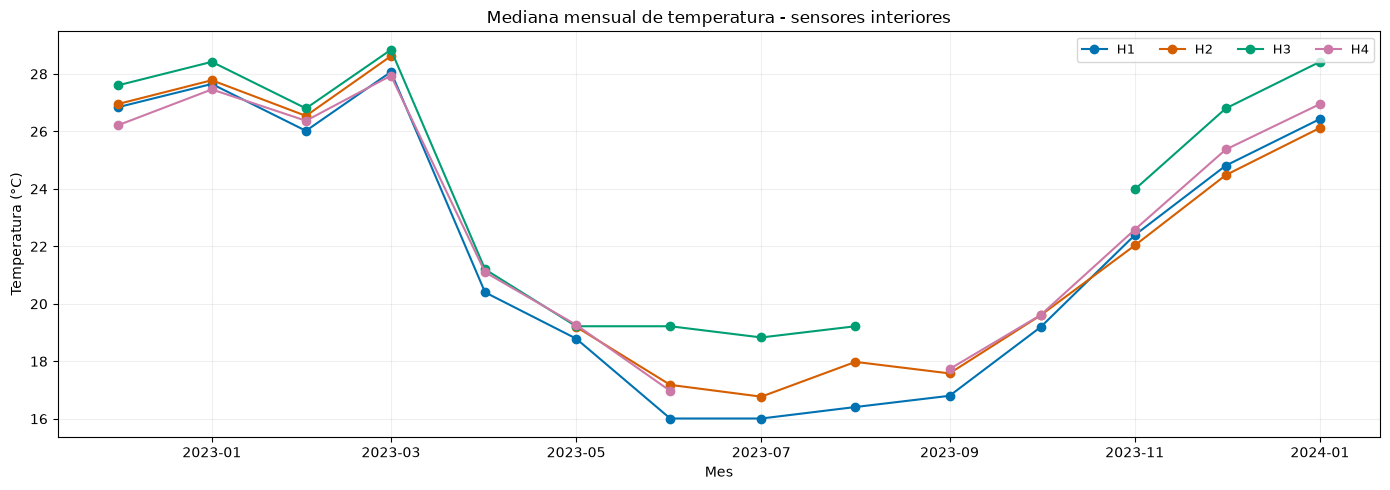

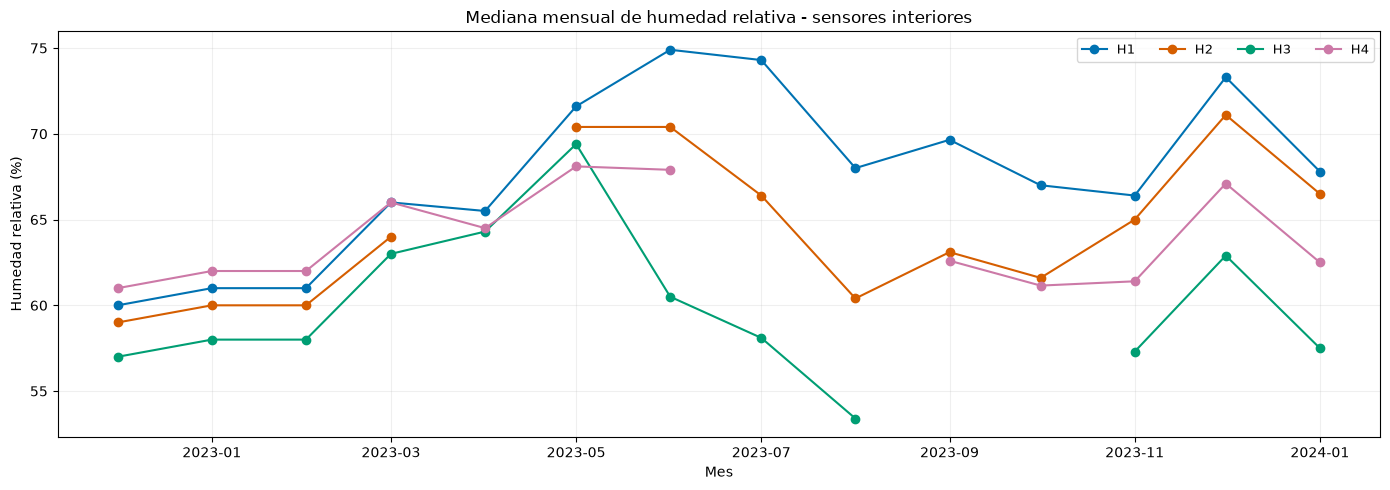

In [26]:
mensuales = {}
for variable, columnas in {'T': TEMP_INTERIOR, 'HR': HR_INTERIOR}.items():
    tabla = df_mensual[columnas].resample('MS').median()
    tabla.index = tabla.index.to_period('M')
    tabla.columns = HOBOS
    mensuales[variable] = tabla.where(meses_validos)

for variable, titulo, ylabel in [
    ('T', 'Mediana mensual de temperatura - sensores interiores', 'Temperatura (°C)'),
    ('HR', 'Mediana mensual de humedad relativa - sensores interiores', 'Humedad relativa (%)'),
]:
    with figura(titulo, 'Mes', ylabel, figsize=(14, 5), leyenda=dict(ncol=4, fontsize=9)) as ax:
        for hobo in HOBOS:
            ax.plot(
                mensuales[variable].index.to_timestamp(),
                mensuales[variable][hobo],
                marker='o', label=hobo, color=COLORES[hobo],
            )


Todos los puntos presentan una trayectoria térmica similar a lo largo del período. La mediana mensual de T alcanza sus valores máximos en marzo (28–29 °C) y mínimos en junio–julio (16–19 °C), con recorridos de aproximadamente 10 a 12 °C. La caída más marcada se observa entre marzo y abril, con descensos de 6,8 a 7,7 °C según la unidad. H3 se mantiene como el punto más cálido durante gran parte del período y la diferencia respecto de H1 se amplía en invierno, alcanzando aproximadamente 3 °C.

En HR, en cambio, las trayectorias se diferencian más entre unidades. Todos los puntos aumentan entre el verano (57–62 %) y mayo (68–72 %), pero luego evolucionan de manera distinta: H1 continúa aumentando hasta aproximadamente 75 % en junio y se mantiene como el punto más húmedo, mientras H3 desciende hasta alrededor de 53 % en agosto. En junio y julio la diferencia entre ambos alcanza aproximadamente 16 puntos. H4 presenta el menor recorrido mensual, con unos 7 puntos frente a 12–16 en las demás unidades. Todos los puntos muestran además un máximo local en diciembre.

### 3.3 Separar escalas temporales con STL

> **Pregunta rectora:** si la serie combina evolución lenta, ciclo diario y variación irregular, ¿podemos separar esas escalas antes de estudiar memoria y eventos inusuales?

Se utiliza la descomposición aditiva:

$$
X_t = T_t + S_t + R_t,
$$

donde:

- $T_t$ representa la **componente lenta**;
- $S_t$ representa una **componente de 24 h**;
- $R_t$ es la variación que queda después de retirar ambas.

La separación responde a una necesidad concreta: un valor no debería considerarse “sorprendente” simplemente porque pertenece al invierno, al verano o a una hora del día que suele ser distinta.

**Decisiones:**

1. El período de 24 h se utiliza porque el análisis intradiario ya mostró una estructura diaria interpretable. El análisis espectral del apartado 3.4 servirá como contraste adicional.
2. La transición verano-invierno-verano se trata como evolución lenta; con aproximadamente un año de datos no se estima una estacionalidad anual repetida.

La formulación STL sigue a Cleveland et al. (1990).

**STL por bloques continuos:** Los huecos documentados no invalidan las observaciones anteriores o posteriores, pero tampoco deben unirse artificialmente. Por este motivo, cada unidad se divide en bloques horarios continuos y STL se ajusta por separado en aquellos con al menos una semana completa de datos. Luego, los componentes se recombinan dentro de cada unidad conservando el índice temporal original.

In [27]:
PERIODO_STL_H = 24
MIN_CICLOS_STL = 7
MIN_OBS_STL = PERIODO_STL_H * MIN_CICLOS_STL


def descomponer_stl(serie, periodo=PERIODO_STL_H):
    """
    Descompone TODOS los bloques horarios continuos suficientemente largos.

    Cada bloque se ajusta de forma independiente. No se imputan faltantes y
    ningún componente se estima atravesando un hueco.

    Devuelve un DataFrame concatenado con:
    - observado
    - tendencia
    - estacional
    - resto
    - bloque_id
    """
    partes = []
    for bloque_id, s in enumerate(bloques_continuos(serie, min_obs=MIN_OBS_STL), start=1):
        ajuste = STL(s, period=periodo, robust=True).fit()
        partes.append(pd.DataFrame({
            'observado': s,
            'tendencia': ajuste.trend,
            'estacional': ajuste.seasonal,
            'resto': ajuste.resid,
            'bloque_id': bloque_id,
        }))
    if not partes:
        return pd.DataFrame(columns=['observado', 'tendencia', 'estacional', 'resto', 'bloque_id'])
    return pd.concat(partes).sort_index()
descomp_temp = {unidad: descomponer_stl(serie) for unidad, serie in series_t.items()}
descomp_hr = {unidad: descomponer_stl(serie) for unidad, serie in series_hr.items()}
residuos_temp = {unidad: resultado['resto'] for unidad, resultado in descomp_temp.items() if not resultado.empty}
residuos_hr = {unidad: resultado['resto'] for unidad, resultado in descomp_hr.items() if not resultado.empty}

def cobertura_stl(series_originales, descomposiciones):
    filas = []
    for unidad, serie in series_originales.items():
        n_original = int(serie.notna().sum())
        n_stl = int(descomposiciones.get(unidad, pd.DataFrame()).shape[0])
        filas.append({
            'unidad': unidad,
            'n_observado_unidad': n_original,
            'n_usado_STL': n_stl,
            'pct_observado_usado_STL': 100 * n_stl / n_original if n_original > 0 else np.nan,
        })
    return pd.DataFrame(filas).set_index('unidad')
print(f'STL calculada para {len(residuos_temp)} unidades de temperatura y {len(residuos_hr)} unidades de humedad relativa.\n')
mostrar_por_variable(
    'Cobertura efectiva de STL - {variable}:',
    {'T': cobertura_stl(series_t, descomp_temp), 'HR': cobertura_stl(series_hr, descomp_hr)},
    2,
)


STL calculada para 5 unidades de temperatura y 5 unidades de humedad relativa.

Cobertura efectiva de STL - temperatura:


,n_observado_unidad,n_usado_STL,pct_observado_usado_STL
unidad,,,
H1,8872,8872,100.0
H2-1,2385,2385,100.0
H2-2,6350,6350,100.0
H3,7823,7823,100.0
H4,7603,7603,100.0


Cobertura efectiva de STL - humedad relativa:


,n_observado_unidad,n_usado_STL,pct_observado_usado_STL
unidad,,,
H1,8872,8872,100.0
H2-1,2385,2385,100.0
H2-2,6350,6350,100.0
H3,7823,7823,100.0
H4,7603,7603,100.0


Lectura de la descomposición. El `remainder` representa la variación que no fue capturada por la evolución lenta ni por el ciclo diario.

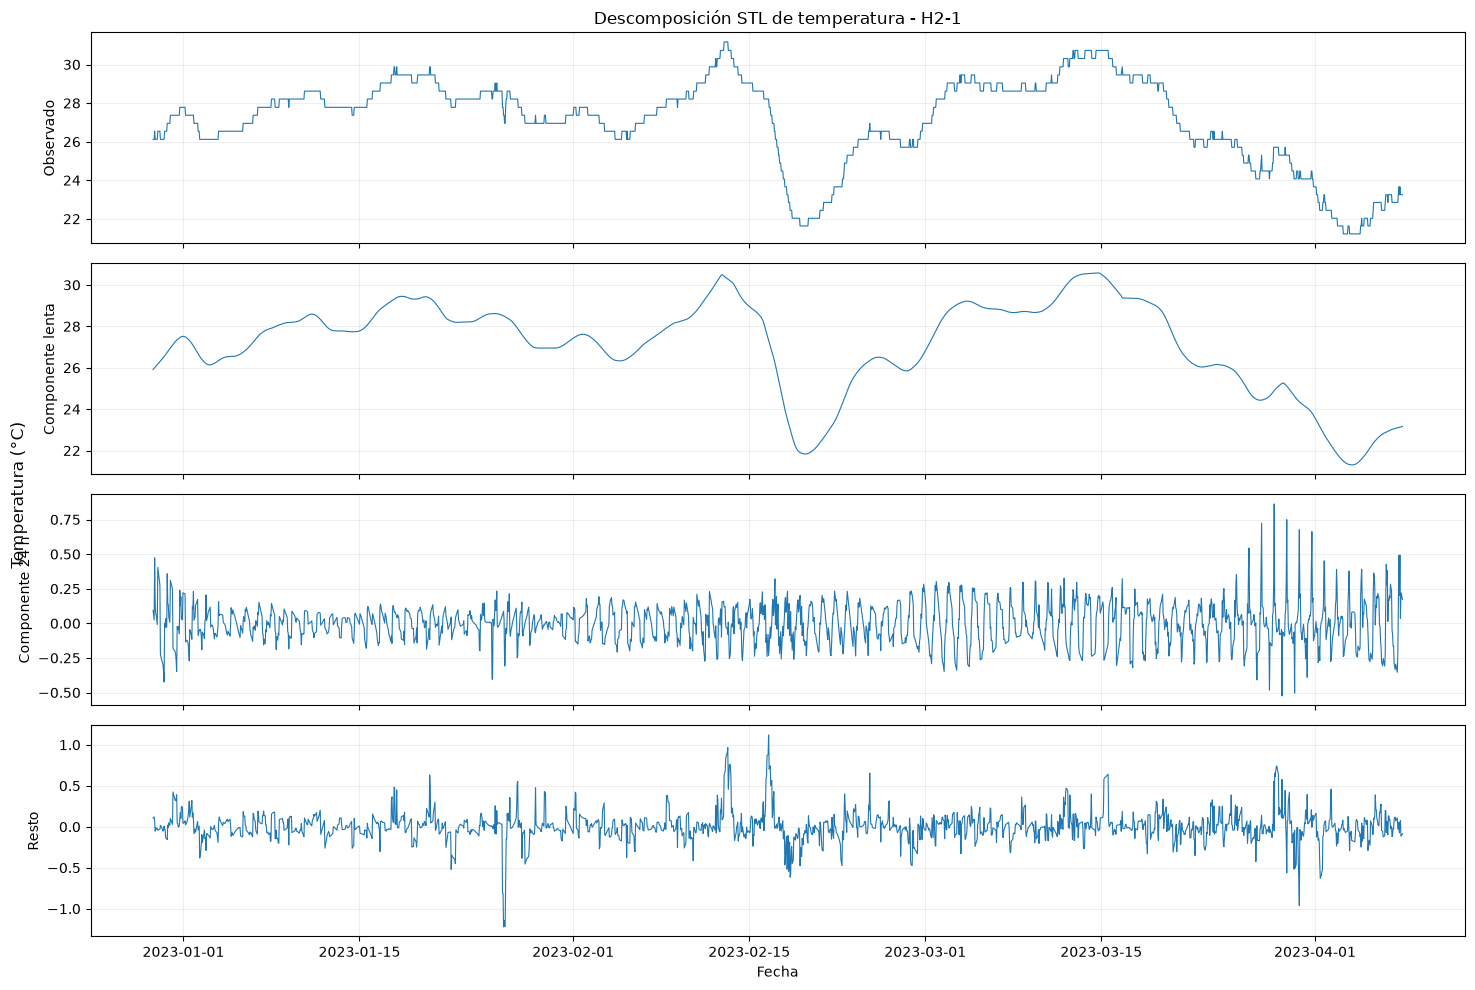

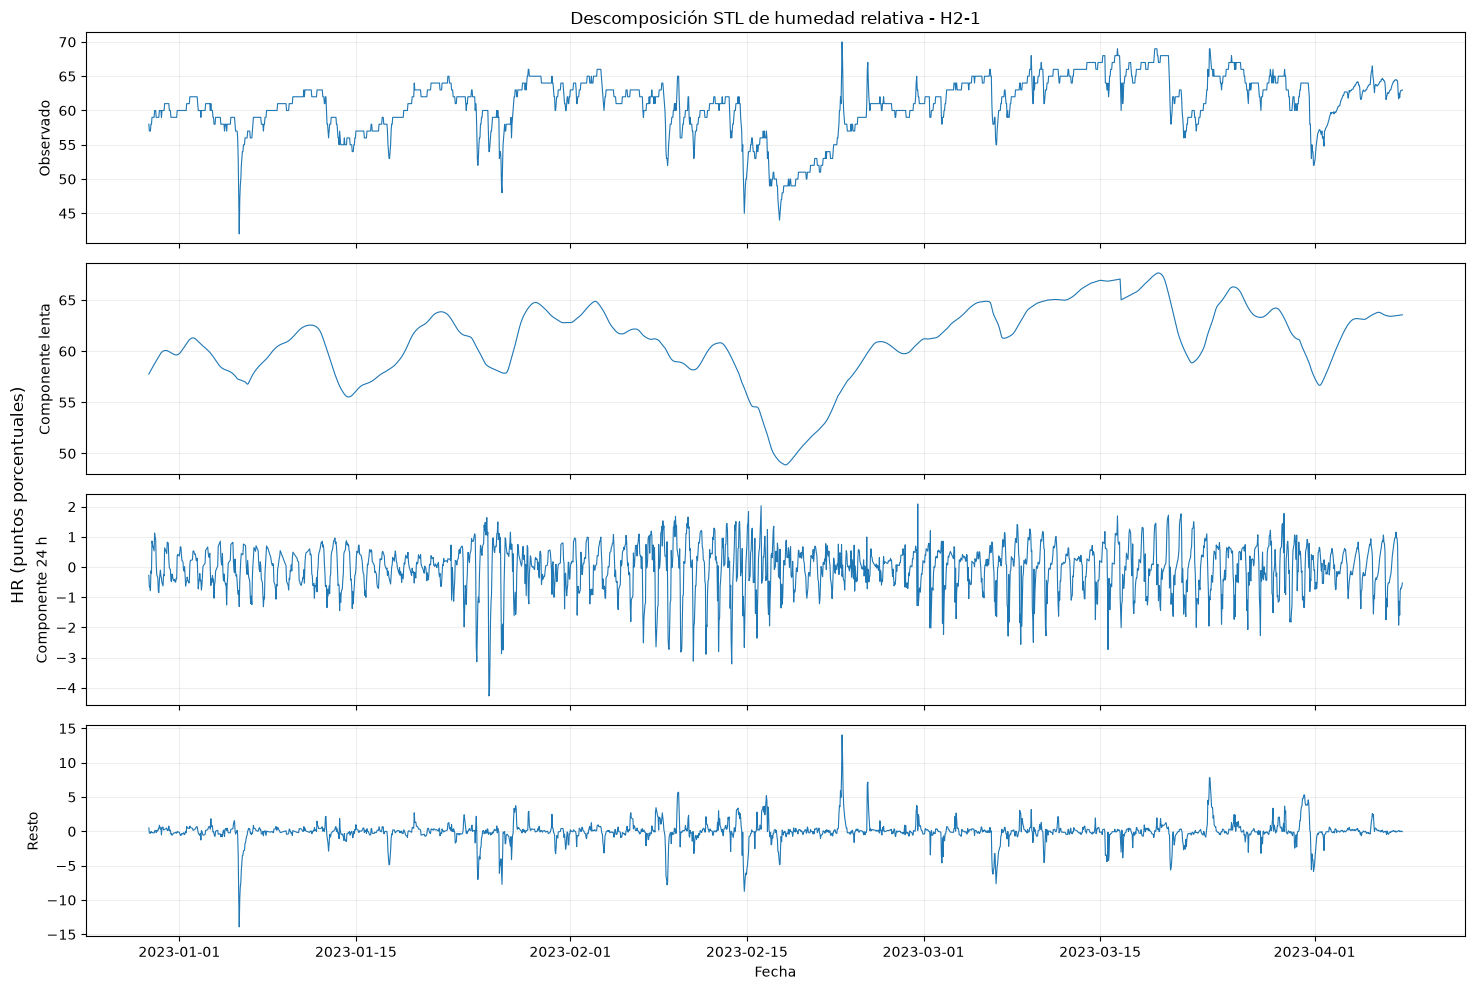

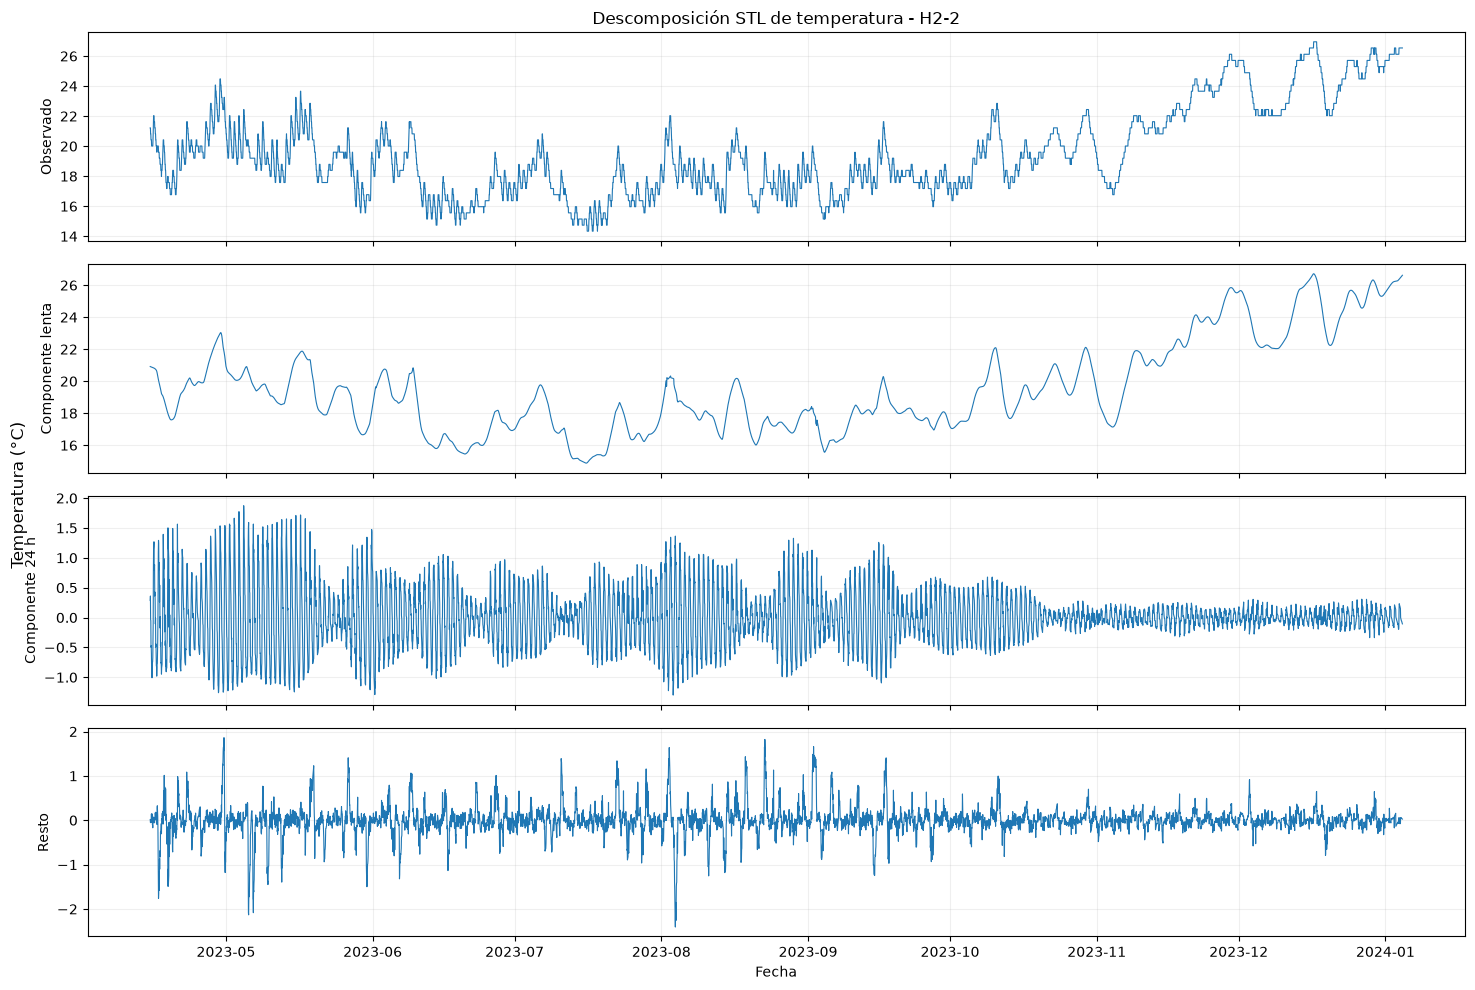

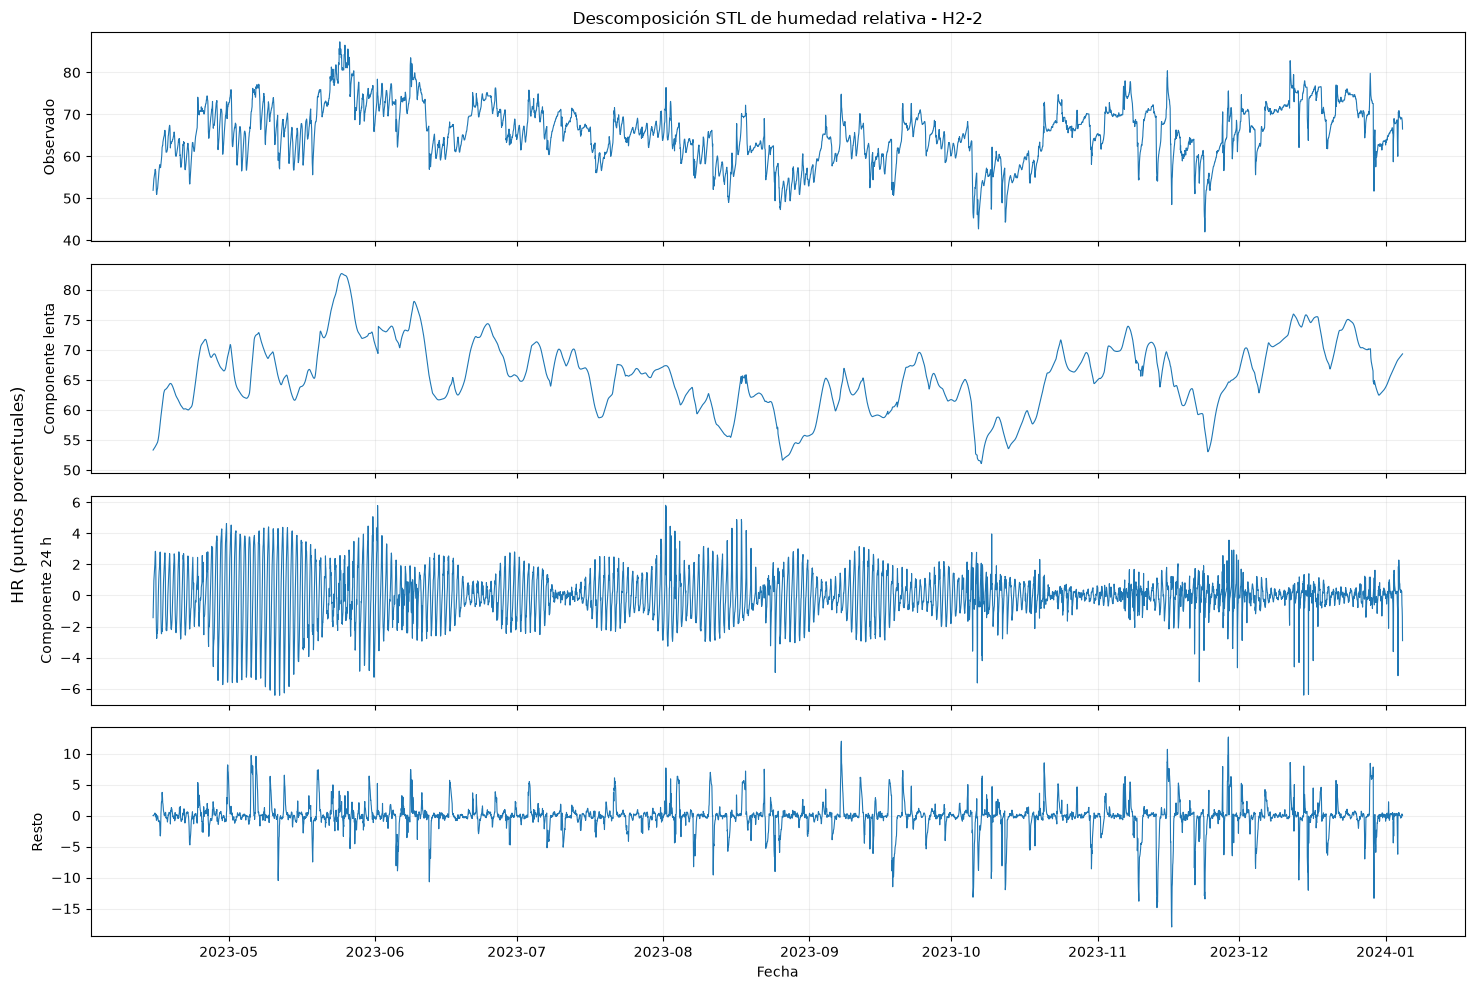

In [28]:
def graficar_descomposicion(resultado, titulo, ylabel):
    """
    Muestra las cuatro componentes de una única descomposición.

    Se grafica un tramo por figura para evitar comparar escalas distintas
    dentro de paneles demasiado cargados.
    """
    if resultado.empty:
        print(f'{titulo}: no hay suficientes observaciones continuas.')
        return
    etiquetas = [
        ('observado', 'Observado'),
        ('tendencia', 'Componente lenta'),
        ('estacional', 'Componente 24 h'),
        ('resto', 'Resto'),
    ]
    with panel(etiquetas, ncols=1, alto_fila=2.5, ancho=15) as (fig, ejes):
        for ax, (col, etiqueta) in ejes:
            ax.plot(resultado.index, resultado[col], linewidth=0.8)
            ax.set_ylabel(etiqueta)
            ax.grid(alpha=0.2)
        ejes[0][0].set_title(titulo)
        ejes[-1][0].set_xlabel('Fecha')
        fig.supylabel(ylabel)
for tramo in ['H2-1', 'H2-2']:
    if tramo in descomp_temp:
        graficar_descomposicion(descomp_temp[tramo], f'Descomposición STL de temperatura - {tramo}', 'Temperatura (°C)')
    if tramo in descomp_hr:
        graficar_descomposicion(
            descomp_hr[tramo],
            f'Descomposición STL de humedad relativa - {tramo}',
            'HR (puntos porcentuales)',
        )


**Escala temporal dominante:** Para resumir la contribución relativa de cada componente se consideran tres magnitudes:

- **rango lento 5-95 %:** amplitud de la evolución de escala larga;
- **amplitud diaria típica:** recorrido de la componente de 24 h;
- **desvío del resto:** magnitud de la variación que permanece después de retirar las dos anteriores.

Estas medidas se utilizan para comparar qué escala temporal concentra una mayor parte de la variación observada en cada unidad.

In [29]:
def resumir_descomposicion(descomposiciones):
    filas = []
    for unidad, resultado in descomposiciones.items():
        if resultado.empty:
            continue
        estacional_por_hora = resultado['estacional'].groupby(resultado.index.hour).median()
        filas.append({
            'unidad': unidad,
            'n': len(resultado),
            'rango_lento_5_95': resultado['tendencia'].quantile(0.95) - resultado['tendencia'].quantile(0.05),
            'amplitud_diaria_tipica': estacional_por_hora.max() - estacional_por_hora.min(),
            'std_resto': resultado['resto'].std(),
        })
    if not filas:
        return pd.DataFrame()
    return pd.DataFrame(filas).set_index('unidad')
resumen_descomp_temp = resumir_descomposicion(descomp_temp)
resumen_descomp_hr = resumir_descomposicion(descomp_hr)
mostrar_por_variable(
    'Resumen de la descomposición - {variable}:',
    {'T': resumen_descomp_temp, 'HR': resumen_descomp_hr},
)


Resumen de la descomposición - temperatura:


,n,rango_lento_5_95,amplitud_diaria_tipica,std_resto
unidad,,,,
H1,8872,13.439,0.271,0.186
H2-1,2385,7.806,0.257,0.180
H2-2,6350,9.721,0.971,0.332
H3,7823,10.784,0.157,0.183
H4,7603,11.752,0.118,0.128


Resumen de la descomposición - humedad relativa:


,n,rango_lento_5_95,amplitud_diaria_tipica,std_resto
unidad,,,,
H1,8872,19.060,0.405,1.939
H2-1,2385,13.163,1.463,1.514
H2-2,6350,19.133,2.375,2.320
H3,7823,21.456,0.327,1.887
H4,7603,16.213,0.486,1.870


STL separa una evolución lenta, una componente diaria y una variación remanente. En todas las unidades, la amplitud asociada a la evolución lenta supera ampliamente a la del ciclo de 24 h. Sin embargo, la importancia de este ciclo difiere entre puntos: H2-2 presenta una componente diaria mayor que H2-1 tanto en temperatura como en HR.
Una vez retiradas estas dos estructuras, el `remainder` permite estudiar la dependencia temporal de corto plazo sin que quede dominada por la evolución lenta ni por el ciclo diario.

### 3.4 Periodicidades

> **Pregunta rectora:** además de la evolución lenta, ¿qué escalas temporales reaparecen de forma recurrente?

Se estima el periodograma mediante FFT sobre el bloque horario continuo más largo de cada unidad. Previamente se elimina una tendencia lineal y se restringe la interpretación a períodos entre 2 horas y 7 días.

En las unidades con interrupciones del registro, el resultado describe el bloque continuo analizado y no necesariamente todo el período de monitoreo.

Los picos espectrales indican escalas temporales con mayor presencia recurrente en la serie, pero no permiten por sí solos identificar su causa.

In [30]:
PERIODO_MIN_H = 2
PERIODO_MAX_H = 24 * 7

def espectro_fft(serie):
    """Calcula el periodograma del bloque continuo más largo mediante rFFT."""
    s = bloque_continuo_mas_largo(serie).astype(float)
    if len(s) < 48:
        return pd.DataFrame(columns=['frecuencia_cph', 'periodo_h', 'potencia']).set_index('periodo_h')
    y = s.to_numpy(dtype=float)
    n = len(y)
    t = np.arange(n)
    pendiente, intercepto = np.polyfit(t, y, deg=1)
    y_detrend = y - (intercepto + pendiente * t)
    fft = np.fft.rfft(y_detrend)
    frecuencias = np.fft.rfftfreq(n, d=1.0)
    potencia = np.abs(fft) ** 2 / n
    mascara = frecuencias > 0
    frecuencias = frecuencias[mascara]
    potencia = potencia[mascara]
    periodos = 1 / frecuencias
    mascara_periodo = (periodos >= PERIODO_MIN_H) & (periodos <= PERIODO_MAX_H)
    return pd.DataFrame({
        'frecuencia_cph': frecuencias[mascara_periodo],
        'periodo_h': periodos[mascara_periodo],
        'potencia': potencia[mascara_periodo],
    }).sort_values('periodo_h').set_index('periodo_h')
espectro_temp = {tramo: espectro_fft(serie) for tramo, serie in series_t.items()}
espectro_hr = {tramo: espectro_fft(serie) for tramo, serie in series_hr.items()}


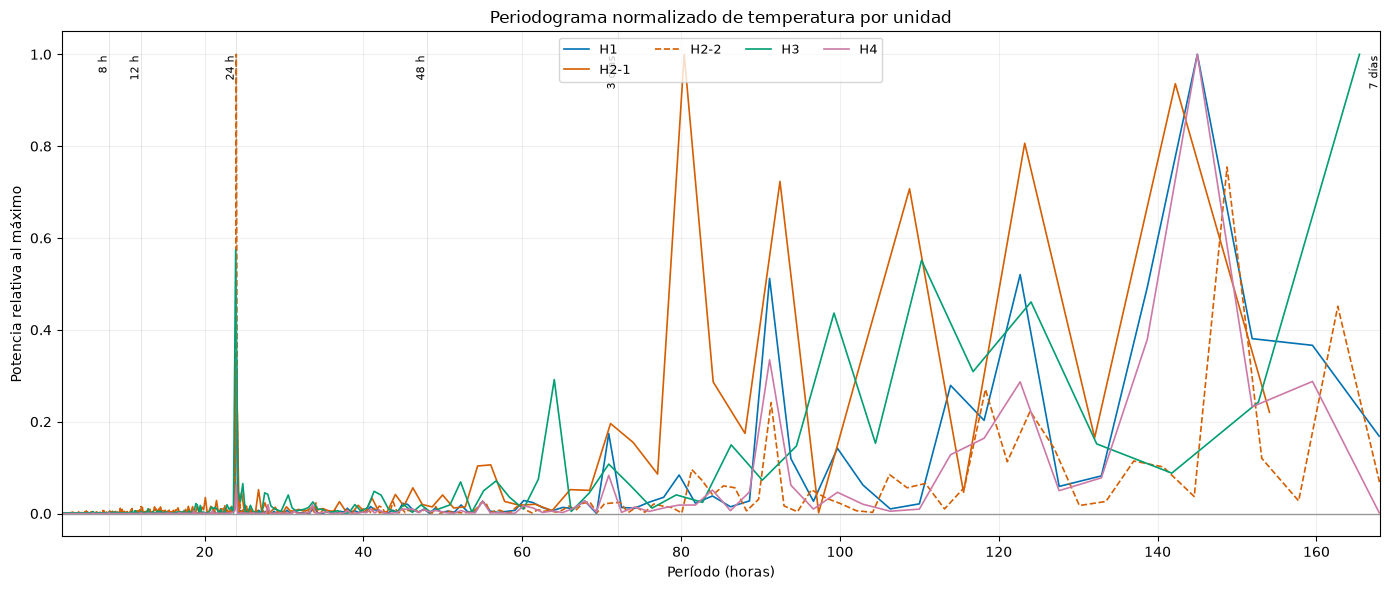

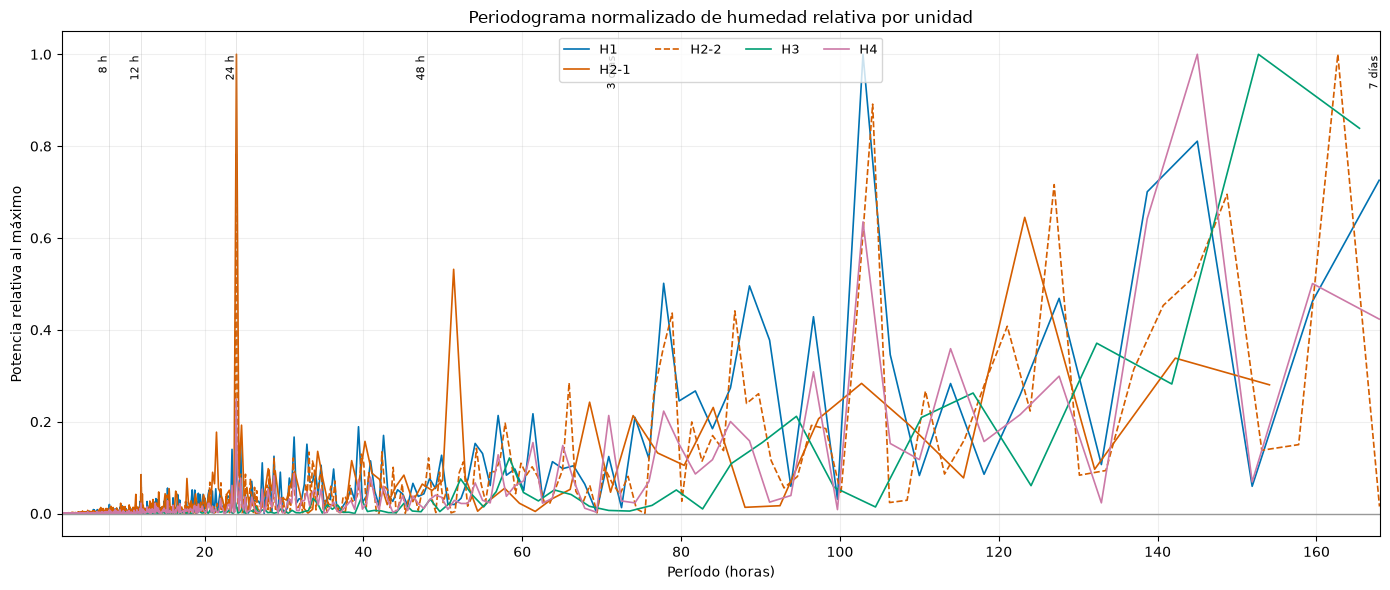

In [31]:
REFERENCIAS_ESPECTRO = {8: '8 h', 12: '12 h', 24: '24 h', 48: '48 h', 72: '3 días', 168: '7 días'}

espectro_temp_norm = {}
espectro_hr_norm = {}
for destino, origen in [(espectro_temp_norm, espectro_temp), (espectro_hr_norm, espectro_hr)]:
    for unidad, resultado in origen.items():
        r = resultado.copy()
        if not r.empty:
            potencia_max = r['potencia'].max()
            r['potencia_relativa'] = r['potencia'] / potencia_max if potencia_max > 0 else np.nan
        destino[unidad] = r

graficar_por_tramo(
    espectro_temp_norm, 'potencia_relativa',
    'Periodograma normalizado de temperatura por unidad',
    'Período (horas)', 'Potencia relativa al máximo',
    marcas=REFERENCIAS_ESPECTRO, xlim=(PERIODO_MIN_H, PERIODO_MAX_H), figsize=(14, 6), linewidth=1.2,
)
graficar_por_tramo(
    espectro_hr_norm, 'potencia_relativa',
    'Periodograma normalizado de humedad relativa por unidad',
    'Período (horas)', 'Potencia relativa al máximo',
    marcas=REFERENCIAS_ESPECTRO, xlim=(PERIODO_MIN_H, PERIODO_MAX_H), figsize=(14, 6), linewidth=1.2,
)


Para facilitar la comparación, los periodogramas se normalizan dentro de cada unidad. La potencia relativa se define como

$$
P_{rel} = \frac{P}{P_{max}}
$$

por lo que indica la importancia de cada pico respecto del máximo de esa misma serie. Esta normalización permite comparar la ubicación de las periodicidades dominantes, pero no la potencia absoluta entre sensores.

Para cada serie se conservan los tres máximos locales de mayor potencia. También se informa la longitud del bloque continuo utilizado, ya que esta condiciona la resolución con la que pueden distinguirse períodos cercanos.

In [32]:
def resumir_picos_espectrales(espectros, top_n=3):
    filas = []
    for unidad, resultado in espectros.items():
        if resultado.empty:
            continue
        r = resultado.sort_index().reset_index()
        potencia = r['potencia'].to_numpy()
        indices, _ = find_peaks(potencia, distance=2)
        if len(indices) == 0:
            indices = np.array([int(np.argmax(potencia))])
        candidatos = r.iloc[indices].nlargest(top_n, 'potencia').reset_index(drop=True)
        potencia_max = candidatos['potencia'].max()
        for orden, fila in candidatos.iterrows():
            filas.append({
                'unidad': unidad,
                'orden': orden + 1,
                'periodo_h': fila['periodo_h'],
                'potencia_relativa_al_max': fila['potencia'] / potencia_max if potencia_max > 0 else np.nan,
            })
    return pd.DataFrame(filas)


def tabla_picos_espectrales(picos, series):
    periodos = picos.pivot(index='unidad', columns='orden', values='periodo_h').rename(columns=lambda k: f'pico_{k}_h')
    potencias = picos.pivot(
        index='unidad',
        columns='orden',
        values='potencia_relativa_al_max',
    ).rename(columns=lambda k: f'rel_{k}')
    periodos.columns.name = None
    potencias.columns.name = None
    tabla = pd.concat([periodos, potencias], axis=1)
    tabla.columns.name = None
    tabla.insert(0, 'dias_bloque', pd.Series({u: len(bloque_continuo_mas_largo(s)) // 24 for u, s in series.items()}))
    orden_columnas = ['dias_bloque', 'pico_1_h', 'rel_1', 'pico_2_h', 'rel_2', 'pico_3_h', 'rel_3']
    return tabla.reindex(columns=orden_columnas)
picos_temp = resumir_picos_espectrales(espectro_temp, top_n=3)
picos_hr = resumir_picos_espectrales(espectro_hr, top_n=3)
mostrar_por_variable(
    'Períodos espectrales dominantes - {variable}:',
    {'T': tabla_picos_espectrales(picos_temp, series_t), 'HR': tabla_picos_espectrales(picos_hr, series_hr)},
    3,
)


Períodos espectrales dominantes - temperatura:


,dias_bloque,pico_1_h,rel_1,pico_2_h,rel_2,pico_3_h,rel_3
unidad,,,,,,,
H1,132,145.000,1.0,122.692,0.520,91.143,0.512
H2-1,77,80.391,1.0,142.231,0.936,123.267,0.806
H2-2,216,23.991,1.0,148.743,0.755,162.688,0.451
H3,82,23.916,1.0,110.278,0.960,124.062,0.802
H4,132,145.000,1.0,91.143,0.335,159.500,0.288


Períodos espectrales dominantes - humedad relativa:


,dias_bloque,pico_1_h,rel_1,pico_2_h,rel_2,pico_3_h,rel_3
unidad,,,,,,,
H1,132,102.903,1.0,145.000,0.811,77.805,0.501
H2-1,77,24.013,1.0,123.267,0.645,51.361,0.532
H2-2,216,162.688,1.0,104.120,0.892,23.991,0.786
H3,82,152.692,1.0,132.333,0.371,116.765,0.262
H4,132,145.000,1.0,102.903,0.635,159.500,0.501


Los periodogramas muestran concentraciones de potencia en distintas escalas temporales. Por un lado, se identifica una componente cercana a las 24 h, aunque su importancia relativa varía entre unidades. Este período constituye el pico principal en T para H2-2 y H3, y en HR para H2-1; también figura entre los principales picos de HR en H2-2.

Por otro lado, aparecen picos espectrales en períodos de varios días, aproximadamente entre 80 y 163 h según la unidad. Su ubicación varía entre series, sin que se identifique un período multidiario dominante común a todos los puntos. Estos resultados señalan escalas de variación relevantes, pero no permiten establecer que correspondan a ciclos estables durante todo el monitoreo.

No se identifican picos destacados en torno a 8 ni 12 h.

### 3.5 Persistencia temporal

> **Pregunta rectora:** si conozco el estado reciente de una serie, ¿durante cuánto tiempo sigue aportando información sobre su estado posterior?

Esta dependencia se denomina **persistencia interna**. Para distinguirla de la evolución lenta y del ciclo diario, se compara la autocorrelación de la serie observada con la que permanece en el `remainder` de STL.

Antes de interpretar la ACF y la PACF del `remainder`, se evalúa si la descomposición produjo una señal suficientemente estable. Para ello se examinan la media y el desvío móvil en ventanas de 7 días y se complementa el análisis con las pruebas ADF y KPSS.

La evolución local se ilustra con H2-1 y H2-2, correspondientes al mismo instrumento antes y después de la reubicación.

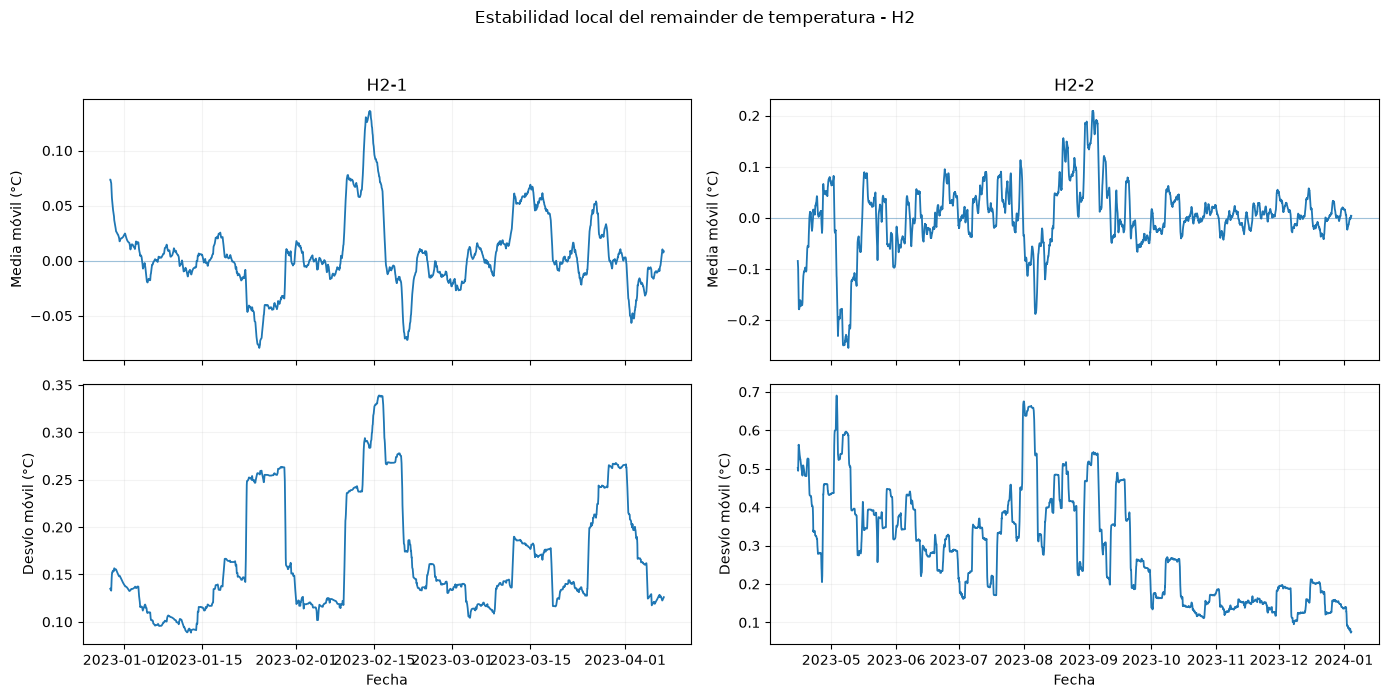

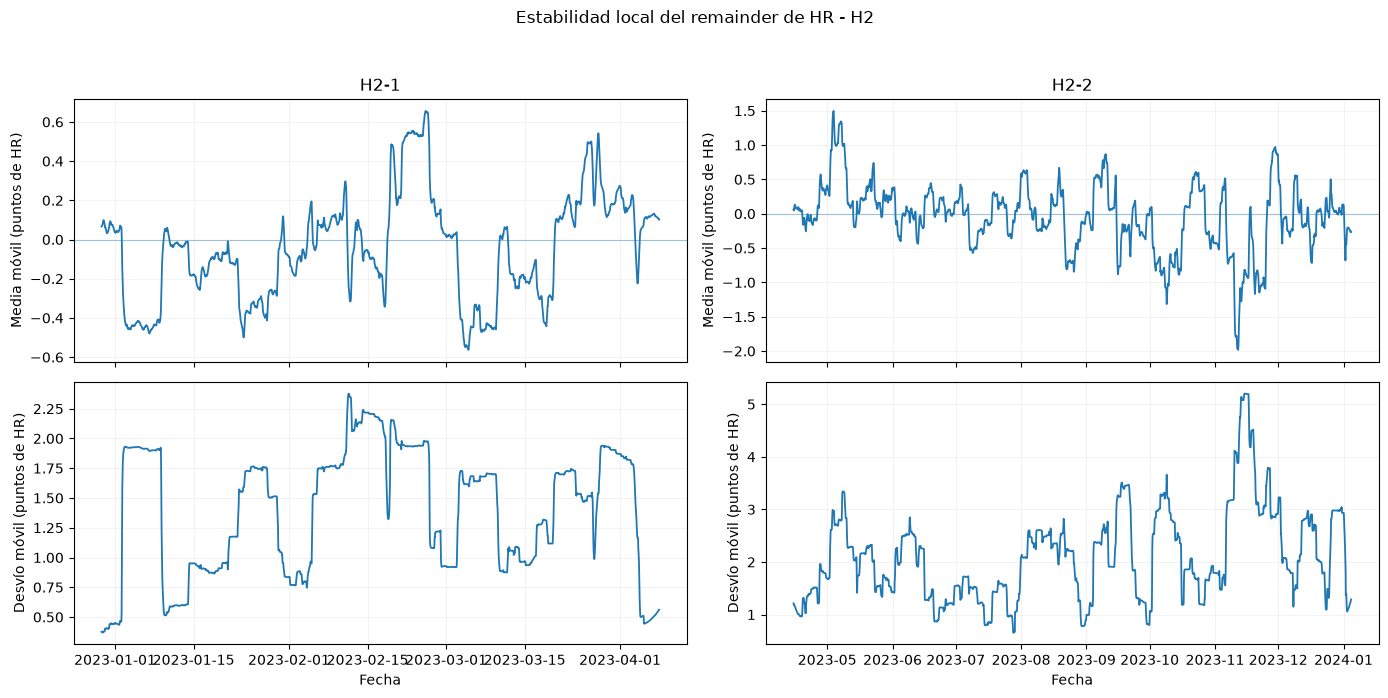

In [33]:
VENTANA_DIAGNOSTICO_H = 24 * 7
MIN_PERIODOS_DIAGNOSTICO = 24 * 3

for residuos, titulo, unidad_medida in [
    (residuos_temp, 'Estabilidad local del remainder de temperatura - H2', '°C'),
    (residuos_hr, 'Estabilidad local del remainder de HR - H2', 'puntos de HR'),
]:
    unidades_h2 = [u for u in ['H2-1', 'H2-2'] if u in residuos]
    fig, axes = plt.subplots(2, len(unidades_h2), figsize=(14, 7), sharex='col', squeeze=False)

    for j, unidad in enumerate(unidades_h2):
        s = residuos[unidad].dropna()
        ventana = dict(window=f'{VENTANA_DIAGNOSTICO_H}h', min_periods=MIN_PERIODOS_DIAGNOSTICO, center=True)
        media_movil = s.rolling(**ventana).mean()
        std_movil = s.rolling(**ventana).std()

        axes[0, j].plot(media_movil.index, media_movil, linewidth=1.3)
        axes[0, j].axhline(0, linewidth=0.8, alpha=0.4)
        axes[0, j].set_title(unidad)
        axes[0, j].set_ylabel(f'Media móvil ({unidad_medida})')
        axes[0, j].grid(alpha=0.15)

        axes[1, j].plot(std_movil.index, std_movil, linewidth=1.3)
        axes[1, j].set_xlabel('Fecha')
        axes[1, j].set_ylabel(f'Desvío móvil ({unidad_medida})')
        axes[1, j].grid(alpha=0.15)

    fig.suptitle(titulo, y=0.99)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


**ADF y KPSS como control de estacionariedad**

Las pruebas se utilizan de forma complementaria: ADF contrasta como hipótesis nula la presencia de una raíz unitaria, mientras que KPSS toma como hipótesis nula la estacionariedad alrededor de un nivel constante.

Ambas se aplican sobre secuencias temporales continuas, sin valores faltantes. En KPSS, cuando el p-valor queda fuera del rango tabulado, se informa como ≤ 0,01 o ≥ 0,10.

In [34]:
ALPHA_ESTACIONARIEDAD = 0.05


def _kpss_autolag_hobijn(residuos):
    n = len(residuos)
    covlags = int(np.power(n, 2.0 / 9.0))

    s0 = np.sum(residuos ** 2) / n
    s1 = 0.0

    for lag in range(1, covlags + 1):
        producto = np.dot(
            residuos[lag:],
            residuos[:n - lag],
        )
        producto /= n / 2.0

        s0 += producto
        s1 += lag * producto

    s_hat = s1 / s0
    gamma_hat = 1.1447 * np.power(s_hat * s_hat, 1.0 / 3.0)

    return min(
        int(gamma_hat * np.power(n, 1.0 / 3.0)),
        n - 1,
    )


def _varianza_largo_plazo_kpss(residuos, lags):
    n = len(residuos)
    s_hat = np.sum(residuos ** 2)

    for lag in range(1, lags + 1):
        producto = np.dot(
            residuos[lag:],
            residuos[:n - lag],
        )
        s_hat += (
            2
            * producto
            * (1.0 - lag / (lags + 1.0))
        )

    return s_hat / n


def kpss_nivel(serie):
    """
    KPSS de estacionariedad alrededor de una constante.

    Reproduce el autolag de Hobijn y la tabla de Kwiatkowski et al.
    utilizada por statsmodels. Cuando el estadístico cae fuera del
    rango tabulado, el p-valor devuelto es el límite 0.01 o 0.10;
    la tabla posterior lo muestra explícitamente como ≤0.01 o ≥0.10.
    """
    x = np.asarray(serie, dtype=float)
    n = len(x)

    residuos = x - x.mean()
    lags = _kpss_autolag_hobijn(residuos)

    eta = np.sum(np.cumsum(residuos) ** 2) / (n ** 2)
    s_hat = _varianza_largo_plazo_kpss(residuos, lags)
    estadistico = eta / s_hat

    criticos = np.array([0.347, 0.463, 0.574, 0.739])
    p_tabla = np.array([0.10, 0.05, 0.025, 0.01])

    p_valor = float(
        np.interp(
            estadistico,
            criticos,
            p_tabla,
        )
    )

    return (
        float(estadistico),
        p_valor,
        int(lags),
        {
            '10%': 0.347,
            '5%': 0.463,
            '2.5%': 0.574,
            '1%': 0.739,
        },
    )


def diagnostico_tests_estacionariedad(serie):
    """
    Aplica ADF y KPSS a una serie continua sin faltantes.

    ADF:
        H0 = raíz unitaria.
        Se usa constante y autolag='AIC'.

    KPSS:
        H0 = estacionariedad alrededor de una constante.
        Se usa nlags='auto'.
    """
    s = serie.dropna().astype(float)
    if len(s) < 48 or np.isclose(s.std(), 0):
        return {
            'n': len(s),
            'adf_stat': np.nan,
            'adf_p': np.nan,
            'adf_lags': np.nan,
            'kpss_stat': np.nan,
            'kpss_p': np.nan,
            'kpss_lags': np.nan,
        }
    adf = adfuller(s, regression='c', autolag='AIC')
    kpss_resultado = kpss_nivel(s)
    return {
        'n': len(s),
        'adf_stat': adf[0],
        'adf_p': adf[1],
        'adf_lags': adf[2],
        'kpss_stat': kpss_resultado[0],
        'kpss_p': kpss_resultado[1],
        'kpss_lags': kpss_resultado[2],
    }

def interpretar_adf_kpss(adf_p, kpss_p, alpha=ALPHA_ESTACIONARIEDAD):
    if pd.isna(adf_p) or pd.isna(kpss_p):
        return 'no evaluable'
    adf_rechaza = adf_p < alpha
    kpss_rechaza = kpss_p < alpha
    if adf_rechaza and (not kpss_rechaza):
        return 'compatible con estacionariedad de nivel'
    if not adf_rechaza and kpss_rechaza:
        return 'evidencia de no estacionariedad de nivel'
    if adf_rechaza and kpss_rechaza:
        return 'resultado mixto'
    return 'inconcluso'

def comparar_nivel_y_resto(series_originales, descomposiciones):
    filas = []
    for unidad, serie_original in series_originales.items():
        representaciones = {'nivel': bloque_continuo_mas_largo(serie_original).dropna()}
        resultado_descomp = descomposiciones.get(unidad, pd.DataFrame())
        if not resultado_descomp.empty:
            representaciones['resto_STL'] = bloque_continuo_mas_largo(resultado_descomp['resto'])
        for representacion, serie in representaciones.items():
            res = diagnostico_tests_estacionariedad(serie)
            filas.append({
                'unidad': unidad,
                'representacion': representacion,
                **res,
                'lectura': interpretar_adf_kpss(res['adf_p'], res['kpss_p']),
            })
    return pd.DataFrame(filas).set_index(['unidad', 'representacion'])

def formatear_kpss_p(p):
    """Muestra explícitamente los límites de la tabla de p-valores de KPSS."""
    if pd.isna(p):
        return 'NA'
    if p <= 0.01:
        return '≤ 0.01'
    if p >= 0.1:
        return '≥ 0.10'
    return f'{p:.4f}'

def formatear_adf_p(p):
    if pd.isna(p):
        return 'NA'
    if p < 0.0001:
        return '< 0.0001'
    return f'{p:.4f}'

def tabla_estacionariedad(resultado):
    tabla = resultado[['adf_p', 'kpss_p', 'lectura']].copy()
    tabla['adf_p'] = tabla['adf_p'].map(formatear_adf_p)
    tabla['kpss_p'] = tabla['kpss_p'].map(formatear_kpss_p)
    return tabla.rename(columns={'adf_p': 'ADF p', 'kpss_p': 'KPSS p'})
estacionariedad_temp = comparar_nivel_y_resto(series_t, descomp_temp)
estacionariedad_hr = comparar_nivel_y_resto(series_hr, descomp_hr)
mostrar_por_variable(
    'ADF + KPSS - {variable}:',
    {'T': tabla_estacionariedad(estacionariedad_temp), 'HR': tabla_estacionariedad(estacionariedad_hr)},
    4,
)


ADF + KPSS - temperatura:


ADF p  KPSS p  \
unidad representacion                     
H1     nivel             0.1763  ≤ 0.01   
       resto_STL       < 0.0001  ≥ 0.10   
H2-1   nivel             0.0099  0.0811   
       resto_STL       < 0.0001  ≥ 0.10   
H2-2   nivel             0.1949  ≤ 0.01   
       resto_STL       < 0.0001  ≥ 0.10   
H3     nivel           < 0.0001  0.0183   
       resto_STL       < 0.0001  ≥ 0.10   
H4     nivel             0.4830  ≤ 0.01   
       resto_STL       < 0.0001  ≥ 0.10   

                                                        lectura  
unidad representacion                                            
H1     nivel           evidencia de no estacionariedad de nivel  
       resto_STL        compatible con estacionariedad de nivel  
H2-1   nivel            compatible con estacionariedad de nivel  
       resto_STL        compatible con estacionariedad de nivel  
H2-2   nivel           evidencia de no estacionariedad de nivel  
       resto_STL        compatible con estacionariedad de nivel  
H3     nivel                                    resultado mixto  
       resto_STL        compatible con estacionariedad de nivel  
H4     nivel           evidencia de no estacionariedad de nivel  
       resto_STL        compatible con estacionariedad de nivel

ADF + KPSS - humedad relativa:


ADF p  KPSS p  \
unidad representacion                     
H1     nivel           < 0.0001  ≤ 0.01   
       resto_STL       < 0.0001  ≥ 0.10   
H2-1   nivel             0.2328  0.0174   
       resto_STL       < 0.0001  ≥ 0.10   
H2-2   nivel           < 0.0001  ≤ 0.01   
       resto_STL       < 0.0001  ≥ 0.10   
H3     nivel             0.0046  ≤ 0.01   
       resto_STL       < 0.0001  ≥ 0.10   
H4     nivel           < 0.0001  ≤ 0.01   
       resto_STL       < 0.0001  ≥ 0.10   

                                                        lectura  
unidad representacion                                            
H1     nivel                                    resultado mixto  
       resto_STL        compatible con estacionariedad de nivel  
H2-1   nivel           evidencia de no estacionariedad de nivel  
       resto_STL        compatible con estacionariedad de nivel  
H2-2   nivel                                    resultado mixto  
       resto_STL        compatible con estacionariedad de nivel  
H3     nivel                                    resultado mixto  
       resto_STL        compatible con estacionariedad de nivel  
H4     nivel                                    resultado mixto  
       resto_STL        compatible con estacionariedad de nivel

El `remainder` presenta un comportamiento compatible con estacionariedad en nivel. En las series observadas, ADF y KPSS muestran no estacionariedad o resultados mixtos en 9 de los 10 casos; después de STL, en cambio, ambos tests son compatibles con estacionariedad en todas las unidades (ADF p < 0,0001; KPSS p ≥ 0,10). En H2, además, la media móvil oscila alrededor de cero sin desplazamientos persistentes.

La dispersión, sin embargo, no permanece constante. En H2-2, el desvío móvil varía desde menos de 0,1 hasta cerca de 0,7 °C en T y desde menos de 1 hasta más de 5 puntos en HR. Las mesetas de aproximadamente una semana responden en parte al ancho de la ventana móvil: una desviación grande mantiene elevado el desvío mientras permanece dentro de ella.

Por lo tanto, **estacionariedad en nivel no implica homocedasticidad ni ruido blanco**. El `remainder` conserva variación en su dispersión y episodios de gran magnitud que deben considerarse en el análisis posterior.

**Dependencia temporal**  
Se estudia comparando tres diagnósticos: la ACF de la serie observada, la ACF del `remainder` y la PACF del `remainder`. La primera refleja conjuntamente evolución lenta, ciclo diario y memoria de corto plazo; al trabajar sobre el `remainder` se analiza la dependencia que permanece una vez retiradas las principales estructuras sistemáticas. La PACF permite evaluar la asociación correspondiente a cada rezago controlando el efecto de los rezagos intermedios.
Para cada rezago de $k$ horas se utilizan únicamente pares de observaciones separados exactamente por $k$ horas, evitando emparejamientos a través de huecos.

In [35]:
LAG_MAX_NIVELES = 168
acf_temp = {unidad: acf_pairwise(serie, LAG_MAX_NIVELES) for unidad, serie in series_t.items()}
acf_hr = {unidad: acf_pairwise(serie, LAG_MAX_NIVELES) for unidad, serie in series_hr.items()}


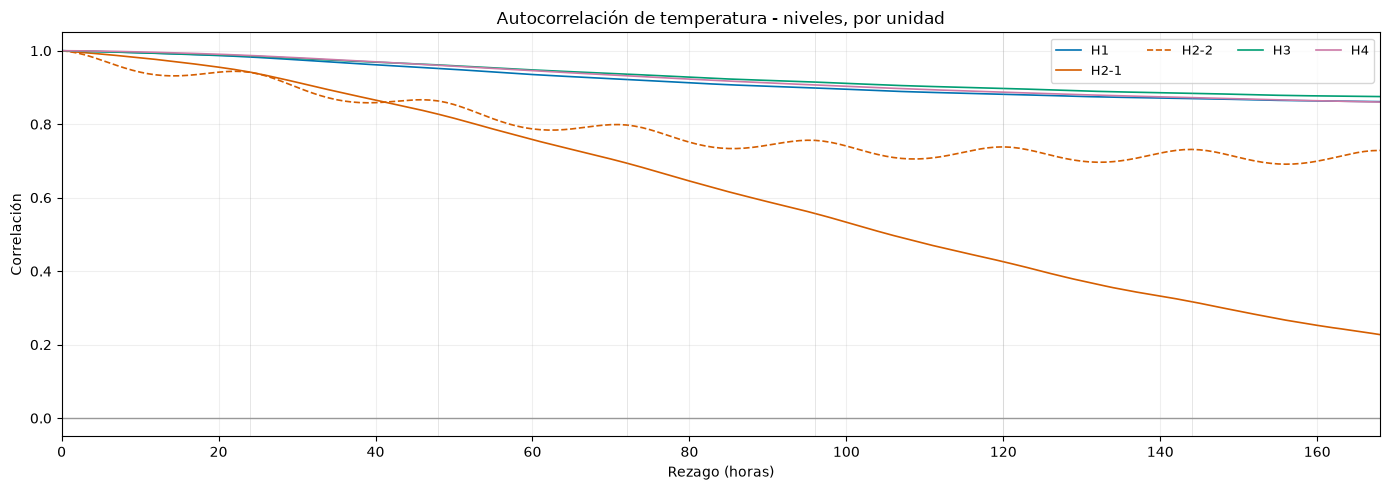

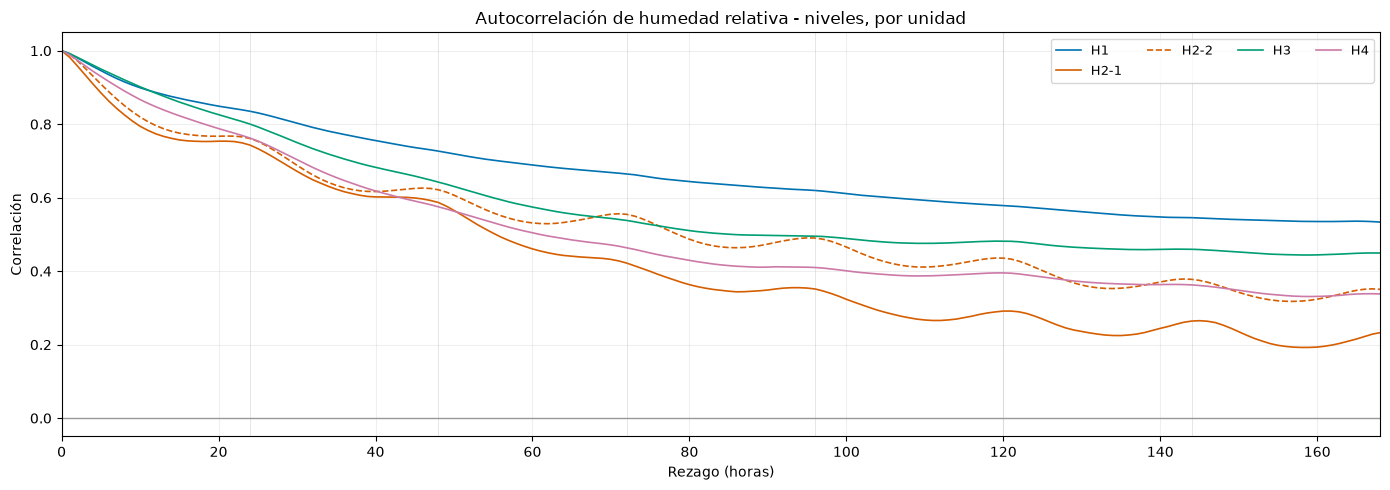

In [36]:
MARCAS_DIARIAS = list(range(24, LAG_MAX_NIVELES + 1, 24))

graficar_por_tramo(
    acf_temp, 'correlacion',
    'Autocorrelación de temperatura - niveles, por unidad',
    'Rezago (horas)', 'Correlación',
    marcas=MARCAS_DIARIAS, xlim=(0, LAG_MAX_NIVELES), linewidth=1.2,
)
graficar_por_tramo(
    acf_hr, 'correlacion',
    'Autocorrelación de humedad relativa - niveles, por unidad',
    'Rezago (horas)', 'Correlación',
    marcas=MARCAS_DIARIAS, xlim=(0, LAG_MAX_NIVELES), linewidth=1.2,
)


En niveles, la ACF decae lentamente, reflejando principalmente la evolución de escala larga. En T, H1, H3 y H4 mantienen correlaciones superiores a 0,85 incluso a una semana de rezago, mientras H2-1 decae más rápido, hasta aproximadamente 0,2. H2-2 presenta además una ondulación cercana a 24 h, coherente con la componente diaria más marcada observada previamente.

En HR, la persistencia en niveles es menor: las correlaciones a una semana se ubican aproximadamente entre 0,2 y 0,6. Las ondulaciones diarias son más visibles en H2-1 y H2-2, mientras H1 presenta la mayor persistencia.

Estas autocorrelaciones de largo alcance no se interpretan directamente como inercia física, ya que todavía incluyen evolución lenta y periodicidad. Por eso se comparan a continuación con la dependencia que permanece en el `remainder`.

Para evaluar qué dependencia permanece una vez retiradas la evolución lenta y la componente diaria, se compara la ACF de la serie observada con la del `remainder` en rezagos de 1, 6, 12 y 24 h.

Una caída marcada de la autocorrelación en el `remainder` indica que buena parte de la continuidad observada en niveles estaba asociada a esas estructuras. La dependencia restante representa memoria de corto plazo entre desviaciones respecto del patrón temporal esperado.

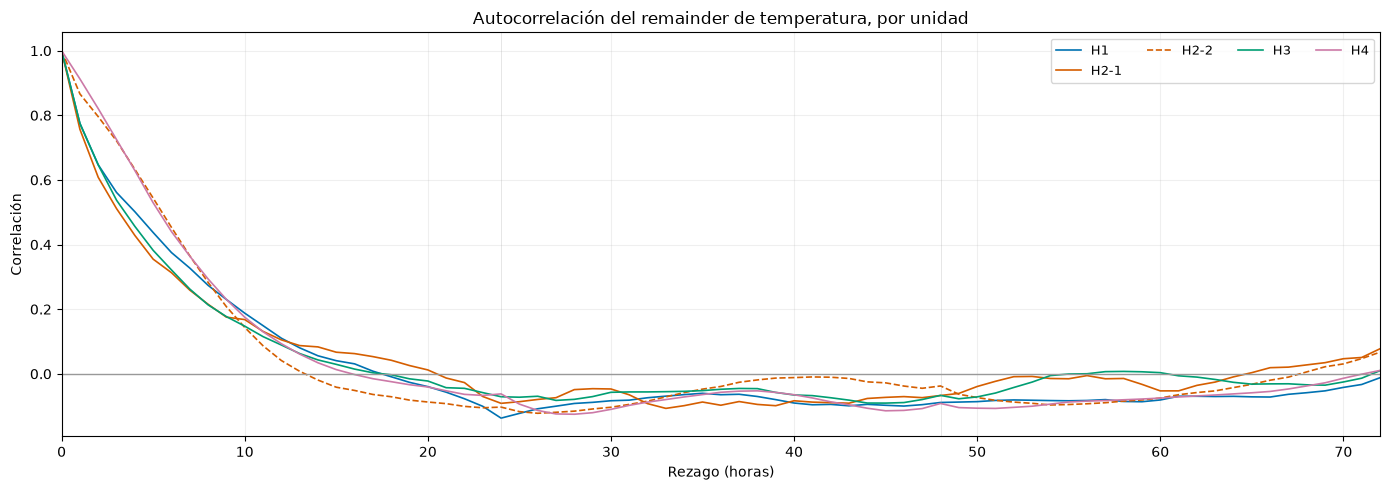

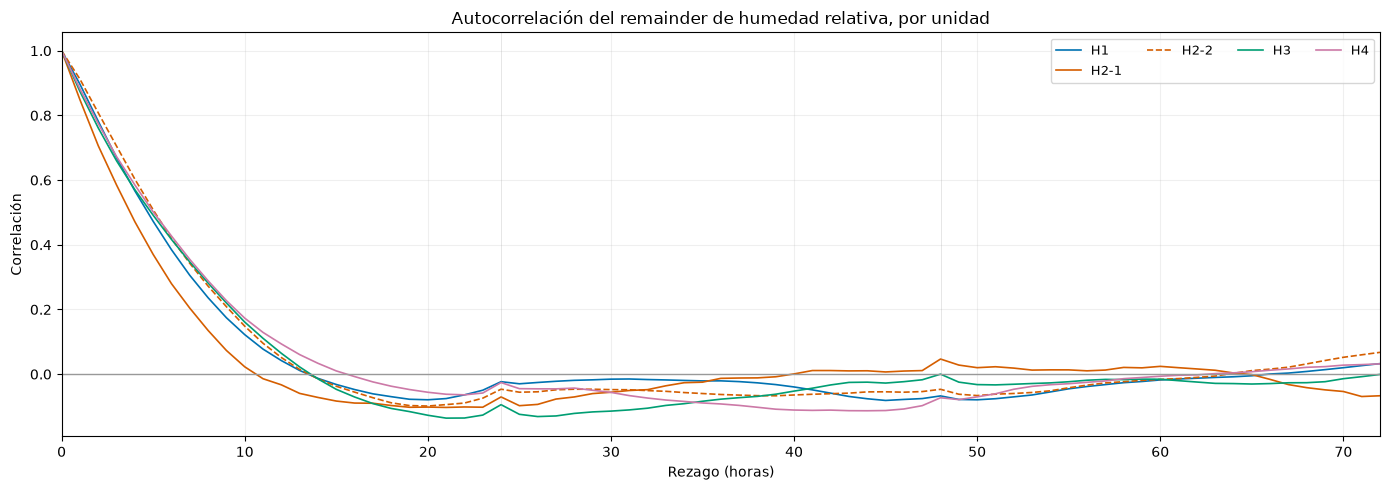

In [37]:
LAG_MAX_RESTO = 72

acf_resid_temp = {
    tramo: acf_pairwise(serie, LAG_MAX_RESTO)
    for tramo, serie in residuos_temp.items()
}

acf_resid_hr = {
    tramo: acf_pairwise(serie, LAG_MAX_RESTO)
    for tramo, serie in residuos_hr.items()
}

graficar_por_tramo(
    acf_resid_temp,
    columna='correlacion',
    titulo='Autocorrelación del remainder de temperatura, por unidad',
    xlabel='Rezago (horas)',
    ylabel='Correlación',
    marcas=[24, 48, 72],
    xlim=(0, LAG_MAX_RESTO),
    linewidth=1.2,
)

graficar_por_tramo(
    acf_resid_hr,
    columna='correlacion',
    titulo='Autocorrelación del remainder de humedad relativa, por unidad',
    xlabel='Rezago (horas)',
    ylabel='Correlación',
    marcas=[24, 48, 72],
    xlim=(0, LAG_MAX_RESTO),
    linewidth=1.2,
)

In [38]:
LAGS_COMPARACION_RESTO = [1, 6, 12, 24]

def tabla_acf_nivel_resto(acf_nivel, acf_resto, lags=LAGS_COMPARACION_RESTO):
    filas = []
    for unidad in sorted(set(acf_nivel) & set(acf_resto)):
        fila = {'unidad': unidad}
        for lag in lags:
            fila[f'{lag}h_nivel'] = acf_nivel[unidad].loc[lag, 'correlacion']
            fila[f'{lag}h_resto'] = acf_resto[unidad].loc[lag, 'correlacion']
        filas.append(fila)
    return pd.DataFrame(filas).set_index('unidad')
comparacion_acf_temp = tabla_acf_nivel_resto(acf_temp, acf_resid_temp)
comparacion_acf_hr = tabla_acf_nivel_resto(acf_hr, acf_resid_hr)
mostrar_por_variable('ACF nivel vs. remainder - {variable}:', {'T': comparacion_acf_temp, 'HR': comparacion_acf_hr}, 3)


ACF nivel vs. remainder - temperatura:


,1h_nivel,1h_resto,6h_nivel,6h_resto,12h_nivel,12h_resto,24h_nivel,24h_resto
unidad,,,,,,,,
H1,1.000,0.775,0.997,0.375,0.993,0.110,0.983,-0.137
H2-1,0.998,0.757,0.989,0.313,0.976,0.105,0.942,-0.091
H2-2,0.997,0.866,0.968,0.453,0.934,0.041,0.941,-0.103
H3,0.999,0.775,0.997,0.322,0.993,0.089,0.985,-0.071
H4,1.000,0.913,0.999,0.440,0.996,0.093,0.987,-0.062


ACF nivel vs. remainder - humedad relativa:


,1h_nivel,1h_resto,6h_nivel,6h_resto,12h_nivel,12h_resto,24h_nivel,24h_resto
unidad,,,,,,,,
H1,0.992,0.897,0.935,0.385,0.886,0.042,0.835,-0.023
H2-1,0.983,0.849,0.863,0.280,0.774,-0.033,0.743,-0.070
H2-2,0.990,0.912,0.888,0.419,0.796,0.051,0.761,-0.047
H3,0.992,0.874,0.940,0.417,0.884,0.064,0.800,-0.094
H4,0.989,0.882,0.916,0.427,0.847,0.093,0.762,-0.026


**¿La dependencia observada en rezagos mayores sigue siendo directa?**

La PACF permite evaluar la asociación entre $R_t$ y $R_{t-k}$ controlando el efecto de los rezagos intermedios. Se calcula sobre el bloque continuo más largo de cada `remainder`; la figura se concentra en H2-1 y H2-2, mientras que la tabla resume los resultados para todas las unidades.

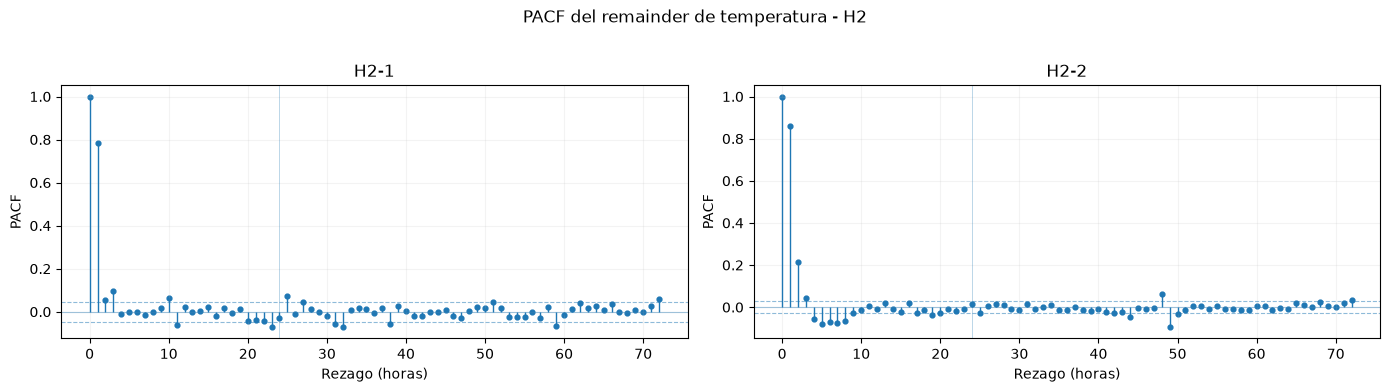

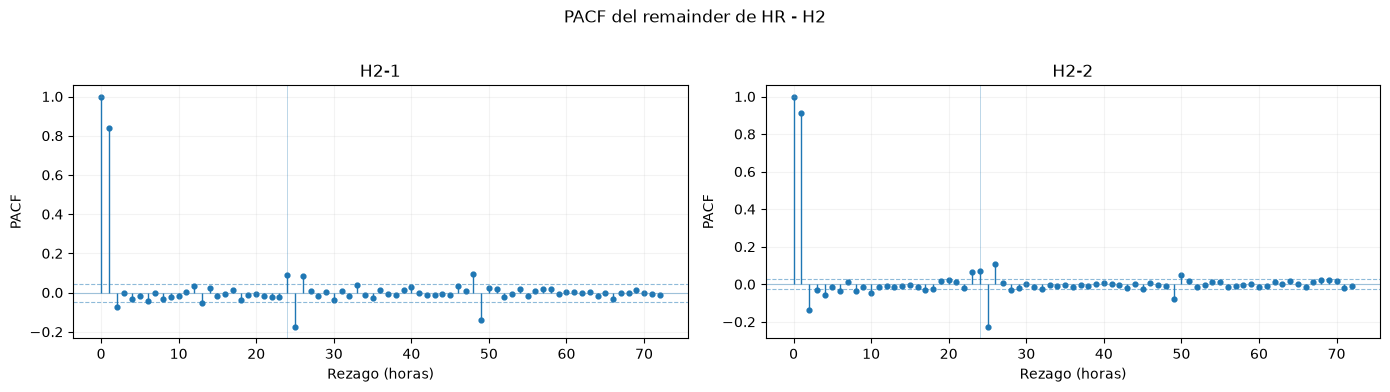

In [39]:
def calcular_pacf_resto(residuos, max_lag=LAG_MAX_RESTO):
    resultados = {}
    for unidad, serie in residuos.items():
        s = bloque_continuo_mas_largo(serie).astype(float)
        max_lag_valido = min(max_lag, len(s) // 2 - 1)
        if max_lag_valido < 1:
            continue
        valores = pacf(s, nlags=max_lag_valido, method='ywm')
        resultados[unidad] = pd.DataFrame({
            'lag': np.arange(len(valores)),
            'pacf': valores,
            'n': len(s),
            'inicio_bloque': s.index.min(),
            'fin_bloque': s.index.max(),
        }).set_index('lag')
    return resultados

pacf_resid_temp = calcular_pacf_resto(residuos_temp)
pacf_resid_hr = calcular_pacf_resto(residuos_hr)

for resultados, titulo in [
    (pacf_resid_temp, 'PACF del remainder de temperatura - H2'),
    (pacf_resid_hr, 'PACF del remainder de HR - H2'),
]:
    unidades_h2 = [u for u in ['H2-1', 'H2-2'] if u in resultados]
    with panel(unidades_h2, ncols=2, alto_fila=3.8, titulo=titulo, suptitle_y=1.02) as (fig, ejes):
        for ax, unidad in ejes:
            r = resultados[unidad]
            lags = r.index.to_numpy()
            valores = r['pacf'].to_numpy()
            limite = 1.96 / np.sqrt(int(r['n'].iloc[0]))
            ax.vlines(lags, 0, valores, linewidth=1)
            ax.scatter(lags, valores, s=12)
            ax.axhline(0, linewidth=0.8, alpha=0.4)
            ax.axhline(limite, linewidth=0.8, linestyle='--', alpha=0.5)
            ax.axhline(-limite, linewidth=0.8, linestyle='--', alpha=0.5)
            ax.axvline(24, linewidth=0.7, alpha=0.3)
            ax.set_title(unidad)
            ax.set_xlabel('Rezago (horas)')
            ax.set_ylabel('PACF')
            ax.grid(alpha=0.15)


In [40]:
LAGS_PACF_RESUMEN = [1, 2, 3, 6, 12, 24, 48, 72]

tablas_pacf = {}
for variable, resultados in [('T', pacf_resid_temp), ('HR', pacf_resid_hr)]:
    tabla = pd.DataFrame({u: r.reindex(LAGS_PACF_RESUMEN)['pacf'] for u, r in resultados.items()}).T
    tabla.index.name = 'unidad'
    tabla.columns = [f'{lag} h' for lag in tabla.columns]
    tablas_pacf[variable] = tabla

mostrar_por_variable('PACF seleccionada - {variable}:', tablas_pacf)


PACF seleccionada - temperatura:


,1 h,2 h,3 h,6 h,12 h,24 h,48 h,72 h
unidad,,,,,,,,
H1,0.766,0.138,0.097,-0.017,-0.049,-0.033,0.016,0.042
H2-1,0.784,0.054,0.095,-0.002,0.020,-0.027,0.002,0.057
H2-2,0.858,0.212,0.042,-0.072,-0.009,0.017,0.063,0.035
H3,0.791,0.088,0.012,-0.006,-0.009,-0.045,0.019,0.025
H4,0.927,-0.098,-0.068,-0.043,0.001,0.027,0.009,-0.021


PACF seleccionada - humedad relativa:


,1 h,2 h,3 h,6 h,12 h,24 h,48 h,72 h
unidad,,,,,,,,
H1,0.901,-0.153,-0.082,-0.044,-0.004,0.072,-0.006,-0.032
H2-1,0.842,-0.073,-0.004,-0.042,0.034,0.090,0.097,-0.012
H2-2,0.910,-0.135,-0.030,-0.035,-0.010,0.071,-0.008,-0.007
H3,0.911,-0.104,0.035,-0.048,0.005,-0.045,-0.009,-0.055
H4,0.886,-0.015,-0.047,0.008,0.003,0.131,0.031,-0.032


Retirar la evolución lenta y el ciclo diario cambia sustancialmente la lectura de la dependencia temporal. En niveles, la ACF a 12 h todavía supera 0,93 en T y se ubica entre 0,77 y 0,89 en HR. En el `remainder`, en cambio, la dependencia se concentra principalmente en el corto plazo:
- a 1 h, la ACF permanece elevada, entre 0,76 y 0,91 en T y entre 0,85 y 0,91 en HR;
- a 6 h desciende a valores entre 0,28 y 0,45;
- a 12 h no supera 0,11;
- a 24 h es pequeña y negativa, entre −0,14 y −0,02.
La PACF refuerza esta lectura: la mayor asociación directa se concentra en el primer rezago, con valores entre 0,77 y 0,93. Esto indica que buena parte de la dependencia observada en horizontes mayores se transmite a través de la memoria inmediata. En HR aparece además una asociación directa débil a 24 h, más marcada en H4 (PACF 0,13) y menor en H1, H2-1 y H2-2 (0,07–0,09).

### 3.6 Síntesis

La caracterización temporal muestra que la evolución lenta concentra la mayor parte de la variación, mientras que la importancia del ciclo de 24 h difiere entre unidades. Una vez retiradas ambas estructuras mediante STL, la dependencia remanente se concentra principalmente en las primeras horas. El `remainder` presenta un nivel compatible con estacionariedad, aunque su dispersión varía en el tiempo.

A partir de esta caracterización se distinguen dos dimensiones diferentes:

1. **Relevancia para conservación:** si el nivel o la fluctuación observada alcanza condiciones de interés según los criterios utilizados en el TFI.
2. **Rareza temporal:** si una observación resulta inusual respecto de la dinámica propia de la serie.

$$
\text{relevancia para conservación}
\neq
\text{rareza temporal}.
$$

Una condición puede ser habitual y, al mismo tiempo, relevante para conservación; del mismo modo, un evento temporalmente inusual puede no alcanzar condiciones problemáticas desde el punto de vista de conservación.

## 4. Qué condiciones son relevantes para conservación

> **Pregunta rectora:** ¿qué información del TFI podemos utilizar para interpretar las anomalías temporales?

Se retoman indicadores y condiciones ambientales de interés para conservación del TFI de Scoccimarro (2024).

Primero se calculan indicadores generales por sensor y unidad de análisis, para caracterizar la exposición a determinados niveles de HR y las fluctuaciones de corto plazo. Después se identifican condiciones horarias que podrán cruzarse con las anomalías temporales.

Estas condiciones no determinan si una observación es anómala: aportan información sobre el ambiente en el momento de cada detección.

In [41]:
UMBRALES_CONSERVACION = {
    'hr_banda_aceptable_min': 40.0,
    'hr_banda_aceptable_max': 65.0,
    'hr_banda_critica_max': 75.0,
    'hr_alerta_fisica_alta': 80.0,
    'temp_alerta_materiales': 30.0,
    'micro_sin_riesgo_max': 65.0,
    'micro_bajo_max': 70.0,
    'micro_moderado_max': 75.0,
    'delta24_T_sin_riesgo_max': 4.0,
    'delta24_T_moderado_max': 10.0,
    'delta24_HR_sin_riesgo_max': 10.0,
    'delta24_HR_moderado_max': 20.0,
}

def clasificar_banda_hr(x):
    if pd.isna(x):
        return np.nan
    if x < UMBRALES_CONSERVACION['hr_banda_aceptable_min']:
        return 'HR baja (<40; alerta dependiente de materialidad)'
    if x <= UMBRALES_CONSERVACION['hr_banda_aceptable_max']:
        return 'aceptable (40-65)'
    if x <= UMBRALES_CONSERVACION['hr_banda_critica_max']:
        return 'crítica (>65-75)'
    return 'incorrecta (>75)'

def clasificar_riesgo_microbiologico(p975_hr):
    if pd.isna(p975_hr):
        return np.nan
    if p975_hr <= UMBRALES_CONSERVACION['micro_sin_riesgo_max']:
        return 'A: sin riesgo'
    if p975_hr <= UMBRALES_CONSERVACION['micro_bajo_max']:
        return 'B: riesgo bajo'
    if p975_hr <= UMBRALES_CONSERVACION['micro_moderado_max']:
        return 'C: riesgo moderado'
    return 'F: alto riesgo'

def clasificar_riesgo_mecanico(p95_delta24, variable):
    if pd.isna(p95_delta24):
        return np.nan
    if variable == 'T':
        limite_bajo = UMBRALES_CONSERVACION['delta24_T_sin_riesgo_max']
        limite_moderado = UMBRALES_CONSERVACION['delta24_T_moderado_max']
    else:
        limite_bajo = UMBRALES_CONSERVACION['delta24_HR_sin_riesgo_max']
        limite_moderado = UMBRALES_CONSERVACION['delta24_HR_moderado_max']
    if p95_delta24 <= limite_bajo:
        return 'a: sin riesgo'
    if p95_delta24 <= limite_moderado:
        return 'b: riesgo moderado'
    return 'f: alto riesgo'


### 4.1 Exposición a distintos niveles de HR

> **Pregunta rectora:** ¿Qué clasificación microbiológica corresponde a cada sensor o unidad según el percentil 97,5 de HR y los criterios empleados en el TFI?

Se calcula la proporción de observaciones correspondientes a cada banda de HR para resumir la exposición acumulada de cada unidad.

Este enfoque permite diferenciar situaciones en las que los niveles elevados de HR se sostienen durante períodos prolongados de aquellas en las que sólo se alcanzan de manera ocasional.

In [42]:
BANDAS_HR = {
    'pct_hr_baja': 'HR baja (<40; alerta dependiente de materialidad)',
    'pct_aceptable_40_65': 'aceptable (40-65)',
    'pct_critica_65_75': 'crítica (>65-75)',
    'pct_incorrecta_mayor_75': 'incorrecta (>75)',
}

filas = []
for unidad, serie in series_hr.items():
    s = serie.dropna()
    if s.empty:
        continue
    conteos = s.map(clasificar_banda_hr).value_counts()
    fila = {'unidad': unidad, 'n': len(s)}
    for columna, categoria in BANDAS_HR.items():
        fila[columna] = 100 * conteos.get(categoria, 0) / len(s)
    fila['pct_mayor_80'] = 100 * (s > UMBRALES_CONSERVACION['hr_alerta_fisica_alta']).mean()
    filas.append(fila)

exposicion_hr = pd.DataFrame(filas).set_index('unidad')
mostrar('Exposición por bandas de HR:', exposicion_hr, 2)


Exposición por bandas de HR:


,n,pct_hr_baja,pct_aceptable_40_65,pct_critica_65_75,pct_incorrecta_mayor_75,pct_mayor_80
unidad,,,,,,
H1,8872,0.00,34.65,51.38,13.98,1.61
H2-1,2385,0.00,89.94,10.06,0.00,0.00
H2-2,6350,0.00,45.97,47.02,7.01,1.29
H3,7823,0.09,77.55,19.81,2.54,0.27
H4,7603,0.00,59.70,38.27,2.03,0.18


### 4.2 Riesgo microbiológico mediante $P_{97.5}$

> **Pregunta rectora:** ¿qué unidades alcanzan combinaciones de temperatura y HR asociadas a mayor riesgo microbiológico según el criterio utilizado en el TFI?

El criterio se reproduce primero **por sensor completo**, siguiendo la metodología del TFI, y luego se aplica a las cinco **unidades de análisis**.

Esta segunda aplicación permite distinguir H2-1 y H2-2 y evaluar si la condición cambia después de la reubicación.

In [43]:
def tabla_microbiologica(series, nombre_indice):
    filas = []

    for clave, serie in series.items():
        s = serie.dropna()
        p975 = s.quantile(0.975)

        filas.append({
            nombre_indice: clave,
            'n': len(s),
            'p97_5_HR': p975,
            'riesgo_microbiologico': clasificar_riesgo_microbiologico(p975),
        })

    return pd.DataFrame(filas).set_index(nombre_indice)


series_hr_sensor = {
    hobo: df[COLUMNA_HR[hobo]]
    for hobo in HOBOS
}

series_t_sensor = {
    hobo: df[COLUMNA_T[hobo]]
    for hobo in HOBOS
}

riesgo_micro_sensor = tabla_microbiologica(
    series_hr_sensor,
    'sensor',
)

riesgo_micro_unidad = tabla_microbiologica(
    series_hr,
    'unidad',
)

mostrar(
    'Riesgo microbiológico - réplica por sensor:',
    riesgo_micro_sensor,
    2,
)

mostrar(
    'Riesgo microbiológico - extensión por unidad de análisis:',
    riesgo_micro_unidad,
    2,
)


Riesgo microbiológico - réplica por sensor:


,n,p97_5_HR,riesgo_microbiologico
sensor,,,
H1,8872,79.30,F: alto riesgo
H2,8903,76.64,F: alto riesgo
H3,7823,75.20,F: alto riesgo
H4,7603,74.60,C: riesgo moderado


Riesgo microbiológico - extensión por unidad de análisis:


,n,p97_5_HR,riesgo_microbiologico
unidad,,,
H1,8872,79.3,F: alto riesgo
H2-1,2385,67.0,B: riesgo bajo
H2-2,6350,77.8,F: alto riesgo
H3,7823,75.2,F: alto riesgo
H4,7603,74.6,C: riesgo moderado


### 4.3 Fluctuaciones mecánicas de corto plazo

> **Pregunta rectora:** ¿qué magnitud alcanzan las fluctuaciones de temperatura y HR en intervalos de 24 horas?

Se utiliza el cambio absoluto a 24 h,

$$
|\Delta_{24}X_t| = |X_t-X_{t-24}|,
$$

calculado únicamente entre observaciones separadas exactamente 24 horas en calendario.

Nuevamente los resultados se resumen primero **por sensor completo**, para mantener la comparabilidad con el TFI, y luego **por unidad de análisis**.

In [44]:
def p95_delta24(serie):
    delta = diferencia_exacta(serie, 24).abs()

    if len(delta) == 0:
        return np.nan

    return delta.quantile(0.95)


def tabla_riesgo_mecanico(series_t_dict, series_hr_dict, nombre_indice):
    filas = []

    for clave in series_t_dict:
        p95_t = p95_delta24(series_t_dict[clave])
        p95_hr = p95_delta24(series_hr_dict[clave])

        filas.append({
            nombre_indice: clave,
            'p95_abs_delta24_T': p95_t,
            'riesgo_mecanico_T': clasificar_riesgo_mecanico(p95_t, 'T'),
            'p95_abs_delta24_HR': p95_hr,
            'riesgo_mecanico_HR': clasificar_riesgo_mecanico(p95_hr, 'HR'),
        })

    return pd.DataFrame(filas).set_index(nombre_indice)


riesgo_mecanico_sensor = tabla_riesgo_mecanico(
    series_t_sensor,
    series_hr_sensor,
    'sensor',
)

riesgo_mecanico_unidad = tabla_riesgo_mecanico(
    series_t,
    series_hr,
    'unidad',
)

mostrar(
    'Riesgo mecánico de corto plazo - réplica por sensor:',
    riesgo_mecanico_sensor,
    2,
)

mostrar(
    'Riesgo mecánico de corto plazo - extensión por unidad de análisis:',
    riesgo_mecanico_unidad,
    2,
)


Riesgo mecánico de corto plazo - réplica por sensor:


,p95_abs_delta24_T,riesgo_mecanico_T,p95_abs_delta24_HR,riesgo_mecanico_HR
sensor,,,,
H1,1.62,a: sin riesgo,7.7,a: sin riesgo
H2,2.02,a: sin riesgo,8.8,a: sin riesgo
H3,1.23,a: sin riesgo,8.7,a: sin riesgo
H4,1.31,a: sin riesgo,8.0,a: sin riesgo


Riesgo mecánico de corto plazo - extensión por unidad de análisis:


,p95_abs_delta24_T,riesgo_mecanico_T,p95_abs_delta24_HR,riesgo_mecanico_HR
unidad,,,,
H1,1.62,a: sin riesgo,7.7,a: sin riesgo
H2-1,1.27,a: sin riesgo,6.0,a: sin riesgo
H2-2,2.03,a: sin riesgo,9.2,a: sin riesgo
H3,1.23,a: sin riesgo,8.7,a: sin riesgo
H4,1.31,a: sin riesgo,8.0,a: sin riesgo


### 4.4 Condiciones horarias de interés para conservación

> **Pregunta rectora:** ¿en qué horas se registraron niveles o fluctuaciones que cumplen alguno de los criterios seleccionados?

Se construyen seis indicadores horarios a partir de los niveles de T y HR y sus cambios a 24 horas. Para cada condición se calcula el número de registros que la cumplen, su porcentaje sobre las observaciones evaluables y la cantidad de episodios consecutivos.

Una misma hora puede cumplir varias condiciones. Por eso, el resumen de horas con al menos una condición cuenta cada registro una sola vez y no constituye una clasificación global de riesgo.

Estas condiciones se incorporan posteriormente al catálogo para identificar cuáles coinciden con las anomalías temporales.

In [45]:
CONDICIONES_CONSERVACION = {
    'HR_mayor_75': ('HR > 75%', lambda t: t['HR'] > 75),
    'HR_mayor_80': ('HR > 80%', lambda t: t['HR'] > 80),
    'HR_menor_40': ('HR < 40%', lambda t: t['HR'] < 40),
    'T_mayor_30': ('T > 30 °C', lambda t: t['T'] > 30),
    'delta24_T_mayor_4': ('|Δ24 T| > 4 °C', lambda t: t['abs_delta24_T'] > 4),
    'delta24_HR_mayor_10': ('|Δ24 HR| > 10 puntos', lambda t: t['abs_delta24_HR'] > 10),
}
FLAGS_CONSERVACION = {columna: etiqueta for columna, (etiqueta, _) in CONDICIONES_CONSERVACION.items()}
COLUMNAS_VALIDAS = {
    'HR_mayor_75': 'HR', 'HR_mayor_80': 'HR', 'HR_menor_40': 'HR',
    'T_mayor_30': 'T', 'delta24_T_mayor_4': 'abs_delta24_T',
    'delta24_HR_mayor_10': 'abs_delta24_HR',
}

tablas = []
for unidad in series_t:
    base = pd.DataFrame({'T': series_t[unidad], 'HR': series_hr[unidad]})
    base['abs_delta24_T'] = diferencia_exacta(base['T'], 24).abs()
    base['abs_delta24_HR'] = diferencia_exacta(base['HR'], 24).abs()
    for columna, (_, regla) in CONDICIONES_CONSERVACION.items():
        base[columna] = regla(base)
    base['unidad'] = unidad
    base['sensor'] = unidades_analisis.loc[unidad, 'sensor']
    tablas.append(base.reset_index())

condiciones_conservacion = pd.concat(tablas, ignore_index=True)

filas = []
for unidad, bloque in condiciones_conservacion.groupby('unidad'):
    for columna, etiqueta in FLAGS_CONSERVACION.items():
        flags = bloque[columna].fillna(False)
        validos = bloque[COLUMNAS_VALIDAS[columna]].notna()
        horas = pd.DatetimeIndex(bloque.loc[flags, 'fecha'])
        n_episodios = int(pd.Series(grupos_consecutivos(horas)).nunique()) if len(horas) else 0
        filas.append({
            'unidad': unidad,
            'condicion': etiqueta,
            'n_sensor_horas': int(flags.sum()),
            'pct_de_la_unidad': 100 * flags[validos].mean() if validos.any() else np.nan,
            'n_episodios': n_episodios,
        })

resumen_condiciones = pd.DataFrame(filas).set_index(['unidad', 'condicion'])
columnas_flag = list(FLAGS_CONSERVACION)
por_unidad_alguna_condicion = (
    condiciones_conservacion
    .dropna(subset=['T', 'HR'], how='all')
    .assign(alguna_condicion=lambda x: x[columnas_flag].fillna(False).any(axis=1))
    .groupby('unidad')
    .agg(
        n_sensor_horas=('fecha', 'size'),
        n_horas_con_alguna_condicion=('alguna_condicion', 'sum'),
        pct_horas_con_alguna_condicion=('alguna_condicion', lambda x: 100 * x.mean()),
    )
)

mostrar('Condiciones puntuales de interés para conservación:', resumen_condiciones, 2)
mostrar('Horas con al menos una condición, por unidad de análisis:', por_unidad_alguna_condicion, 2)

Condiciones puntuales de interés para conservación:


n_sensor_horas  pct_de_la_unidad  n_episodios
unidad condicion                                                          
H1     HR > 75%                        1240             13.98           58
       HR > 80%                         143              1.61           24
       HR < 40%                           0              0.00            0
       T > 30 °C                        116              1.31            4
       |Δ24 T| > 4 °C                     0              0.00            0
       |Δ24 HR| > 10 puntos             216              2.45           55
H2-1   HR > 75%                           0              0.00            0
       HR > 80%                           0              0.00            0
       HR < 40%                           0              0.00            0
       T > 30 °C                        124              5.20            4
       |Δ24 T| > 4 °C                     0              0.00            0
       |Δ24 HR| > 10 puntos              22              0.93           10
H2-2   HR > 75%                         445              7.01           38
       HR > 80%                          82              1.29            9
       HR < 40%                           0              0.00            0
       T > 30 °C                          0              0.00            0
       |Δ24 T| > 4 °C                     0              0.00            0
       |Δ24 HR| > 10 puntos             242              3.83           56
H3     HR > 75%                         199              2.54           10
       HR > 80%                          21              0.27            4
       HR < 40%                           7              0.09            2
       T > 30 °C                        191              2.44            5
       |Δ24 T| > 4 °C                     0              0.00            0
       |Δ24 HR| > 10 puntos             249              3.21           46
H4     HR > 75%                         154              2.03           13
       HR > 80%                          14              0.18            2
       HR < 40%                           0              0.00            0
       T > 30 °C                          0              0.00            0
       |Δ24 T| > 4 °C                     0              0.00            0
       |Δ24 HR| > 10 puntos             175              2.32           46

Horas con al menos una condición, por unidad de análisis:


,n_sensor_horas,n_horas_con_alguna_condicion,pct_horas_con_alguna_condicion
unidad,,,
H1,8872,1521,17.14
H2-1,2385,146,6.12
H2-2,6350,660,10.39
H3,7823,634,8.10
H4,7603,321,4.22


Los criterios de conservación muestran diferencias claras entre unidades. H1 concentra la mayor exposición a HR elevada: aproximadamente **14 %** de sus horas superan 75 % HR. H2-2 presenta alrededor de**7 %**, mientras H3 y H4 se mantienen en valores menores, cercanos a 2,5 % y 2 %, respectivamente. H2-1 no registra horas por encima de 75 % HR.

Según el criterio basado en el percentil 97,5 de HR, H1, H2-2 y H3 se clasifican en **alto riesgo microbiológico**, H4 en **riesgo moderado** y H2-1 en **riesgo bajo**. En cambio, las fluctuaciones a 24 h permanecen por debajo de los umbrales de riesgo mecánico en todos los sensores y unidades.

La aplicación por sensor reproduce los resultados del TFI con diferencias mínimas. Los valores de $P_{97.5}$ obtenidos son 79,3; 76,6; 75,2 y 74,6, frente a 79; 77; 75 y 75 informados en el antecedente, y la clasificación de riesgo mecánico se mantiene sin cambios. La única diferencia de categoría aparece en H4: el valor actual de 74,6 corresponde a riesgo moderado, mientras que en el TFI el valor redondeado a 75 fue clasificado como alto riesgo.

## 5. Rareza temporal

Una observación puede alcanzar un valor alto o bajo y, aun así, ser coherente con la dinámica habitual de la serie. También puede ocurrir lo contrario: un cambio moderado puede resultar inusual después de retirar la estructura temporal previsible.

> **Pregunta rectora:** ¿qué tan grande es la innovación respecto de la dispersión residual habitual de esa unidad?

La metodología se selecciona y valida previamente en `02b`. Allí se comparó una regla global simple con una especificación GARCH-t más flexible y se evaluó el contexto de sus discrepancias. En este notebook no se vuelve a elegir el detector: se aplica la regla operativa congelada y se usa el catálogo resultante para interpretar el comportamiento de la reserva.

La lógica conceptual es:

$$
X_t
\rightarrow
\text{estructura sistemática}
\rightarrow
\text{innovación}
\rightarrow
\text{escala residual global}
\rightarrow
\text{rareza temporal}.
$$

### 5.1 Definición operacional del detector

La selección metodológica se desarrolla en `02b_objetivo1_metodologia_anomalias.ipynb`. Aquí se aplican las especificaciones congeladas en `config/modelos_objetivo1.json`.

Para cada unidad y variable:

1. se obtiene el `remainder` de STL;
2. se aplica el ARMA corto seleccionado en `02b` para obtener la innovación $\hat\varepsilon_t$;
3. las innovaciones se estandarizan con su media y desviación estándar globales:

$$
z_t^{global}
=
\frac{\hat\varepsilon_t-\bar{\varepsilon}}
{s_{\varepsilon}};
$$

4. se marca como **evento candidato temporal** toda hora con

$$
\boxed{|z_t^{global}|>2}.
$$

El umbral de dos desvíos es una regla descriptiva e interpretable, no un p-valor ni una afirmación de Normalidad exacta. La sensibilidad a una escala condicional GARCH-t se estudia en `02b`; acá se trabaja únicamente con el detector operativo final.

In [46]:
RUTA_CONFIG_MODELOS = Path('../config/modelos_objetivo1.json')

if not RUTA_CONFIG_MODELOS.exists():
    raise FileNotFoundError(
        'No se encontró config/modelos_objetivo1.json. '
        'Ejecutar primero 02b hasta la sección de congelamiento de parámetros.'
    )

with RUTA_CONFIG_MODELOS.open('r', encoding='utf-8') as f:
    MODELOS_OBJETIVO1 = json.load(f)

UMBRAL_Z_GLOBAL = float(
    MODELOS_OBJETIVO1['metodologia']['umbral_z_global']
)

print('Configuración congelada cargada:')
print('  versión:', MODELOS_OBJETIVO1.get('version', 'sin versión'))
print(
    '  detector principal:',
    MODELOS_OBJETIVO1['metodologia']['detector_principal'],
)
print('  umbral:', f'|z_global| > {UMBRAL_Z_GLOBAL:g}')
print(
    '  modelo de media:',
    MODELOS_OBJETIVO1['metodologia']['modelo_media'],
)
print(
    '  unidades:',
    ', '.join(MODELOS_OBJETIVO1['unidades_analisis']),
)

Configuración congelada cargada:
  versión: 2026-10-12_final
  detector principal: z_global_abs_gt_2
  umbral: |z_global| > 2
  modelo de media: ARMA_corto_sin_lag24
  unidades: H1, H2-1, H2-2, H3, H4


In [47]:
def regularizar_horario_para_aplicacion(serie):
    """
    Reindexa a una grilla horaria completa.

    Los huecos permanecen como NaN para no crear
    falsas adyacencias.
    """
    s = serie.dropna().sort_index().astype(float)
    if s.empty:
        return s
    return s.reindex(pd.date_range(s.index.min(), s.index.max(), freq='h'))

def aplicar_modelo_media_congelado(serie, config_modelo):
    """
    Aplica un SARIMAX ya seleccionado y estimado en 02b.

    No ejecuta fit().
    """
    y = regularizar_horario_para_aplicacion(serie)
    lags_ar = list(config_modelo['lags_ar'])
    p_spec = lags_ar if lags_ar else 0
    q = int(config_modelo['q'])
    modelo = SARIMAX(
        y,
        order=(p_spec, 0, q),
        seasonal_order=(0, 0, 0, 0),
        trend=config_modelo.get('trend', 'n'),
        enforce_stationarity=bool(config_modelo.get('enforce_stationarity', True)),
        enforce_invertibility=bool(config_modelo.get('enforce_invertibility', True)),
        simple_differencing=False,
    )
    params_by_name = config_modelo['params_by_name']
    nombres_actuales = list(modelo.param_names)
    faltantes = [nombre for nombre in nombres_actuales if nombre not in params_by_name]
    if faltantes:
        raise ValueError(f'Parámetros congelados incompatibles con la especificación actual. Faltan: {faltantes}')
    params = np.array([float(params_by_name[nombre]) for nombre in nombres_actuales], dtype=float)
    resultado = modelo.filter(params)
    innovacion = pd.Series(np.asarray(resultado.resid, dtype=float), index=y.index, name='innovacion')
    innovacion.loc[y.isna()] = np.nan
    burn = int(getattr(resultado, 'loglikelihood_burn', 0))
    if burn > 0:
        innovacion.iloc[:burn] = np.nan
    innovacion = innovacion.reindex(serie.dropna().sort_index().index)
    return (resultado, innovacion)

def aplicar_coleccion_media_congelada(residuos, variable):
    """
    Aplica los modelos congelados a una colección de
    remainders.
    """
    configuraciones = MODELOS_OBJETIVO1['modelo_media'][variable]
    resultados = {}
    innovaciones = {}
    filas = []
    for unidad, serie in residuos.items():
        if unidad not in configuraciones:
            continue
        cfg = configuraciones[unidad]
        resultado, innovacion = aplicar_modelo_media_congelado(serie, cfg)
        resultados[unidad] = resultado
        innovaciones[unidad] = innovacion
        filas.append({'variable': variable, 'unidad': unidad, 'modelo': cfg['modelo'], 'lags_ar': ','.join((str(x) for x in cfg['lags_ar'])), 'q': int(cfg['q']), 'n_innovaciones': int(innovacion.notna().sum())})
    resumen = pd.DataFrame(filas).set_index(['variable', 'unidad']).sort_index()
    return (resultados, innovaciones, resumen)
modelos_aplicados_temp, innovaciones_temp, resumen_media_temp = aplicar_coleccion_media_congelada(residuos_temp, 'T')
modelos_aplicados_hr, innovaciones_hr, resumen_media_hr = aplicar_coleccion_media_congelada(residuos_hr, 'HR')
resumen_modelos_media_aplicados = pd.concat([resumen_media_temp, resumen_media_hr])
mostrar('Modelos de media congelados aplicados:', resumen_modelos_media_aplicados)

Modelos de media congelados aplicados:


modelo lags_ar  q  n_innovaciones
variable unidad                                        
T        H1      AR(1)+MA(2)       1  2            8872
         H2-1    AR(1)+MA(1)       1  1            2385
         H2-2    AR(1)+MA(2)       1  2            6350
         H3      AR(1)+MA(1)       1  1            7823
         H4      AR(2)+MA(1)     1,2  1            7603
HR       H1      AR(2)+MA(1)     1,2  1            8872
         H2-1    AR(2)+MA(1)     1,2  1            2385
         H2-2    AR(2)+MA(1)     1,2  1            6350
         H3      AR(2)+MA(1)     1,2  1            7823
         H4      AR(2)+MA(1)     1,2  1            7603

In [48]:
def construir_detector_global(innovacion, umbral=UMBRAL_Z_GLOBAL):
    """Estandariza innovaciones con una única escala por unidad."""
    s = innovacion.dropna().astype(float).sort_index()

    if s.empty:
        return pd.DataFrame(columns=[
            'innovacion',
            'media_innovacion',
            'sd_innovacion',
            'z_global',
            'abs_z_global',
            'flag_evento',
        ])

    media = s.mean()
    sd = s.std(ddof=1)

    if not np.isfinite(sd) or sd <= 0:
        raise ValueError(
            'La desviación estándar de las innovaciones debe ser positiva y finita.'
        )

    z = (s - media) / sd

    return pd.DataFrame({
        'innovacion': s,
        'media_innovacion': media,
        'sd_innovacion': sd,
        'z_global': z,
        'abs_z_global': z.abs(),
        'flag_evento': z.abs() > umbral,
    })


def aplicar_detector_global(innovaciones):
    return {
        unidad: construir_detector_global(innovacion)
        for unidad, innovacion in innovaciones.items()
    }


detecciones_temp = aplicar_detector_global(innovaciones_temp)
detecciones_hr = aplicar_detector_global(innovaciones_hr)

In [49]:
def resumir_detector_global(detectores, variable):
    filas = []

    for unidad, tabla in detectores.items():
        if tabla.empty:
            continue

        evaluable = tabla['z_global'].notna()
        evento = (
            tabla['flag_evento'].fillna(False).astype(bool)
            & evaluable
        )

        filas.append({
            'variable': variable,
            'unidad': unidad,
            'n_evaluable': int(evaluable.sum()),
            'n_eventos': int(evento.sum()),
            'pct_eventos': 100 * evento.sum() / evaluable.sum(),
            'media_innovacion': tabla.loc[evaluable, 'innovacion'].mean(),
            'sd_innovacion': tabla.loc[evaluable, 'innovacion'].std(ddof=1),
            'max_abs_z': tabla.loc[evaluable, 'abs_z_global'].max(),
        })

    return (
        pd.DataFrame(filas)
        .set_index(['variable', 'unidad'])
        .sort_index()
    )


resumen_detector_temp = resumir_detector_global(
    detecciones_temp,
    'T',
)

resumen_detector_hr = resumir_detector_global(
    detecciones_hr,
    'HR',
)

resumen_detectores_obj1 = pd.concat([
    resumen_detector_temp,
    resumen_detector_hr,
])

mostrar(
    'Detector operativo |z_global| > 2:',
    resumen_detectores_obj1,
    3,
)

Detector operativo |z_global| > 2:


n_evaluable  n_eventos  pct_eventos  media_innovacion  \
variable unidad                                                          
T        H1             8872        669        7.541             0.001   
         H2-1           2385        194        8.134             0.001   
         H2-2           6350        341        5.370             0.000   
         H3             7823        633        8.092             0.000   
         H4             7603        307        4.038             0.001   
HR       H1             8872        460        5.185            -0.003   
         H2-1           2385        146        6.122            -0.011   
         H2-2           6350        324        5.102            -0.006   
         H3             7823        371        4.742            -0.026   
         H4             7603        369        4.853            -0.008   

                 sd_innovacion  max_abs_z  
variable unidad                            
T        H1              0.117     10.954  
         H2-1            0.117      7.107  
         H2-2            0.163      7.698  
         H3              0.115      8.696  
         H4              0.053     24.892  
HR       H1              0.852     11.927  
         H2-1            0.800      8.970  
         H2-2            0.939     11.764  
         H3              0.914     15.544  
         H4              0.879     15.190

### 5.2 Resultado del detector operativo

La regla $|z_t^{global}|>2$ identifica **2 144 horas en T** y **1 670 horas en HR**, sumando las cinco condiciones de medición.

En T, la proporción de registros detectados varía entre 4,0 % y 8,1 % de las observaciones evaluables. H2-1 y H3 presentan los porcentajes más altos (8,13 % y 8,09 %), seguidos por H1 (7,54 %), mientras que H4 registra el menor porcentaje (4,04 %). En HR, las diferencias entre condiciones son menores, con porcentajes entre 4,74 % y 6,12 %.

Estas proporciones no representan tasas de falsas alarmas. El umbral de dos desviaciones estándar se utiliza como **criterio de detección inicial** sobre las innovaciones, identificando observaciones inusuales respecto del comportamiento temporal modelado que requieren una interpretación posterior.

**La mayor cantidad de detecciones en T no implica necesariamente una mayor inestabilidad ambiental.** La magnitud de las innovaciones estandarizadas depende tanto del desvío respecto de lo esperado como de la dispersión residual utilizada como referencia. En H1–H3, la granularidad de los registros térmicos, con saltos observados cercanos a 0,4 °C, puede hacer que un cambio entre niveles represente varias desviaciones estándar y supere el umbral de detección. En H4, aunque la granularidad es más fina, la dispersión residual es considerablemente menor (0,053 °C), por lo que algunos cambios también pueden producir valores estandarizados elevados. De hecho, H4 presenta la menor frecuencia de detecciones, pero el mayor valor absoluto estandarizado (24,89).

### 5.3 Catálogo horario de eventos temporales

Cada fila del catálogo corresponde a una observación marcada por el detector operativo: una combinación de fecha, unidad de medición y variable.

Un evento candidato significa que la innovación se encuentra a más de dos desviaciones estándar de la dispersión residual global de su serie. No implica automáticamente daño para las colecciones ni una causa externa identificada.

Para contextualizar cada detección, el catálogo registra si coincide con alguna condición horaria seleccionada y cuál o cuáles son (`tiene_conservacion`, `detalle_conservacion`). Las coincidencias se evalúan respecto de la misma variable que produjo la detección: T con condiciones de T y HR con condiciones de HR.

También se registran la simultaneidad, la franja de ventilación y otros eventos documentados. La columna categoria_evento resume combinaciones de contextos, no tipos de anomalía ni niveles de riesgo.

In [50]:
FLAGS_CONSERVACION_POR_VARIABLE = {
    'T': ['T_mayor_30', 'delta24_T_mayor_4'],
    'HR': ['HR_mayor_75', 'HR_mayor_80', 'HR_menor_40', 'delta24_HR_mayor_10'],
}


def catalogo_eventos_variable(detectores, variable):
    """Una fila por hora marcada por el detector operativo."""
    filas = []

    for unidad, tabla in detectores.items():
        d = tabla.loc[
            tabla['flag_evento'].fillna(False).astype(bool)
        ].copy()

        if d.empty:
            continue

        sensor = unidades_analisis.loc[unidad, 'sensor']
        serie_original = (
            series_t[unidad]
            if variable == 'T'
            else series_hr[unidad]
        )

        d['valor_observado'] = serie_original.reindex(d.index)
        d['variable'] = variable
        d['unidad'] = unidad
        d['sensor'] = sensor
        d['fecha'] = d.index

        filas.append(d.reset_index(drop=True))

    if not filas:
        return pd.DataFrame()

    return (
        pd.concat(filas, ignore_index=True)
        .sort_values(['fecha', 'variable', 'unidad'])
        .reset_index(drop=True)
    )


catalogo_eventos = pd.concat(
    [
        catalogo_eventos_variable(detecciones_temp, 'T'),
        catalogo_eventos_variable(detecciones_hr, 'HR'),
    ],
    ignore_index=True,
).sort_values(
    ['fecha', 'variable', 'unidad']
).reset_index(drop=True)

condiciones_idx = (
    condiciones_conservacion
    .set_index(['unidad', 'fecha'])
    .sort_index()
)


def enriquecer_conservacion(catalogo):
    if catalogo.empty:
        return catalogo.copy()

    filas = []

    for _, fila in catalogo.iterrows():
        unidad = fila['unidad']
        fecha = pd.Timestamp(fila['fecha'])
        variable = fila['variable']
        flags = FLAGS_CONSERVACION_POR_VARIABLE[variable]

        valores_flags = {}

        if (unidad, fecha) in condiciones_idx.index:
            cons = condiciones_idx.loc[unidad, fecha]

            for flag in flags:
                valores_flags[flag] = bool(cons[flag])
        else:
            for flag in flags:
                valores_flags[flag] = False

        activos = [
            FLAGS_CONSERVACION.get(flag, flag)
            for flag, activo in valores_flags.items()
            if activo
        ]

        salida = fila.to_dict()
        salida['tiene_conservacion'] = bool(activos)
        salida['detalle_conservacion'] = (
            '; '.join(activos)
            if activos
            else 'sin criterio'
        )

        filas.append(salida)

    return pd.DataFrame(filas)


catalogo_eventos = enriquecer_conservacion(catalogo_eventos)

if not catalogo_eventos.empty:
    sensores_por_fecha_variable = (
        catalogo_eventos
        .groupby(['fecha', 'variable'])['sensor']
        .agg(lambda x: sorted(set(x)))
    )

    catalogo_eventos['otros_sensores_coincidentes'] = (
        catalogo_eventos.apply(
            lambda fila: ', '.join(
                sensor
                for sensor in sensores_por_fecha_variable.loc[
                    fila['fecha'],
                    fila['variable'],
                ]
                if sensor != fila['sensor']
            ),
            axis=1,
        )
    )

    catalogo_eventos['compartido_otro_sensor'] = (
        catalogo_eventos['otros_sensores_coincidentes']
        .str.len()
        .gt(0)
    )

    variables_por_fecha_sensor = (
        catalogo_eventos
        .groupby(['fecha', 'sensor'])['variable']
        .agg(lambda x: set(x))
    )

    catalogo_eventos['evento_T_HR_mismo_hobo'] = (
        catalogo_eventos.apply(
            lambda fila: (
                variables_por_fecha_sensor.loc[
                    fila['fecha'],
                    fila['sensor'],
                ]
                == {'T', 'HR'}
            ),
            axis=1,
        )
    )


TIPOS_EVENTO_CONTEXTO = {
    'rutina_operativa',
    'cambio_ocupacion',
}

eventos_contexto = eventos.loc[
    eventos['tipo'].isin(TIPOS_EVENTO_CONTEXTO)
].copy()

eventos_contexto['inicio'] = pd.to_datetime(
    eventos_contexto['inicio']
)

eventos_contexto['fin'] = pd.to_datetime(
    eventos_contexto['fin']
)


def es_hora_ventilacion_documentada(fecha):
    fecha = pd.Timestamp(fecha)

    ventilacion = eventos_contexto.loc[
        eventos_contexto['evento']
        == 'Ventilación programada'
    ]

    if ventilacion.empty:
        return False

    ev = ventilacion.iloc[0]
    inicio = pd.Timestamp(ev['inicio'])
    fin = (
        pd.Timestamp(ev['fin']).normalize()
        + pd.Timedelta(days=1)
        - pd.Timedelta(hours=1)
    )

    return bool(
        inicio <= fecha <= fin
        and fecha.weekday() in [0, 3]
        and 9 <= fecha.hour <= 19
    )


def durante_reserva_visitable(fecha):
    fecha = pd.Timestamp(fecha)

    bloque = eventos_contexto.loc[
        eventos_contexto['evento']
        == "Muestra 'Reserva visitable'"
    ]

    if bloque.empty:
        return False

    ev = bloque.iloc[0]
    inicio = pd.Timestamp(ev['inicio']).normalize()
    fin = (
        pd.Timestamp(ev['fin']).normalize()
        + pd.Timedelta(days=1)
        - pd.Timedelta(hours=1)
    )

    return bool(inicio <= fecha <= fin)


if not catalogo_eventos.empty:
    catalogo_eventos['coincide_ventilacion_programada'] = (
        catalogo_eventos['fecha'].map(
            es_hora_ventilacion_documentada
        )
    )

    catalogo_eventos['durante_reserva_visitable'] = (
        catalogo_eventos['fecha'].map(
            durante_reserva_visitable
        )
    )

    catalogo_eventos['categoria_evento'] = np.select(
        [
            catalogo_eventos['tiene_conservacion']
            & catalogo_eventos['coincide_ventilacion_programada'],

            catalogo_eventos['tiene_conservacion'],

            catalogo_eventos['coincide_ventilacion_programada'],
        ],
        [
            'temporal + conservación + ventilación',
            'temporal + conservación',
            'temporal + ventilación',
        ],
        default='temporal',
    )


columnas_catalogo = [
    'fecha',
    'variable',
    'unidad',
    'sensor',
    'valor_observado',
    'innovacion',
    'media_innovacion',
    'sd_innovacion',
    'z_global',
    'abs_z_global',
    'tiene_conservacion',
    'detalle_conservacion',
    'compartido_otro_sensor',
    'otros_sensores_coincidentes',
    'evento_T_HR_mismo_hobo',
    'coincide_ventilacion_programada',
    'durante_reserva_visitable',
    'categoria_evento',
]

mostrar(
    'Catálogo de eventos temporales:',
    catalogo_eventos[columnas_catalogo],
    decimales=4,
    head=True,
)

Catálogo de eventos temporales:


,fecha,variable,unidad,sensor,valor_observado,innovacion,media_innovacion,sd_innovacion,z_global,abs_z_global,tiene_conservacion,detalle_conservacion,compartido_otro_sensor,otros_sensores_coincidentes,evento_T_HR_mismo_hobo,coincide_ventilacion_programada,durante_reserva_visitable,categoria_evento
0,2022-12-29 15:00:00,HR,H1,H1,61.00,2.4973,-0.0026,0.8524,2.9326,2.9326,False,sin criterio,False,,False,False,False,temporal
1,2022-12-29 16:00:00,HR,H1,H1,60.00,-2.5423,-0.0026,0.8524,-2.9793,2.9793,False,sin criterio,False,,False,False,False,temporal
2,2022-12-30 14:00:00,T,H1,H1,26.02,-0.3162,0.0014,0.1169,-2.7167,2.7167,False,sin criterio,True,H4,False,False,False,temporal
3,2022-12-30 14:00:00,T,H4,H4,26.02,-0.4137,0.0012,0.0527,-7.8692,7.8692,False,sin criterio,True,H1,False,False,False,temporal
4,2022-12-30 17:00:00,T,H1,H1,26.84,0.2713,0.0014,0.1169,2.3079,2.3079,False,sin criterio,False,,False,False,False,temporal


### 5.4 ¿Los eventos forman episodios prolongados?

Las horas detectadas se agrupan únicamente cuando son consecutivas dentro de una misma serie.

Este agrupamiento no cambia la regla de detección. Sirve para responder si el detector está encontrando episodios sostenidos o principalmente perturbaciones puntuales.

In [51]:
def agrupar_eventos_consecutivos(catalogo):
    if catalogo.empty:
        return pd.DataFrame()

    filas = []

    for (variable, unidad), bloque in catalogo.groupby(
        ['variable', 'unidad']
    ):
        b = bloque.sort_values('fecha').copy()
        salto = b['fecha'].diff()
        nuevo = (
            salto.isna()
            | salto.ne(pd.Timedelta(hours=1))
        )
        b['grupo'] = nuevo.cumsum()

        for _, ep in b.groupby('grupo'):
            inicio = ep['fecha'].min()
            fin = ep['fecha'].max()

            filas.append({
                'variable': variable,
                'unidad': unidad,
                'sensor': ep['sensor'].iloc[0],
                'inicio': inicio,
                'fin': fin,
                'n_horas': len(ep),
                'duracion_h': (
                    (fin - inicio)
                    / pd.Timedelta(hours=1)
                    + 1
                ),
                'max_abs_z': ep['abs_z_global'].max(),
                'alguno_conservacion': bool(
                    ep['tiene_conservacion'].any()
                ),
                'alguno_ventilacion': bool(
                    ep[
                        'coincide_ventilacion_programada'
                    ].any()
                ),
            })

    return (
        pd.DataFrame(filas)
        .sort_values(
            ['variable', 'unidad', 'inicio']
        )
        .reset_index(drop=True)
    )


bloques_eventos = agrupar_eventos_consecutivos(
    catalogo_eventos
)

if not bloques_eventos.empty:
    bloques_eventos['categoria_duracion'] = pd.cut(
        bloques_eventos['duracion_h'],
        bins=[0, 1, 2, 6, 24, np.inf],
        labels=[
            '1 h',
            '2 h',
            '3-6 h',
            '7-24 h',
            '>24 h',
        ],
        include_lowest=True,
    )

    resumen_duracion_eventos = (
        bloques_eventos
        .groupby(
            ['variable', 'categoria_duracion'],
            observed=False,
        )
        .size()
        .unstack(fill_value=0)
    )

    resumen_bloques_eventos = (
        bloques_eventos
        .groupby('variable')
        .agg(
            n_bloques=('inicio', 'size'),
            n_horas=('n_horas', 'sum'),
            duracion_mediana_h=(
                'duracion_h',
                'median',
            ),
            duracion_max_h=(
                'duracion_h',
                'max',
            ),
        )
    )

    mostrar(
        'Resumen de bloques consecutivos de eventos:',
        resumen_bloques_eventos,
        2,
    )

    mostrar(
        'Distribución de duración de los bloques:',
        resumen_duracion_eventos,
    )

Resumen de bloques consecutivos de eventos:


,n_bloques,n_horas,duracion_mediana_h,duracion_max_h
variable,,,,
HR,1103,1670,1.0,7.0
T,1725,2144,1.0,7.0


Distribución de duración de los bloques:


categoria_duracion,1 h,2 h,3-6 h,7-24 h,>24 h
variable,,,,,
HR,734,239,127,3,0
T,1403,253,68,1,0


Los eventos son predominantemente breves, aunque la regla operativa más amplia también identifica secuencias de varias horas.

En T se forman 1 725 bloques: **1 403 (81,3 %)** duran una hora, 253 duran dos horas y 68 entre 3 y 6 horas. En HR se forman 1 103 bloques: **734 (66,5 %)** duran una hora, 239 duran dos horas y 127 entre 3 y 6 horas. La duración máxima es de 7 h en ambas variables y no aparecen episodios superiores a 24 h.

Por lo tanto, la rareza temporal se manifiesta principalmente como perturbaciones breves, especialmente en T, pero en HR existe una proporción mayor de secuencias de varias horas. Esto sigue siendo distinto de la duración de una condición de conservación, que puede sostenerse durante períodos largos sin generar una innovación extrema en cada hora.

### 5.5 Inspección visual de casos

Los eventos candidatos se superponen sobre la serie observada de cada unidad para facilitar la revisión de fechas concretas.

La visualización se utiliza como herramienta de auditoría e interpretación y no modifica la clasificación producida por $|z_t^{global}|>2$.

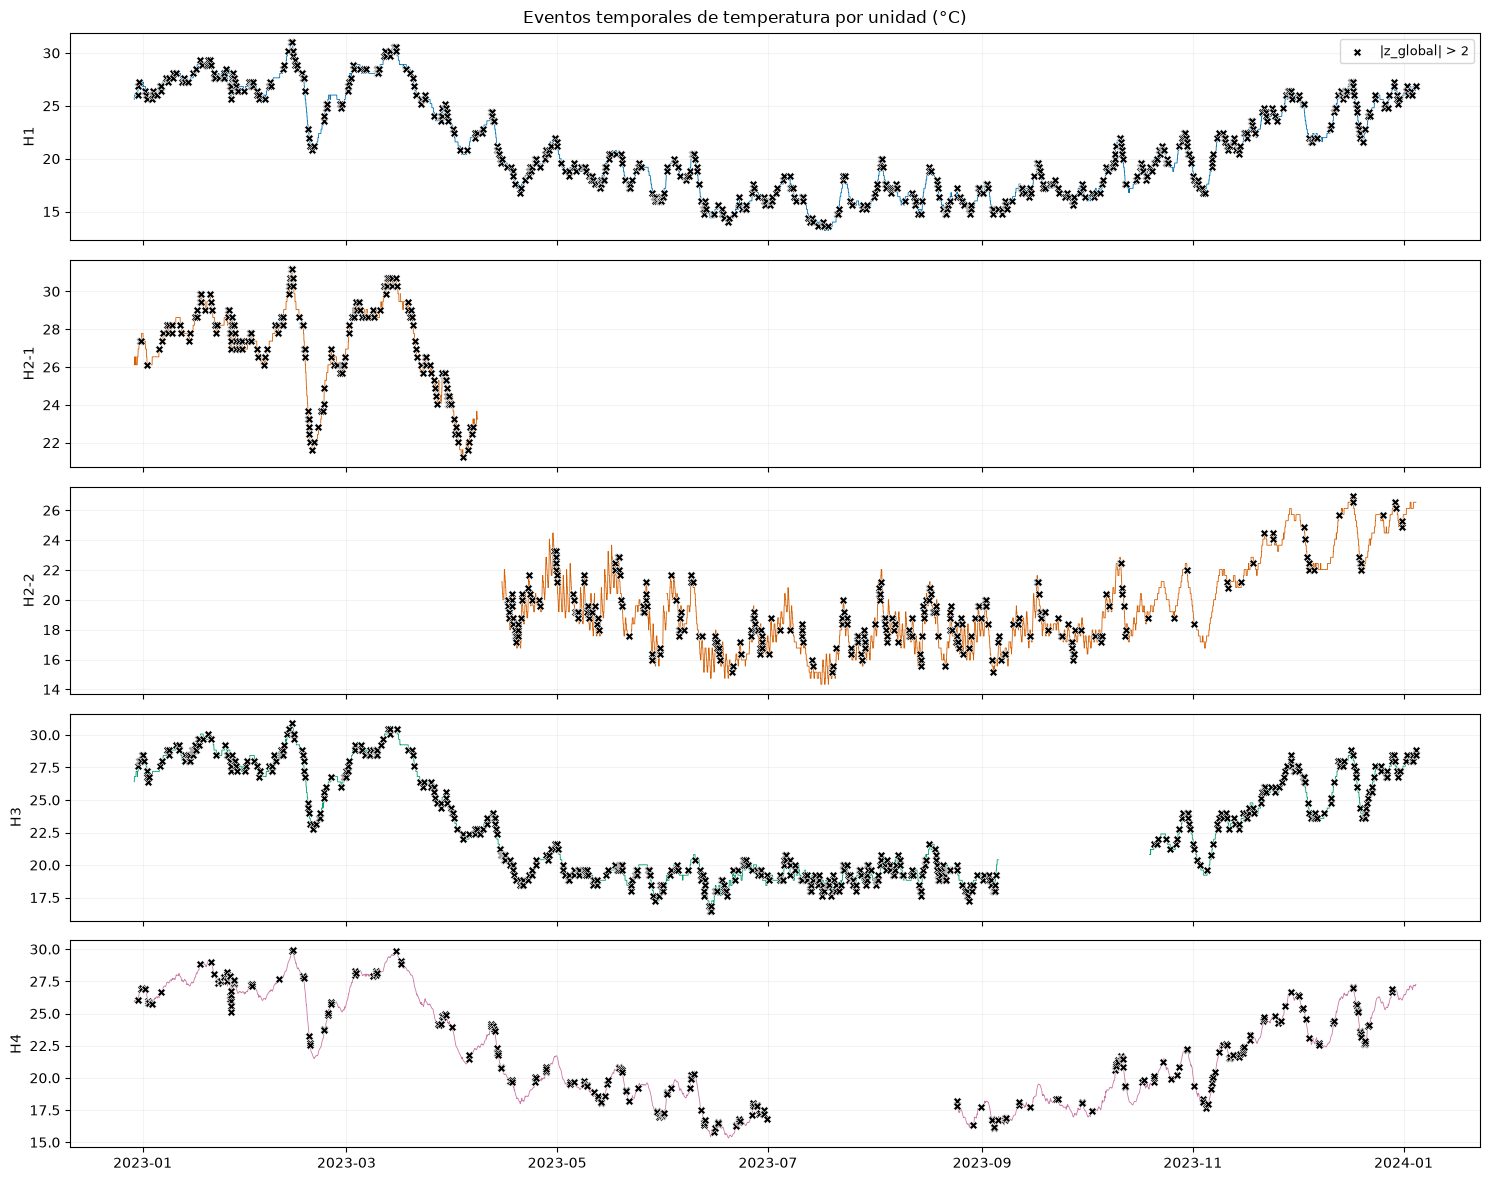

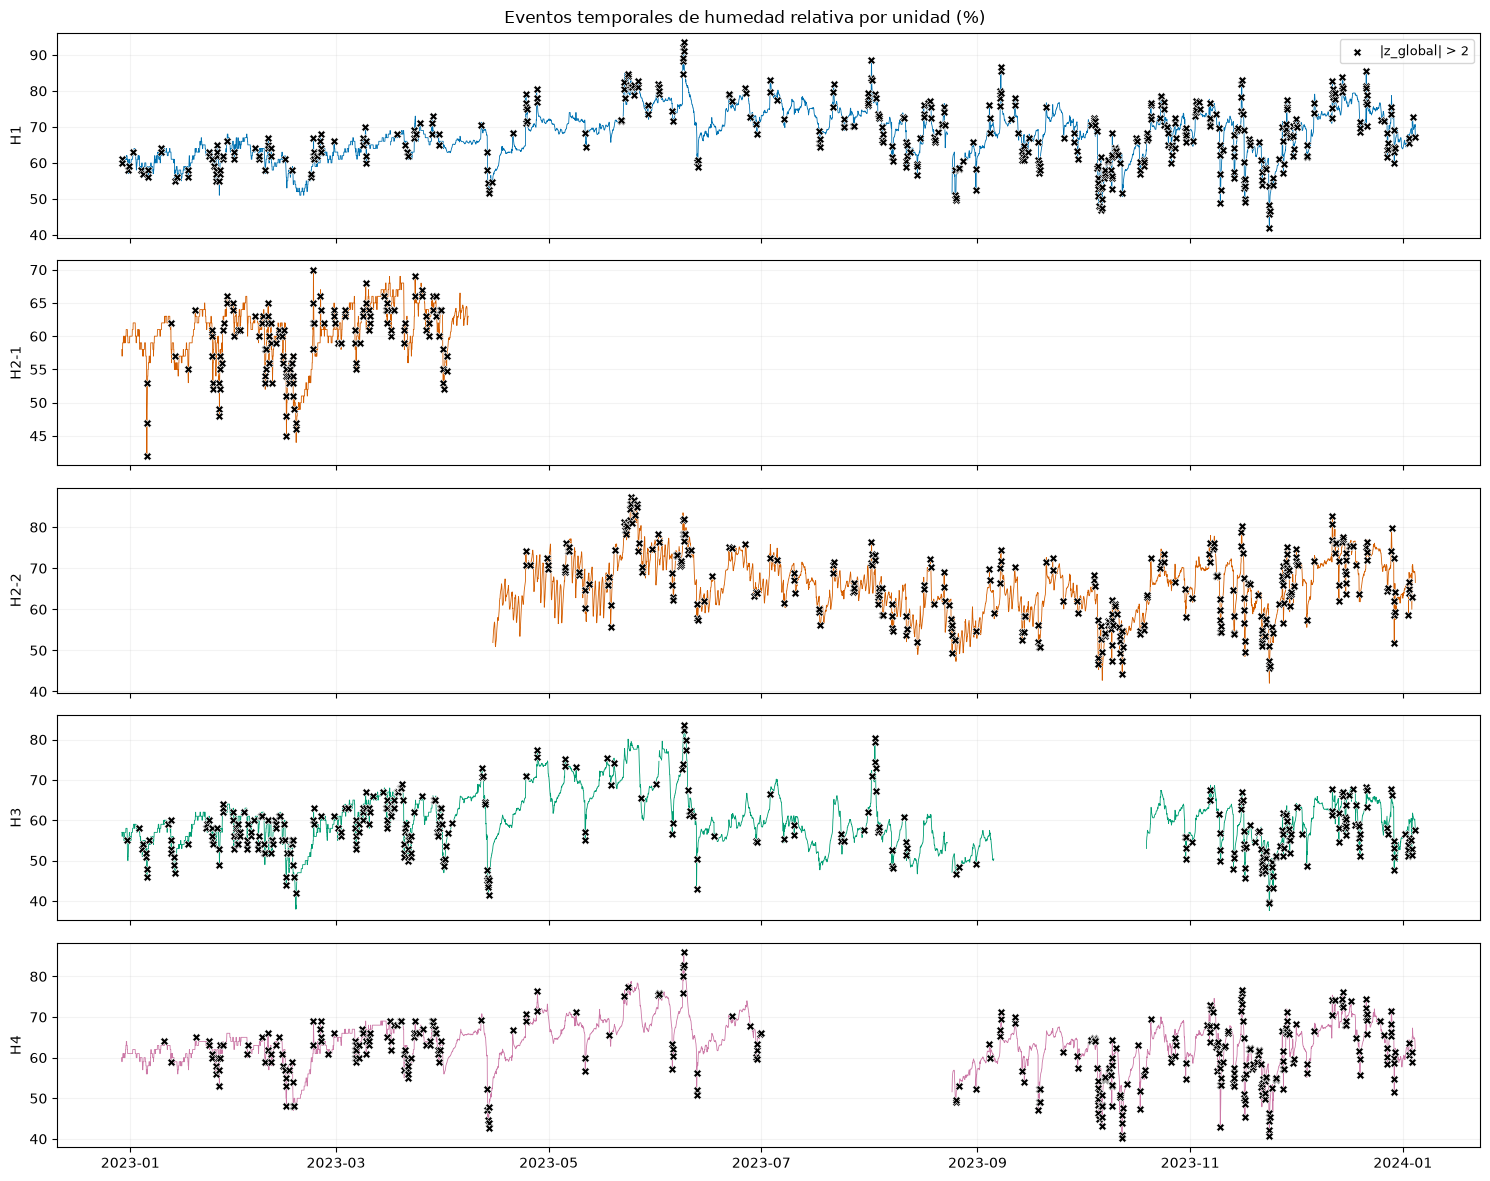

In [52]:
def graficar_eventos_variable(variable):
    series = (
        series_t
        if variable == 'T'
        else series_hr
    )

    detectores = (
        detecciones_temp
        if variable == 'T'
        else detecciones_hr
    )

    unidades = [
        u
        for u in unidades_analisis.index
        if u in detectores
    ]

    fig, ejes = plt.subplots(
        len(unidades),
        1,
        figsize=(15, 2.4 * len(unidades)),
        sharex=True,
    )

    ejes = np.atleast_1d(ejes)

    for ax, unidad in zip(ejes, unidades):
        serie = series[unidad]
        tabla = detectores[unidad]
        evento = (
            tabla['flag_evento']
            .fillna(False)
            .astype(bool)
        )

        ax.plot(
            serie.index,
            serie.values,
            linewidth=0.6,
            color=color_tramo(unidad),
        )

        ax.scatter(
            tabla.index[evento],
            serie.reindex(tabla.index[evento]),
            s=32,
            color='black',
            marker='X',
            edgecolor='white',
            linewidth=0.4,
            zorder=3,
            label='|z_global| > 2',
        )

        ax.set_ylabel(unidad)
        ax.grid(alpha=0.15)

    ejes[0].legend(
        loc='upper right',
        fontsize=9,
    )

    unidad_medida = (
        '°C'
        if variable == 'T'
        else '%'
    )

    fig.suptitle(
        f'Eventos temporales de '
        f'{ETIQUETA_VARIABLE[variable]} '
        f'por unidad ({unidad_medida})'
    )

    plt.tight_layout()
    plt.show()


graficar_eventos_variable('T')
graficar_eventos_variable('HR')

Los eventos aparecen a lo largo de todo el registro y no se restringen a valores máximos o mínimos de la serie: también surgen durante cambios de nivel, retornos después de un salto o perturbaciones sobre tramos relativamente estables.

En T, la lectura debe mantener la cautela instrumental de 1.1. H1, H2 y H3 registran en escalones relativamente gruesos, de modo que varios candidatos coinciden con cambios discretos pequeños en términos físicos pero grandes respecto de la dispersión residual. En H4, cuya resolución es mucho más fina, la desviación estándar residual es menor y esto puede generar valores $|z|$ muy altos aun para cambios absolutos moderados.

En HR, donde los cuatro sensores tienen una granularidad más comparable, la distribución visual de los eventos puede contrastarse de forma más directa entre puntos.

### 5.6 Frecuencia de los eventos a lo largo del año

> **Pregunta rectora:** ¿la frecuencia de eventos candidatos se mantiene estable o se concentra en determinados períodos?

Para cada unidad y mes se calcula el porcentaje de horas evaluables con $|z_t^{global}|>2$.

Se utiliza una proporción en lugar de un conteo absoluto para evitar que los meses con menor cobertura parezcan artificialmente menos activos. Los meses con menos de una semana de observaciones evaluables se excluyen del resumen.

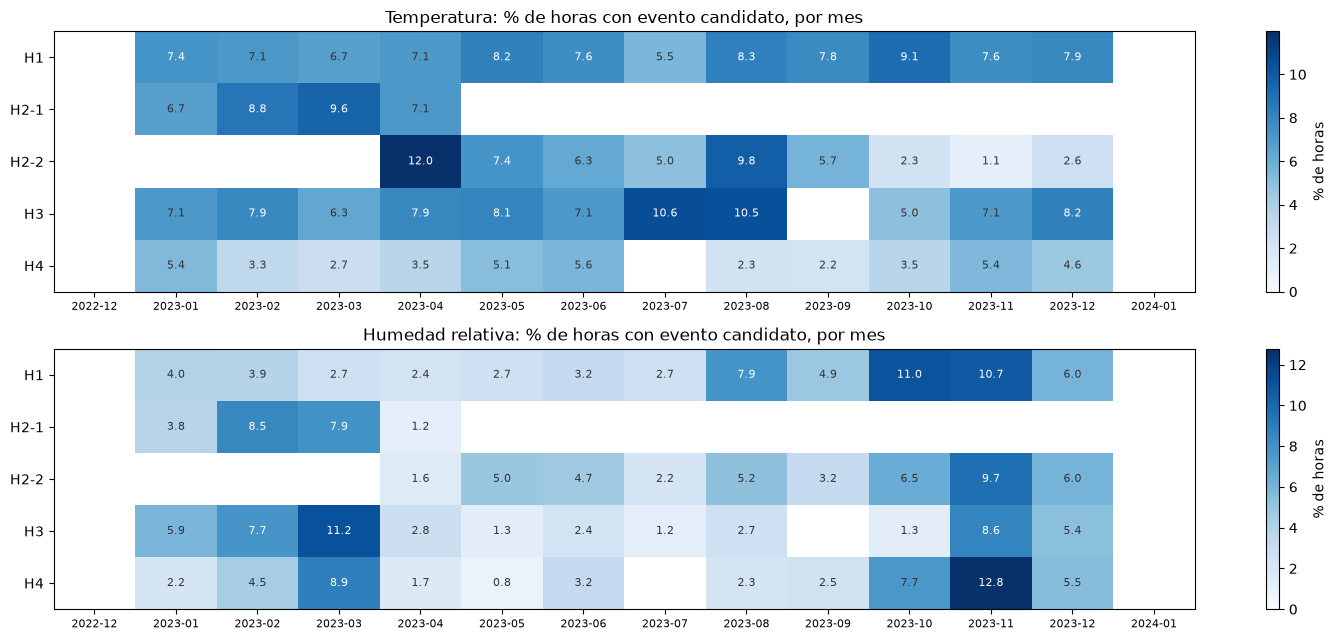

In [53]:
tasas_mensuales = {}

for variable, detectores in [
    ('T', detecciones_temp),
    ('HR', detecciones_hr),
]:
    tasas = {}

    for unidad in unidades_analisis.index:
        if unidad not in detectores:
            continue

        tabla = detectores[unidad]
        evaluable = tabla['z_global'].notna()

        evento = (
            tabla['flag_evento']
            .fillna(False)
            .astype(bool)
            & evaluable
        )

        horas = evaluable.resample('MS').sum()

        tasas[unidad] = (
            100
            * evento.resample('MS').sum()
            / horas
        ).where(
            horas >= 24 * 7
        )

    tasa = pd.DataFrame(tasas).T
    tasa.columns = tasa.columns.to_period('M')
    tasas_mensuales[variable] = tasa


fig, ejes = plt.subplots(
    2,
    1,
    figsize=(15, 6.5),
)

for ax, (variable, tasa) in zip(
    ejes,
    tasas_mensuales.items(),
):
    valores = tasa.to_numpy(dtype=float)

    imagen = ax.imshow(
        valores,
        aspect='auto',
        cmap='Blues',
        vmin=0,
    )

    ax.set_yticks(
        range(len(tasa.index)),
        tasa.index,
    )

    ax.set_xticks(
        range(len(tasa.columns)),
        [str(p) for p in tasa.columns],
        fontsize=8,
    )

    umbral_texto = (
        0.6 * np.nanmax(valores)
    )

    for (fila, col), valor in np.ndenumerate(
        valores
    ):
        if np.isfinite(valor):
            ax.text(
                col,
                fila,
                f'{valor:.1f}',
                ha='center',
                va='center',
                fontsize=8,
                color=(
                    'white'
                    if valor > umbral_texto
                    else '#333333'
                ),
            )

    ax.set_title(
        f'{ETIQUETA_VARIABLE[variable].capitalize()}: '
        '% de horas con evento candidato, por mes'
    )

    fig.colorbar(
        imagen,
        ax=ax,
        label='% de horas',
    )

plt.tight_layout()
plt.show()

La frecuencia mensual no presenta un patrón común claro en T. H1 se mantiene aproximadamente entre 5,5 % y 9,1 % durante gran parte del año; H3 alcanza alrededor de 10,5 % en julio-agosto; H4 permanece en valores más bajos, alrededor de 2–6 %. H2-2 cambia con fuerza dentro de su período de observación: llega a 12 % en abril y cae por debajo de 3 % en octubre-diciembre.

En HR aparece una estructura temporal más compartida. Varias unidades muestran frecuencias bajas entre abril y julio y aumentos posteriores. En octubre-noviembre destacan H1 (≈11 % y 10,7 %), H2-2 (6,5 % y 9,7 %), H3 (1,3 % y 8,6 %) y H4 (7,7 % y 12,8 %). H2-1 presenta además una concentración temprana en febrero-marzo.

El patrón mensual refuerza que la frecuencia de eventos no es constante y que HR muestra cambios temporales más sincronizados entre puntos que T.

### 5.7 Registro de anomalías

El catálogo horario se exporta como registro de eventos candidatos del Objetivo 1. Cada fila corresponde a una hora marcada e incluye unidad, sensor, valor observado, innovación, $z_t^{global}$ y variables de contexto como conservación, simultaneidad y eventos documentados.

In [54]:
RUTA_REGISTRO = Path(
    '../outputs/registro_anomalias_objetivo1.csv'
)
RUTA_REGISTRO.parent.mkdir(
    parents=True,
    exist_ok=True,
)

catalogo_eventos[
    columnas_catalogo
].to_csv(
    RUTA_REGISTRO,
    index=False,
)

print(
    f'{RUTA_REGISTRO}: '
    f'{len(catalogo_eventos)} filas'
)

..\outputs\registro_anomalias_objetivo1.csv: 3814 filas


## 6. Integración y contextualización de los eventos

Las secciones anteriores abordaron dos aspectos complementarios de las condiciones ambientales: su **relevancia para la conservación preventiva**, evaluada mediante criterios específicos, y su **comportamiento temporal**, a partir del cual se identificaron candidatos de anomalía. En esta sección se integran ambos enfoques para contextualizar las detecciones obtenidas.

Se consideran tres fuentes de información:

1. criterios de conservación;
2. simultaneidad entre puntos de medición y entre T y HR;
3. eventos documentados, especialmente la rutina de ventilación.

En HR se incorpora además humedad absoluta como herramienta física complementaria.

Las coincidencias son temporales y descriptivas. Pueden ser consistentes con fenómenos conocidos por el equipo del proyecto, pero no identifican por sí solas una causa.

### 6.1 Rareza temporal × relevancia para conservación

> **Pregunta rectora:** ¿hasta qué punto los eventos candidatos coinciden con condiciones relevantes para conservación?

Se comparan ambas dimensiones hora por hora.

No se espera una correspondencia completa: la rareza temporal evalúa cuán grande es una innovación respecto de la dinámica residual habitual, mientras que los criterios de conservación evalúan la relevancia física de los niveles o fluctuaciones alcanzados.

In [55]:
def construir_cruce_temporal_conservacion(detectores, variable):
    resultados = []
    flags_conservacion = FLAGS_CONSERVACION_POR_VARIABLE[variable]
    for unidad, tabla in detectores.items():
        if tabla.empty:
            continue
        cons = condiciones_conservacion.loc[condiciones_conservacion['unidad'] == unidad].set_index('fecha').sort_index()
        idx = tabla.index.intersection(cons.index)
        if len(idx) == 0:
            continue
        temporal = tabla.reindex(idx)['flag_evento'].fillna(False).astype(bool)
        conservacion = cons.reindex(idx)[flags_conservacion].fillna(False).any(axis=1).astype(bool)
        sensor = unidades_analisis.loc[unidad, 'sensor']
        bloque = pd.DataFrame({
            'fecha': idx,
            'variable': variable,
            'unidad': unidad,
            'sensor': sensor,
            'temporal': temporal.to_numpy(),
            'conservacion': conservacion.to_numpy(),
        })
        bloque['categoria_cruce'] = np.select(
            [
                bloque['temporal'] & bloque['conservacion'],
                bloque['temporal'] & ~bloque['conservacion'],
                ~bloque['temporal'] & bloque['conservacion'],
            ],
            ['temporal + conservación', 'solo temporal', 'solo conservación'],
            default='ninguna',
        )
        resultados.append(bloque)
    if not resultados:
        return pd.DataFrame()
    return pd.concat(resultados, ignore_index=True)
cruce_temporal_conservacion = pd.concat(
    [
        construir_cruce_temporal_conservacion(detecciones_temp, 'T'),
        construir_cruce_temporal_conservacion(detecciones_hr, 'HR'),
    ],
    ignore_index=True,
)

def tabla_2x2_cruce(tabla, variable):
    bloque = tabla.loc[tabla['variable'] == variable]
    cruzada = pd.crosstab(
        bloque['temporal'],
        bloque['conservacion'],
    ).reindex(index=[False, True], columns=[False, True], fill_value=0)
    cruzada.index = ['No anómalo temporalmente', 'Anómalo temporalmente']
    cruzada.columns = ['Sin criterio de conservación', 'Con criterio de conservación']
    return cruzada
tabla_2x2_temp = tabla_2x2_cruce(cruce_temporal_conservacion, 'T')
tabla_2x2_hr = tabla_2x2_cruce(cruce_temporal_conservacion, 'HR')
mostrar('Temperatura - cruce temporal × conservación:', tabla_2x2_temp)
mostrar('HR - cruce temporal × conservación:', tabla_2x2_hr)

Temperatura - cruce temporal × conservación:


,Sin criterio de conservación,Con criterio de conservación
No anómalo temporalmente,30503,386
Anómalo temporalmente,2099,45


HR - cruce temporal × conservación:


,Sin criterio de conservación,Con criterio de conservación
No anómalo temporalmente,28921,2442
Anómalo temporalmente,1261,409


Rareza temporal y relevancia para conservación se superponen sólo parcialmente, y la magnitud de ese solapamiento depende mucho de la variable.

En T, **45 de 2 144 eventos candidatos (2,1 %)** coinciden con algún criterio de conservación. En HR, la coincidencia es mucho mayor: **409 de 1 670 eventos (24,5 %)**.

La relación inversa también es incompleta: sólo una fracción de las horas con criterio de conservación es temporalmente inusual. Esto confirma que ambas dimensiones responden preguntas distintas:

> **habitual no significa necesariamente adecuado para conservación; inusual no significa necesariamente riesgoso.**

La mayor coincidencia en HR indica que, bajo el detector final, los cambios temporalmente inusuales de esta variable se relacionan con mayor frecuencia con condiciones de interés para conservación que los de T, pero una dimensión no se utiliza para validar a la otra.

### 6.2 Simultaneidad entre puntos y variables

> **Pregunta rectora:** ¿los eventos candidatos tienden a aparecer de manera aislada o simultáneamente en distintos puntos o variables?

Se analizan dos formas de simultaneidad:

1. varios sensores presentan un evento de la misma variable en la misma hora;
2. T y HR presentan eventos simultáneos dentro de una misma unidad.

In [56]:
def simultaneidad_entre_sensores(catalogo):
    filas = {}
    for variable, d in catalogo.groupby('variable'):
        n_sensores = d.groupby('fecha')['sensor'].nunique()
        compartidas = n_sensores[n_sensores >= 2].index
        d_comp = d[d['fecha'].isin(compartidas)]
        mismo_signo = d_comp.groupby('fecha')['z_global'].apply(lambda z: (z > 0).all() or (z < 0).all())
        filas[variable] = {
            'eventos': len(d),
            'horas_con_evento': len(n_sensores),
            'horas_1_sensor': int((n_sensores == 1).sum()),
            'horas_2_sensores': int((n_sensores == 2).sum()),
            'horas_3_o_4_sensores': int((n_sensores >= 3).sum()),
            'pct_eventos_compartidos': 100 * len(d_comp) / len(d),
            'pct_horas_compartidas_mismo_signo': 100 * mismo_signo.mean() if len(mismo_signo) else np.nan,
            'pct_compartidos_en_ventilacion': 100 * d_comp['coincide_ventilacion_programada'].mean() if len(d_comp) else np.nan,
            'pct_todos_en_ventilacion': 100 * d['coincide_ventilacion_programada'].mean(),
        }
    return pd.DataFrame(filas).T


mostrar('Simultaneidad de eventos entre sensores:', simultaneidad_entre_sensores(catalogo_eventos), 1)

Simultaneidad de eventos entre sensores:


,eventos,horas_con_evento,horas_1_sensor,horas_2_sensores,horas_3_o_4_sensores,pct_eventos_compartidos,pct_horas_compartidas_mismo_signo,pct_compartidos_en_ventilacion,pct_todos_en_ventilacion
HR,1670.0,1092.0,687.0,261.0,144.0,58.9,86.9,46.1,35.8
T,2144.0,1851.0,1596.0,225.0,30.0,25.6,72.9,19.2,15.6


La diferencia entre T y HR es clara en la simultaneidad espacial.

En HR, **58,9 % de los eventos** ocurre en una hora en la que al menos otro sensor también presenta un evento. En T esa proporción es **25,6 %**. Además, en las horas compartidas los eventos tienen el mismo signo en 86,9 % de los casos de HR y en 72,9 % de T.

La relación con la ventilación también es más fuerte en HR: 46,1 % de sus eventos compartidos ocurre dentro de la ventana documentada, frente a 19,2 % en T.

Por lo tanto, los eventos de HR muestran una componente temporal común entre puntos mucho más marcada. En T predomina una dinámica más local, además de estar condicionada por las diferencias de granularidad instrumental.

In [57]:
def resumen_conjunto_t_hr(catalogo):
    if catalogo.empty:
        return pd.DataFrame()
    base = catalogo[['fecha', 'sensor', 'variable']].drop_duplicates()
    pivot = base.assign(presente=True).pivot_table(
        index=['fecha', 'sensor'],
        columns='variable',
        values='presente',
        aggfunc='max',
        fill_value=False,
    ).reset_index()
    if 'T' not in pivot:
        pivot['T'] = False
    if 'HR' not in pivot:
        pivot['HR'] = False
    pivot['categoria'] = np.select(
        [pivot['T'] & pivot['HR'], pivot['T'], pivot['HR']],
        ['T + HR', 'solo T', 'solo HR'],
        default='ninguna',
    )
    return pivot.groupby(['sensor', 'categoria']).size().unstack(fill_value=0)
resumen_conjunto_obj1 = resumen_conjunto_t_hr(catalogo_eventos)
mostrar('Síntesis conjunta T-HR por sensor:', resumen_conjunto_obj1)

Síntesis conjunta T-HR por sensor:


categoria,T + HR,solo HR,solo T
sensor,,,
H1,67,393,602
H2,55,415,480
H3,43,328,590
H4,55,314,252


La coincidencia T-HR dentro de un mismo sensor es minoritaria. Se observan **220 coincidencias** en total: 67 en H1, 55 en H2, 43 en H3 y 55 en H4.

La mayoría de las horas marcadas pertenece sólo a una de las dos variables. La simultaneidad T-HR agrega contexto físico cuando aparece, pero no constituye una definición alternativa de evento ni implica que ambas variables respondan necesariamente al mismo mecanismo.

### 6.3 Contexto documental: ventilación

> **Pregunta rectora:** ¿los eventos candidatos coinciden temporalmente con operaciones documentadas de la reserva?

El catálogo se cruza con la rutina de ventilación documentada en el TFI. Un evento se considera coincidente con ventilación cuando ocurre dentro de la franja horaria programada.

La condición *Reserva visitable* se conserva como metadata, pero no se utiliza como categoría principal debido a su extensa duración y baja especificidad temporal.

In [58]:
tabla_contexto_eventos = catalogo_eventos.groupby(['variable', 'categoria_evento']).size().unstack(fill_value=0)
columnas_orden = [
    'temporal',
    'temporal + conservación',
    'temporal + ventilación',
    'temporal + conservación + ventilación',
]
tabla_contexto_eventos = tabla_contexto_eventos.reindex(columns=columnas_orden, fill_value=0)
display(tabla_contexto_eventos.assign(Total=tabla_contexto_eventos.sum(axis=1)))

categoria_evento,temporal,temporal + conservación,temporal + ventilación,temporal + conservación + ventilación,Total
variable,,,,,
HR,903,169,358,240,1670
T,1768,41,331,4,2144


La ventilación coincide con una fracción considerablemente mayor de los eventos de HR que de los de T.

En HR, **598 de 1 670 eventos (35,8 %)** ocurren dentro de la ventana documentada de ventilación; 240 de ellos coinciden además con algún criterio de conservación. En T, **335 de 2 144 (15,6 %)** coinciden con ventilación y sólo 4 reúnen simultáneamente ventilación y conservación.

La diferencia refuerza la lectura de una dinámica de HR más conectada temporalmente con la operación documentada de la reserva. La coincidencia sigue siendo descriptiva: puede ser consistente con observaciones físicas del equipo, pero no identifica por sí sola una causa exterior.

### 6.4 Humedad absoluta alrededor de eventos de HR

> **Pregunta rectora:** ¿los eventos de HR están acompañados por cambios en el contenido de vapor del aire?

Para complementar la interpretación de los eventos de humedad relativa (HR), se calcula la humedad absoluta (HA) a partir de T y HR, utilizando la formulación empleada en el TFI de Scoccimarro (2024):

$$
HA = 1323.4 \left(\frac{HR}{100}\right)
\frac{\exp\left(\frac{17.27T}{T+237.3}\right)}{T+273.15}.
$$

Se consideran los registros candidatos de anomalía de HR que coinciden con criterios de conservación, con la franja horaria de ventilación o con ambos contextos.

Para cada registro se examinan T, HR y HA en la hora anterior, la hora del evento y la siguiente:

$$
HA_{t-1}, \quad HA_t, \quad HA_{t+1}.
$$

El análisis se concentra en los cambios inmediatos de HA, complementados con los cambios de T y HR. Esto permite examinar si las variaciones de HR están acompañadas por modificaciones en el contenido de vapor del aire interior o principalmente por cambios térmicos.

In [59]:
def humedad_absoluta(temperatura_c, hr_pct):
    T = np.asarray(temperatura_c, dtype=float)
    HR = np.asarray(hr_pct, dtype=float)
    return 1323.4 * (HR / 100.0) * np.exp(17.27 * T / (T + 237.3)) / (T + 273.15)


COLUMNAS_SENSOR = {
    'H1': {'T': 'H1 T (°C)', 'HR': 'H1 HRCal (%)'},
    'H2': {'T': 'H2 T (°C)', 'HR': 'H2 HRCal (%)'},
    'H3': {'T': 'H3 T (°C)', 'HR': 'H3 HRCal (%)'},
    'H4': {'T': 'H4 T (°C)', 'HR': 'H4 HRCal (%)'},
}

CATEGORIAS_HA = {
    'temporal + conservación',
    'temporal + ventilación',
    'temporal + conservación + ventilación',
}

eventos_hr_para_ha = catalogo_eventos.loc[
    (catalogo_eventos['variable'] == 'HR')
    & catalogo_eventos['categoria_evento'].isin(CATEGORIAS_HA)
].copy().sort_values(['fecha', 'sensor'])

print('Registros candidatos de HR seleccionados:', len(eventos_hr_para_ha))


Registros candidatos de HR seleccionados: 767


In [60]:
def obtener_contexto_ha_evento(fila, df_original):
    """Obtiene T, HR y HA en t-1, t y t+1."""
    fecha = pd.Timestamp(fila['fecha'])
    sensor = fila['sensor']
    columnas = COLUMNAS_SENSOR[sensor]
    col_t = columnas['T']
    col_hr = columnas['HR']
    fechas = {'tm1': fecha - pd.Timedelta(hours=1), 't': fecha, 'tp1': fecha + pd.Timedelta(hours=1)}
    salida = {}
    for sufijo, fecha_i in fechas.items():
        if fecha_i not in df_original.index:
            salida[f'T_{sufijo}'] = np.nan
            salida[f'HR_{sufijo}'] = np.nan
            salida[f'HA_{sufijo}'] = np.nan
            continue
        T_i = df_original.at[fecha_i, col_t]
        HR_i = df_original.at[fecha_i, col_hr]
        salida[f'T_{sufijo}'] = T_i
        salida[f'HR_{sufijo}'] = HR_i
        salida[f'HA_{sufijo}'] = (
            float(humedad_absoluta(T_i, HR_i))
            if pd.notna(T_i) and pd.notna(HR_i) else np.nan
        )
    return pd.Series(salida)


contexto_ha = eventos_hr_para_ha.apply(obtener_contexto_ha_evento, axis=1, df_original=df)

analisis_ha_eventos = pd.concat([
    eventos_hr_para_ha.reset_index(drop=True),
    contexto_ha.reset_index(drop=True),
], axis=1)

for variable in ['T', 'HR', 'HA']:
    analisis_ha_eventos[f'delta_{variable}_pre'] = (
        analisis_ha_eventos[f'{variable}_t'] - analisis_ha_eventos[f'{variable}_tm1']
    )

analisis_ha_eventos['delta_HA_post'] = (
    analisis_ha_eventos['HA_tp1'] - analisis_ha_eventos['HA_t']
)

columnas_ha_principales = [
    'fecha',
    'unidad',
    'sensor',
    'categoria_evento',
    'z_global',
    'T_tm1',
    'T_t',
    'HR_tm1',
    'HR_t',
    'HA_tm1',
    'HA_t',
    'HA_tp1',
    'delta_T_pre',
    'delta_HR_pre',
    'delta_HA_pre',
    'delta_HA_post',
]

tabla_ha_eventos = analisis_ha_eventos[columnas_ha_principales].copy()
display(redondear_numericas(tabla_ha_eventos, 3).head())

,fecha,unidad,sensor,categoria_evento,z_global,T_tm1,T_t,HR_tm1,HR_t,HA_tm1,HA_t,HA_tp1,delta_T_pre,delta_HR_pre,delta_HA_pre,delta_HA_post
0,2023-01-05 17:00:00,H2-1,H2,temporal + conservación,-8.139,26.54,26.54,53.0,47.0,13.297,11.792,10.780,0.00,-6.0,-1.505,-1.012
1,2023-01-05 18:00:00,H2-1,H2,temporal + conservación,-7.093,26.54,26.95,47.0,42.0,11.792,10.780,12.063,0.41,-5.0,-1.012,1.283
2,2023-01-05 19:00:00,H2-1,H2,temporal + conservación,2.880,26.95,26.95,42.0,47.0,10.780,12.063,12.576,0.00,5.0,1.283,0.513
3,2023-01-13 13:00:00,H3,H3,temporal + conservación,-2.402,28.02,28.02,51.0,49.0,13.885,13.340,13.340,0.00,-2.0,-0.545,0.000
4,2023-01-27 13:00:00,H3,H3,temporal + conservación,2.601,28.02,28.02,63.0,64.0,17.152,17.424,17.152,0.00,1.0,0.272,-0.272


**Dirección y magnitud del cambio de HA**

Para caracterizar la variación de HA al llegar al registro candidato, se calcula:

$$
\Delta HA_t = HA_t-HA_{t-1}.
$$

Se examinan la dirección y la magnitud de los cambios según el contexto asociado a cada detección, distinguiendo entre criterios de conservación, ventilación y la coincidencia de ambos.

In [61]:
def pct_disminucion(serie):
    s = serie.dropna()
    return 100 * (s < 0).mean() if len(s) else np.nan


def pct_aumento(serie):
    s = serie.dropna()
    return 100 * (s > 0).mean() if len(s) else np.nan


resumen_ha_categoria = analisis_ha_eventos.groupby('categoria_evento').agg(
    n_registros=('fecha', 'size'),
    n_pares_validos=('delta_HA_pre', 'count'),
    delta_HA_mediana=('delta_HA_pre', 'median'),
    abs_delta_HA_mediana=('delta_HA_pre', lambda x: x.abs().median()),
    pct_disminucion=('delta_HA_pre', pct_disminucion),
    pct_aumento=('delta_HA_pre', pct_aumento),
).sort_index()

display(resumen_ha_categoria.round(3))

,n_registros,n_pares_validos,delta_HA_mediana,abs_delta_HA_mediana,pct_disminucion,pct_aumento
categoria_evento,,,,,,
temporal + conservación,169,169,0.085,0.410,42.012,53.846
temporal + conservación + ventilación,240,238,-0.185,0.512,55.042,44.118
temporal + ventilación,358,356,-0.189,0.446,55.056,42.135


**Resultados por sensor**

Se desagregan los cambios de HA por sensor y contexto para examinar si las tendencias generales se mantienen entre los distintos puntos de medición. Esta desagregación permite identificar posibles diferencias que quedarían ocultas al resumir conjuntamente todas las observaciones.


In [62]:
resumen_ha_sensor = analisis_ha_eventos.groupby([
    'sensor',
    'categoria_evento',
]).agg(
    n_pares_validos=('delta_HA_pre', 'count'),
    delta_HA_mediana=('delta_HA_pre', 'median'),
    abs_delta_HA_mediana=('delta_HA_pre', lambda x: x.abs().median()),
    pct_disminucion=('delta_HA_pre', pct_disminucion),
).sort_index()

display(resumen_ha_sensor.round(3))

n_pares_validos  \
sensor categoria_evento                                         
H1     temporal + conservación                             59   
       temporal + conservación + ventilación               93   
       temporal + ventilación                             101   
H2     temporal + conservación                             60   
       temporal + conservación + ventilación               52   
       temporal + ventilación                              99   
H3     temporal + conservación                             26   
       temporal + conservación + ventilación               35   
       temporal + ventilación                              64   
H4     temporal + conservación                             24   
       temporal + conservación + ventilación               58   
       temporal + ventilación                              92   

                                              delta_HA_mediana  \
sensor categoria_evento                                          
H1     temporal + conservación                           0.179   
       temporal + conservación + ventilación             0.212   
       temporal + ventilación                           -0.279   
H2     temporal + conservación                           0.060   
       temporal + conservación + ventilación            -0.247   
       temporal + ventilación                           -0.274   
H3     temporal + conservación                          -0.049   
       temporal + conservación + ventilación            -0.407   
       temporal + ventilación                            0.000   
H4     temporal + conservación                           0.095   
       temporal + conservación + ventilación            -0.219   
       temporal + ventilación                           -0.044   

                                              abs_delta_HA_mediana  \
sensor categoria_evento                                              
H1     temporal + conservación                               0.359   
       temporal + conservación + ventilación                 0.510   
       temporal + ventilación                                0.452   
H2     temporal + conservación                               0.416   
       temporal + conservación + ventilación                 0.550   
       temporal + ventilación                                0.419   
H3     temporal + conservación                               0.350   
       temporal + conservación + ventilación                 0.543   
       temporal + ventilación                                0.409   
H4     temporal + conservación                               0.724   
       temporal + conservación + ventilación                 0.445   
       temporal + ventilación                                0.510   

                                              pct_disminucion  
sensor categoria_evento                                        
H1     temporal + conservación                         40.678  
       temporal + conservación + ventilación           43.011  
       temporal + ventilación                          59.406  
H2     temporal + conservación                         38.333  
       temporal + conservación + ventilación           55.769  
       temporal + ventilación                          60.606  
H3     temporal + conservación                         50.000  
       temporal + conservación + ventilación           71.429  
       temporal + ventilación                          43.750  
H4     temporal + conservación                         45.833  
       temporal + conservación + ventilación           63.793  
       temporal + ventilación                          52.174

**Distribución de los cambios inmediatos de HA**

Para complementar las medidas resumidas, se examina la distribución de los cambios de HA entre la hora anterior y el registro candidato. El gráfico permite comparar la dirección, la magnitud y la dispersión de estos cambios según el contexto de cada detección.


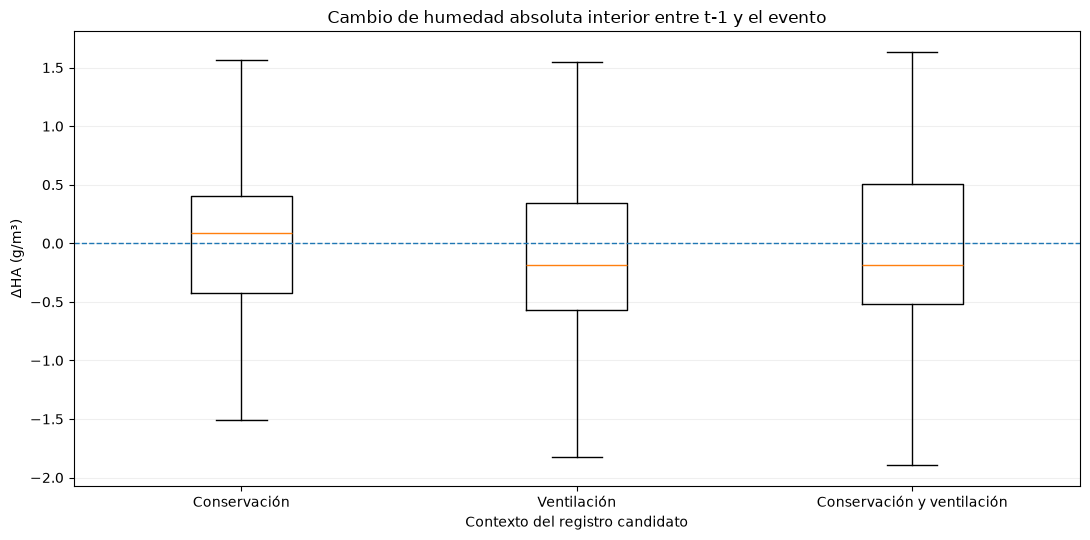

In [63]:
orden_categorias = [
    'temporal + conservación',
    'temporal + ventilación',
    'temporal + conservación + ventilación',
]

etiquetas_categorias = {
    'temporal + conservación': 'Conservación',
    'temporal + ventilación': 'Ventilación',
    'temporal + conservación + ventilación': 'Conservación y ventilación',
}

datos_boxplot = []
labels_boxplot = []
for categoria in orden_categorias:
    valores = analisis_ha_eventos.loc[
        analisis_ha_eventos['categoria_evento'] == categoria,
        'delta_HA_pre',
    ].dropna().to_numpy()
    if len(valores) == 0:
        continue
    datos_boxplot.append(valores)
    labels_boxplot.append(etiquetas_categorias[categoria])

if datos_boxplot:
    plt.figure(figsize=(11, 5.5))
    plt.boxplot(datos_boxplot, tick_labels=labels_boxplot, showfliers=False)
    plt.axhline(0, linewidth=1, linestyle='--')
    plt.title('Cambio de humedad absoluta interior entre t-1 y el evento')
    plt.ylabel('ΔHA (g/m³)')
    plt.xlabel('Contexto del registro candidato')
    plt.grid(axis='y', alpha=0.2)
    plt.tight_layout()
    plt.show()

**Interpretación de los resultados**

Se analizaron **767 registros horarios candidatos de anomalía de HR** coincidentes con criterios de conservación y/o con la franja de ventilación.

En los registros asociados a ventilación, la HA calculada disminuye entre \(t-1\) y \(t\) en aproximadamente el **55 %** de los casos, tanto cuando coincide únicamente con ventilación (55,1 %) como cuando también coincide con criterios de conservación (55,0 %). Las medianas de los cambios inmediatos son negativas en ambos grupos, cercanas a −0,19 g/m³.

En los registros coincidentes con conservación, pero no con ventilación, los aumentos de HA son ligeramente más frecuentes que las disminuciones (53,9 % frente a 42,0 %), aunque la mediana del cambio es positiva y pequeña.

La desagregación por sensor muestra diferencias entre puntos de medición, por lo que no se observa un comportamiento uniforme en toda la reserva. En conjunto, los resultados indican una ligera predominancia de disminuciones de HA entre los registros coincidentes con la franja de ventilación, aunque las magnitudes observadas deben interpretarse considerando las características instrumentales de las mediciones.

El análisis se limita a las condiciones interiores y permite contextualizar las detecciones de HR, pero no establecer el origen de los cambios observados. La relación temporal entre las condiciones ambientales interiores y exteriores, incluyendo sus posibles rezagos y persistencia, se abordará en el Objetivo 2.

## 7. Síntesis del Objetivo 1 y puente al Objetivo 2

El Objetivo 1 permitió construir una **caracterización dinámica y reproducible del microclima interior**, orientada no sólo a describir los valores registrados, sino también a comprender cómo varían, qué estructuras temporales presentan y qué eventos se apartan de su comportamiento habitual.

### 7.1 Perfil temporal consolidado

La tabla siguiente resume, por **unidad de análisis** y variable, los principales resultados de caracterización temporal: cobertura, nivel, componentes STL, periodicidades, persistencia y fluctuación a 24 h.

In [64]:
def _valor_acf(diccionario, unidad, lag):
    if unidad not in diccionario:
        return np.nan

    tabla = diccionario[unidad]

    if lag not in tabla.index:
        return np.nan

    return tabla.loc[lag, 'correlacion']


def _periodo_dominante(picos, unidad):
    r = picos.loc[
        (picos['unidad'] == unidad)
        & (picos['orden'] == 1)
    ]

    if r.empty:
        return np.nan

    return r.iloc[0]['periodo_h']


def resumen_basico_series(series):
    filas = []

    for unidad, serie in series.items():
        s = serie.dropna()

        filas.append({
            'unidad': unidad,
            'media': s.mean(),
            'mediana': s.median(),
            'sd': s.std(),
            'min': s.min(),
            'max': s.max(),
        })

    return pd.DataFrame(filas).set_index('unidad')


def construir_perfil_temporal(
    variable,
    series,
    resumen_descomp,
    picos,
    acf_nivel,
    acf_resto,
    cambios,
):
    descriptiva = resumen_basico_series(series)
    filas = []

    for unidad in unidades_analisis.index:
        if unidad not in series:
            continue

        meta = unidades_analisis.loc[unidad]

        filas.append({
            'variable': variable,
            'unidad': unidad,
            'sensor': meta['sensor'],
            'inicio': meta['inicio'],
            'fin': meta['fin'],
            'n_bloques': meta['n_bloques'],
            'dias_observados': meta['dias_observados'],
            'cobertura_en_bloques_pct': meta['cobertura_en_bloques_pct'],
            'media': descriptiva.loc[unidad, 'media'],
            'mediana': descriptiva.loc[unidad, 'mediana'],
            'sd': descriptiva.loc[unidad, 'sd'],
            'min': descriptiva.loc[unidad, 'min'],
            'max': descriptiva.loc[unidad, 'max'],
            'rango_lento_5_95': (
                resumen_descomp.loc[unidad, 'rango_lento_5_95']
                if unidad in resumen_descomp.index
                else np.nan
            ),
            'amplitud_ciclo_24h': (
                resumen_descomp.loc[unidad, 'amplitud_diaria_tipica']
                if unidad in resumen_descomp.index
                else np.nan
            ),
            'sd_remainder': (
                resumen_descomp.loc[unidad, 'std_resto']
                if unidad in resumen_descomp.index
                else np.nan
            ),
            'pico_espectral_principal_h': _periodo_dominante(
                picos,
                unidad,
            ),
            'acf_nivel_1h': _valor_acf(acf_nivel, unidad, 1),
            'acf_nivel_24h': _valor_acf(acf_nivel, unidad, 24),
            'acf_remainder_1h': _valor_acf(acf_resto, unidad, 1),
            'p95_abs_cambio_24h': (
                cambios.loc[(unidad, 24), 'p95_abs']
                if (unidad, 24) in cambios.index
                else np.nan
            ),
        })

    return (
        pd.DataFrame(filas)
        .set_index(['variable', 'unidad'])
    )


perfil_temp = construir_perfil_temporal(
    'T',
    series_t,
    resumen_descomp_temp,
    picos_temp,
    acf_temp,
    acf_resid_temp,
    cambios_temp,
)

perfil_hr = construir_perfil_temporal(
    'HR',
    series_hr,
    resumen_descomp_hr,
    picos_hr,
    acf_hr,
    acf_resid_hr,
    cambios_hr,
)

perfil_temporal_obj1 = pd.concat(
    [perfil_temp, perfil_hr]
)

mostrar(
    'Perfil temporal final por unidad:',
    perfil_temporal_obj1,
)

Perfil temporal final por unidad:


sensor              inicio                 fin  n_bloques  \
variable unidad                                                             
T        H1         H1 2022-12-29 14:00:00 2024-01-04 14:00:00          1   
         H2-1       H2 2022-12-29 14:00:00 2023-04-07 23:00:00          1   
         H2-2       H2 2023-04-15 00:00:00 2024-01-04 14:00:00          1   
         H3         H3 2022-12-29 14:00:00 2024-01-04 14:00:00          2   
         H4         H4 2022-12-29 14:00:00 2024-01-04 14:00:00          2   
HR       H1         H1 2022-12-29 14:00:00 2024-01-04 14:00:00          1   
         H2-1       H2 2022-12-29 14:00:00 2023-04-07 23:00:00          1   
         H2-2       H2 2023-04-15 00:00:00 2024-01-04 14:00:00          1   
         H3         H3 2022-12-29 14:00:00 2024-01-04 14:00:00          2   
         H4         H4 2022-12-29 14:00:00 2024-01-04 14:00:00          2   

                 dias_observados  cobertura_en_bloques_pct   media  mediana  \
variable unidad                                                               
T        H1                  369                     99.63  21.047    20.00   
         H2-1                 99                     99.96  27.096    27.78   
         H2-2                264                     99.98  19.536    18.79   
         H3                  325                     99.58  23.132    22.39   
         H4                  316                     99.97  22.230    21.74   
HR       H1                  369                     99.63  67.913    68.20   
         H2-1                 99                     99.96  60.875    61.70   
         H2-2                264                     99.98  65.620    65.80   
         H3                  325                     99.58  60.435    60.00   
         H4                  316                     99.97  63.697    64.00   

                    sd    min    max  rango_lento_5_95  amplitud_ciclo_24h  \
variable unidad                                                              
T        H1      4.582  13.20  31.00            13.439               0.271   
         H2-1    2.262  21.22  31.17             7.806               0.257   
         H2-2    2.907  14.34  26.95             9.721               0.971   
         H3      3.993  16.46  30.92            10.784               0.157   
         H4      4.047  15.33  29.95            11.752               0.118   
HR       H1      6.446  41.80  93.50            19.060               0.405   
         H2-1    4.165  42.00  70.00            13.163               1.463   
         H2-2    6.637  42.00  87.30            19.133               2.375   
         H3      6.607  37.60  83.70            21.456               0.327   
         H4      5.424  40.20  86.00            16.213               0.486   

                 sd_remainder  pico_espectral_principal_h  acf_nivel_1h  \
variable unidad                                                           
T        H1             0.186                     145.000         1.000   
         H2-1           0.180                      80.391         0.998   
         H2-2           0.332                      23.991         0.997   
         H3             0.183                      23.916         0.999   
         H4             0.128                     145.000         1.000   
HR       H1             1.939                     102.903         0.992   
         H2-1           1.514                      24.013         0.983   
         H2-2           2.320                     162.688         0.990   
         H3             1.887                     152.692         0.992   
         H4             1.870                     145.000         0.989   

                 acf_nivel_24h  acf_remainder_1h  p95_abs_cambio_24h  
variable unidad                                                       
T        H1              0.983             0.775               1.620  
         H2-1            0.942             0.757               1.270  
         H2-2       

### 7.2 Resumen del catálogo de eventos

El detector operativo $|z_t^{global}|>2$ define el catálogo final. El resumen por unidad reúne su tamaño y la proporción de eventos que coincide con conservación, simultaneidad, coincidencia T-HR y ventilación.

La tabla muestra que la estructura contextual del catálogo es heterogénea entre unidades. En HR, H1 y H2-2 concentran los mayores porcentajes de coincidencia con conservación (≈33 % y 32 %), mientras H4 presenta la mayor simultaneidad espacial (71,8 %). En T, la coincidencia con conservación es baja en casi todas las unidades; H4 destaca en cambio por la mayor simultaneidad (38,8 %), la mayor coincidencia con ventilación (28,3 %) y el mayor $|z|$ observado, condicionado por su menor dispersión residual.

In [65]:
if catalogo_eventos.empty:
    resumen_eventos_obj1 = pd.DataFrame()
else:
    resumen_eventos_obj1 = (
        catalogo_eventos
        .groupby(['variable', 'unidad'])
        .agg(
            n_eventos=('fecha', 'size'),
            pct_con_conservacion=(
                'tiene_conservacion',
                lambda x: 100 * x.mean(),
            ),
            pct_compartidos_otro_sensor=(
                'compartido_otro_sensor',
                lambda x: 100 * x.mean(),
            ),
            pct_T_HR_mismo_hobo=(
                'evento_T_HR_mismo_hobo',
                lambda x: 100 * x.mean(),
            ),
            pct_ventilacion=(
                'coincide_ventilacion_programada',
                lambda x: 100 * x.mean(),
            ),
            max_abs_z=('abs_z_global', 'max'),
        )
        .sort_index()
    )

mostrar(
    'Resumen final de eventos por unidad:',
    resumen_eventos_obj1,
    2,
)

Resumen final de eventos por unidad:


n_eventos  pct_con_conservacion  pct_compartidos_otro_sensor  \
variable unidad                                                                 
HR       H1            460                 33.26                        55.87   
         H2-1          146                  5.48                        43.15   
         H2-2          324                 32.10                        61.73   
         H3            371                 16.44                        53.37   
         H4            369                 22.49                        71.82   
T        H1            669                  1.94                        23.92   
         H2-1          194                 10.31                        24.23   
         H2-2          341                  0.00                        21.41   
         H3            633                  1.90                        23.54   
         H4            307                  0.00                        38.76   

                 pct_T_HR_mismo_hobo  pct_ventilacion  max_abs_z  
variable unidad                                                   
HR       H1                    14.57            42.39      11.93  
         H2-1                  15.75            15.07       8.97  
         H2-2                   9.88            40.12      11.76  
         H3                    11.59            26.68      15.54  
         H4                    14.91            41.19      15.19  
T        H1                    10.01            14.80      10.95  
         H2-1                  11.86             6.70       7.11  
         H2-2                   9.38            12.32       7.70  
         H3                     6.79            14.85       8.70  
         H4                    17.92            28.34      24.89

### 7.3 Principales hallazgos del Objetivo 1

1. **El registro requiere distinguir cinco unidades de análisis.**  
   La reubicación de H2 coincide con un cambio marcado de su comportamiento en T y HR, por lo que H2-1 y H2-2 se tratan como condiciones distintas. Las interrupciones de H3 y H4 delimitan bloques continuos dentro de una misma unidad. La granularidad térmica de H1–H3 condiciona además la lectura de cambios pequeños.

2. **Los puntos interiores presentan diferencias que varían a lo largo del año.**  
   Las diferencias de nivel y variabilidad entre ubicaciones no permanecen constantes. H2-2 presenta las mayores amplitudes diarias medianas en ambas variables y fluctuaciones más pronunciadas después de la reubicación, especialmente en HR.

3. **La evolución lenta domina la estructura temporal, pero no la agota.**  
   Sobre la trayectoria de escala larga aparece una componente diaria cuya importancia depende de la unidad. El análisis espectral identifica, además, concentraciones de potencia en escalas de varios días, sin un patrón multidiario común.

4. **La memoria remanente es principalmente de corto plazo.**  
   Después de retirar la evolución lenta y la componente diaria mediante STL, la autocorrelación disminuye marcadamente con el rezago. La PACF muestra que la mayor asociación directa se concentra en la primera hora, aunque persisten asociaciones menores en otros rezagos, incluida cierta dependencia residual a 24 horas.

5. **Los criterios de conservación describen una dimensión diferente de la rareza temporal.**  
   La exposición a HR elevada y las categorías de riesgo microbiológico, según los indicadores utilizados en el TFI, presentan diferencias entre unidades. Los percentiles 95 de las fluctuaciones absolutas a 24 horas permanecen por debajo de los umbrales de clasificación mecánica, aunque existen registros individuales de HR que los superan. Estas condiciones pueden resultar habituales para una serie sin constituir anomalías temporales.

6. **El detector operativo utiliza una regla común e interpretable.**  
   Los registros candidatos se identifican mediante $|z_t^{global}|>2$, a partir de las innovaciones obtenidas después de STL y del modelo ARMA seleccionado para cada unidad. La regla identifica 2.144 registros horarios candidatos en T y 1.670 en HR. La comparación con alternativas que modelan la volatilidad condicional se desarrolla en `02b`, mientras que acá se aplica el detector operativo seleccionado.

7. **Los eventos candidatos son mayormente breves, aunque también forman secuencias consecutivas.**  
   El 81,3 % de los bloques de T y el 66,5 % de los de HR tienen una duración de una hora. En HR se observa una proporción mayor de secuencias de entre 2 y 6 horas. La duración máxima identificada es de 7 horas en ambas variables.

8. **La rareza temporal y los criterios de conservación se superponen en mayor proporción para HR que para T.**  
   Sólo 45 de los 2.144 registros candidatos de T coinciden con criterios de conservación, frente a 409 de los 1.670 de HR. Sin embargo, la mayor parte de los registros que cumplen alguna condición de interés para conservación no es identificada como temporalmente anómala.

9. **Los registros candidatos de HR presentan mayor simultaneidad entre puntos de medición.**  
   El 58,9 % de los registros candidatos de HR coincide temporalmente con una detección en otro sensor, frente al 25,6 % en T. Además, en el 86,9 % de las horas compartidas de HR, las innovaciones estandarizadas presentan el mismo signo.

10. **Los candidatos de HR coinciden con mayor frecuencia con la franja documentada de ventilación.**  
   El 35,8 % de los registros candidatos de HR ocurre dentro de esa franja horaria, frente al 15,6 % en T. Entre los registros compartidos de HR, la proporción alcanza el 46,1 %, lo que permite incorporar el contexto operativo a su interpretación.

11. **La humedad absoluta aporta información física complementaria para interpretar los eventos de HR.**  
   Entre los registros candidatos coincidentes con la franja de ventilación, la HA interior calculada disminuye respecto de la hora anterior en aproximadamente el 55 % de los casos. Este comportamiento no es uniforme entre sensores y no permite atribuir los cambios al intercambio con aire exterior.

12. **El Objetivo 1 proporciona una caracterización temporal reproducible y un catálogo de anomalías contextualizadas.**  
   El análisis permite distinguir diferencias entre puntos de medición, estructuras temporales, dependencia, variabilidad, rareza estadística y condiciones de interés para conservación. Los resultados constituyen una base para estudiar las relaciones temporales entre el ambiente interior y exterior en el Objetivo 2.

### 7.4 Puente al Objetivo 2

El Objetivo 1 caracterizó la **dinámica interna** de cada unidad: sus patrones temporales, periodicidades, persistencia y diferencias de comportamiento. Queda entonces una pregunta distinta:

> **¿cómo se relacionan las condiciones interiores con las exteriores y con qué retraso se manifiesta esa relación?**

El análisis pasa así de estudiar dependencia respecto del propio pasado,

$$
X_t \leftrightarrow X_{t-k}
$$

a estudiar relaciones interior-exterior,

$$
X^{int}_t \leftrightarrow X^{ext}_{t-k}.
$$

El Objetivo 2 abordará estas relaciones mediante el análisis de rezagos, tiempos de respuesta y diferencias entre puntos de medición, con especial atención a la temperatura, la HR y la humedad absoluta, y posteriormente a otras variables meteorológicas cuando la calidad de los datos lo permita.

La **persistencia interna** identificada en el Objetivo 1 no se interpreta por sí sola como inercia térmica. Esta última requiere vincular explícitamente la respuesta interior con las variaciones del ambiente exterior.

## 8. Referencias

- Cleveland, R. B., Cleveland, W. S., McRae, J. E., & Terpenning, I. (1990). STL: A seasonal-trend decomposition procedure based on LOESS. Journal of Official Statistics, 6(1), 3-73. https://www.scb.se/contentassets/ca21efb41fee47d293bbee5bf7be7fb3/stl-a-seasonal-trend-decomposition-procedure-based-on-loess.pdf
- Lucero-Gómez, P., Balliana, E., Izzo, F. C., & Zendri, E. (2020). *A new methodology to characterize indoor variations of temperature and relative humidity in historical museum buildings for conservation purposes*. Building and Environment, 185, 107147. https://doi.org/10.1016/j.buildenv.2020.107147
- Ramírez, S., Zarzo, M., Perles, A., & García-Diego, F.-J. (2021). *A methodology for discriminant time series analysis applied to microclimate monitoring of fresco paintings*. Sensors, 21(2), 436. https://doi.org/10.3390/s21020436
- Scoccimarro, M. (2024). Implementación de un sistema de monitoreo ambiental orientado al diseño de estrategias sostenibles para la conservación preventiva de colecciones patrimoniales: Caso de estudio: Reserva Infanta Isabel del Museo de Artes Plásticas Eduardo Sívori [Tesina de licenciatura]. Universidad Nacional de San Martín. https://ri.unsam.edu.ar/handle/123456789/3274